# 03 — 3D U-Net Model Development

## Project: Glioma MRI Segmentation Using Deep Learning

### Objectives

This notebook develops and tests a three-dimensional U-Net segmentation model using PyTorch and MONAI.

The model will receive four MRI modalities as input:

- T1-weighted (T1n)
- Contrast-enhanced T1-weighted (T1c)
- T2-weighted (T2w)
- T2-FLAIR (T2f)

The model will be configured to predict four segmentation-region channels:

- Whole tumour-associated region (WT)
- Tumour core (TC)
- Enhancing tumour (ET)
- Resection cavity (RC)

### Development workflow

1. Verify the computing environment.
2. Understand and configure the 3D U-Net architecture.
3. Initialise the model using MONAI.
4. Test the model using synthetic MRI tensors.
5. Verify input and output tensor dimensions.
6. Configure segmentation loss functions and evaluation metrics.
7. Prepare the model for training and validation.

**Current stage:** Model architecture development and functional testing. No model training has been performed.

In [1]:
# -------------------------------------------------------------
# SECTION 30.2 — VERIFY MODEL DEVELOPMENT ENVIRONMENT
# -------------------------------------------------------------
#
# Confirm that PyTorch, MONAI and CUDA are available.
#
# This cell does not load MRI data or train a model.
# GPU memory usage should be negligible.

import sys
import torch
import monai

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("MONAI version:", monai.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    gpu_properties = torch.cuda.get_device_properties(0)

    print(
        "GPU total memory:",
        round(gpu_properties.total_memory / (1024**3), 2),
        "GB"
    )

Python version: 3.11.16
PyTorch version: 2.14.1+cu130
MONAI version: 1.6.1

CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER
GPU total memory: 15.99 GB


## 30.3 — Understanding the 3D U-Net Architecture

![Conceptual 3D U-Net architecture](../outputs/figures/unet_architecture.png)

The 3D U-Net consists of three principal components:

1. **Encoder:** Extracts progressively higher-level features while reducing spatial resolution.
2. **Bottleneck:** Captures contextual information from a larger receptive field.
3. **Decoder:** Reconstructs the segmentation at the original spatial resolution, using skip connections to recover anatomical detail.

**Input:** Four MRI channels (T1, T1ce, T2, T2-FLAIR).

**Output:** Four segmentation channels (WT, TC, ET, RC).

The model will output segmentation logits, which can be converted to independent region probabilities using sigmoid activation.

In [2]:
# -------------------------------------------------------------
# SECTION 30.4 — DEFINE 3D U-NET CONFIGURATION
# -------------------------------------------------------------
#
# Define the architectural parameters before creating the model.
#
# This cell only stores configuration values.
# It does not allocate a model on the GPU or perform training.

spatial_dimensions = 3

# Four MRI input channels:
# T1, contrast-enhanced T1, T2, and T2-FLAIR.
input_channels = 4

# Four output segmentation regions:
# Whole tumour, tumour core, enhancing tumour, resection cavity.
output_channels = 4

# Feature channels at successive levels of the U-Net.
# Deeper layers learn more complex representations.
feature_channels = (16, 32, 64, 128, 256)

# Stride 2 progressively reduces spatial dimensions.
# Four downsampling stages connect the five feature levels.
downsampling_strides = (2, 2, 2, 2)

# Number of residual convolutional units per stage.
residual_units = 2

# Spatial dimensions of the training patches.
patch_size = (96, 96, 96)

print("Spatial dimensions:", spatial_dimensions)
print("Input MRI channels:", input_channels)
print("Output segmentation channels:", output_channels)
print("Feature channels:", feature_channels)
print("Downsampling strides:", downsampling_strides)
print("Residual units:", residual_units)
print("Training patch size:", patch_size)

Spatial dimensions: 3
Input MRI channels: 4
Output segmentation channels: 4
Feature channels: (16, 32, 64, 128, 256)
Downsampling strides: (2, 2, 2, 2)
Residual units: 2
Training patch size: (96, 96, 96)


In [3]:
# -------------------------------------------------------------
# SECTION 30.5 — INITIALISE THE 3D U-NET MODEL
# -------------------------------------------------------------
#
# Construct a 3D U-Net using MONAI.
#
# The model is initially stored on the CPU.
# No MRI data is loaded, and no training occurs in this cell.

from monai.networks.nets import UNet

model = UNet(
    spatial_dims=spatial_dimensions,
    in_channels=input_channels,
    out_channels=output_channels,
    channels=feature_channels,
    strides=downsampling_strides,
    num_res_units=residual_units,
)

# Count the number of trainable parameters.
# These are the weights and biases that will eventually be
# updated by the optimiser during training.
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model architecture: MONAI 3D U-Net")
print("Model device:", next(model.parameters()).device)
print(f"Trainable parameters: {trainable_parameters:,}")
print("Input channels:", input_channels)
print("Output channels:", output_channels)

Model architecture: MONAI 3D U-Net
Model device: cpu
Trainable parameters: 4,811,129
Input channels: 4
Output channels: 4


In [4]:
# -------------------------------------------------------------
# SECTION 30.5 — INITIALISE THE 3D U-NET MODEL
# -------------------------------------------------------------
#
# Construct a 3D U-Net using MONAI.
#
# The model is initially stored on the CPU.
# No MRI data is loaded, and no training occurs in this cell.

from monai.networks.nets import UNet

model = UNet(
    spatial_dims=spatial_dimensions,
    in_channels=input_channels,
    out_channels=output_channels,
    channels=feature_channels,
    strides=downsampling_strides,
    num_res_units=residual_units,
)

# Count the number of trainable parameters.
# These are the weights and biases that will eventually be
# updated by the optimiser during training.
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model architecture: MONAI 3D U-Net")
print("Model device:", next(model.parameters()).device)
print(f"Trainable parameters: {trainable_parameters:,}")
print("Input channels:", input_channels)
print("Output channels:", output_channels)

Model architecture: MONAI 3D U-Net
Model device: cpu
Trainable parameters: 4,811,129
Input channels: 4
Output channels: 4


In [5]:
# -------------------------------------------------------------
# SECTION 30.6 — TEST 3D U-NET FORWARD PASS
# -------------------------------------------------------------
#
# Generate a small synthetic MRI volume and pass it through
# the model to verify that its output dimensions are correct.
#
# This test runs on the CPU.
# It does not load patient data, use GPU memory, or train the model.

# Set the model to evaluation mode.
# This ensures evaluation behaviour for relevant layers.
model.eval()

# Generate one synthetic 3D MRI case with four input channels.
# Shape: (batch, channels, height, width, depth)
synthetic_input = torch.randn(
    1, input_channels, 32, 32, 32
)

# Disable gradient tracking to reduce memory consumption.
# We are testing inference, not training.
with torch.no_grad():
    synthetic_output = model(synthetic_input)

# Inspect input and output dimensions.
print("Input shape:", tuple(synthetic_input.shape))
print("Output shape:", tuple(synthetic_output.shape))

# Confirm that the output has the expected dimensions.
expected_shape = (1, output_channels, 32, 32, 32)

print(
    "Output shape correct:",
    tuple(synthetic_output.shape) == expected_shape
)

# Check that the output contains finite numerical values.
print(
    "All output values finite:",
    bool(torch.isfinite(synthetic_output).all())
)

# Examine the range of raw model outputs.
print("Minimum output:", synthetic_output.min().item())
print("Maximum output:", synthetic_output.max().item())

Input shape: (1, 4, 32, 32, 32)
Output shape: (1, 4, 32, 32, 32)
Output shape correct: True
All output values finite: True
Minimum output: -2.874169111251831
Maximum output: 6.368508815765381


In [6]:
# -------------------------------------------------------------
# SECTION 30.7 — CONVERT MODEL LOGITS INTO PROBABILITIES
# -------------------------------------------------------------
#
# The U-Net produces raw numerical outputs called logits.
# Apply sigmoid to convert these into values between 0 and 1.
#
# This cell reuses the synthetic forward-pass output.
# No additional model inference or training is performed.

# Convert logits into independent segmentation probabilities.
synthetic_probabilities = torch.sigmoid(synthetic_output)

# Inspect the resulting tensor.
print("Probability shape:", tuple(synthetic_probabilities.shape))

print(
    "Minimum probability:",
    synthetic_probabilities.min().item()
)

print(
    "Maximum probability:",
    synthetic_probabilities.max().item()
)

# Verify that every probability is within the valid range.
probabilities_valid = bool(
    (
        (synthetic_probabilities >= 0)
        & (synthetic_probabilities <= 1)
    ).all()
)

print("All probabilities between 0 and 1:", probabilities_valid)

# Inspect the four predicted region channels.
region_names = ["WT", "TC", "ET", "RC"]

for channel_index, region_name in enumerate(region_names):
    region_probabilities = synthetic_probabilities[
        0, channel_index
    ]

    print(
        f"{region_name}: "
        f"min={region_probabilities.min().item():.4f}, "
        f"max={region_probabilities.max().item():.4f}"
    )

Probability shape: (1, 4, 32, 32, 32)
Minimum probability: 0.053445346653461456
Maximum probability: 0.9982882142066956
All probabilities between 0 and 1: True
WT: min=0.1163, max=0.9944
TC: min=0.1167, max=0.9969
ET: min=0.0534, max=0.9967
RC: min=0.1052, max=0.9983


In [7]:
# -------------------------------------------------------------
# SECTION 30.8 — CONVERT PROBABILITIES INTO BINARY MASKS
# -------------------------------------------------------------
#
# Apply a threshold of 0.5 to each segmentation probability map.
#
# Each channel is thresholded independently because our
# segmentation regions are represented by separate binary masks.
#
# This is a functional test using synthetic data.
# No training or additional model inference is performed.

segmentation_threshold = 0.5

# Convert continuous probabilities into binary predictions.
# Values >= 0.5 become 1; values < 0.5 become 0.
synthetic_binary_masks = (
    synthetic_probabilities >= segmentation_threshold
).to(torch.uint8)

print("Binary mask shape:", tuple(synthetic_binary_masks.shape))
print("Binary mask dtype:", synthetic_binary_masks.dtype)

# Confirm that masks contain only 0 and 1.
print(
    "Unique mask values:",
    torch.unique(synthetic_binary_masks).tolist()
)

# Count positive voxels for each predicted region.
region_names = ["WT", "TC", "ET", "RC"]

for channel_index, region_name in enumerate(region_names):
    region_mask = synthetic_binary_masks[0, channel_index]

    positive_voxels = int(region_mask.sum().item())
    total_voxels = region_mask.numel()

    percentage = 100 * positive_voxels / total_voxels

    print(
        f"{region_name}: "
        f"{positive_voxels:,} / {total_voxels:,} voxels "
        f"({percentage:.2f}%)"
    )

Binary mask shape: (1, 4, 32, 32, 32)
Binary mask dtype: torch.uint8
Unique mask values: [0, 1]
WT: 18,815 / 32,768 voxels (57.42%)
TC: 17,042 / 32,768 voxels (52.01%)
ET: 16,656 / 32,768 voxels (50.83%)
RC: 22,454 / 32,768 voxels (68.52%)


In [8]:
# -------------------------------------------------------------
# SECTION 30.8 — CONVERT PROBABILITIES INTO BINARY MASKS
# -------------------------------------------------------------
#
# Apply a threshold of 0.5 to each segmentation probability map.
#
# Each channel is thresholded independently because our
# segmentation regions are represented by separate binary masks.
#
# This is a functional test using synthetic data.
# No training or additional model inference is performed.

segmentation_threshold = 0.5

# Convert continuous probabilities into binary predictions.
# Values >= 0.5 become 1; values < 0.5 become 0.
synthetic_binary_masks = (
    synthetic_probabilities >= segmentation_threshold
).to(torch.uint8)

print("Binary mask shape:", tuple(synthetic_binary_masks.shape))
print("Binary mask dtype:", synthetic_binary_masks.dtype)

# Confirm that masks contain only 0 and 1.
print(
    "Unique mask values:",
    torch.unique(synthetic_binary_masks).tolist()
)

# Count positive voxels for each predicted region.
region_names = ["WT", "TC", "ET", "RC"]

for channel_index, region_name in enumerate(region_names):
    region_mask = synthetic_binary_masks[0, channel_index]

    positive_voxels = int(region_mask.sum().item())
    total_voxels = region_mask.numel()

    percentage = 100 * positive_voxels / total_voxels

    print(
        f"{region_name}: "
        f"{positive_voxels:,} / {total_voxels:,} voxels "
        f"({percentage:.2f}%)"
    )

Binary mask shape: (1, 4, 32, 32, 32)
Binary mask dtype: torch.uint8
Unique mask values: [0, 1]
WT: 18,815 / 32,768 voxels (57.42%)
TC: 17,042 / 32,768 voxels (52.01%)
ET: 16,656 / 32,768 voxels (50.83%)
RC: 22,454 / 32,768 voxels (68.52%)


In [10]:
# -------------------------------------------------------------
# SECTION 30.9 — CONFIGURE SEGMENTATION LOSS FUNCTION
# -------------------------------------------------------------
#
# Define a combined Dice + Binary Cross-Entropy loss for
# multi-channel 3D segmentation.
#
# The four target channels represent WT, TC, ET and RC.
# Because these regions can overlap, sigmoid is used rather
# than softmax.
#
# The model supplies raw logits. DiceCELoss handles the
# required activation internally.

from monai.losses import DiceCELoss

segmentation_loss = DiceCELoss(
    include_background=True,
    to_onehot_y=False,
    sigmoid=True,
    softmax=False,
    squared_pred=False,
    smooth_nr=1e-5,
    smooth_dr=1e-5,
    lambda_dice=1.0,
    lambda_ce=1.0,
)

# -------------------------------------------------------------
# VERIFY LOSS FUNCTION CONFIGURATION
# -------------------------------------------------------------

print("Loss function:", type(segmentation_loss).__name__)

# The sigmoid setting belongs to the internal DiceLoss object.
print("Dice sigmoid enabled:", segmentation_loss.dice.sigmoid)

# Verify the relative weights of the two loss components.
print("Dice weight:", segmentation_loss.lambda_dice)
print("Cross-entropy weight:", segmentation_loss.lambda_ce)

Loss function: DiceCELoss
Dice sigmoid enabled: True
Dice weight: 1.0
Cross-entropy weight: 1.0


In [11]:
# -------------------------------------------------------------
# SECTION 30.10 — TEST SEGMENTATION LOSS FUNCTION
# -------------------------------------------------------------
#
# Verify that DiceCELoss can compare four-channel model logits
# against four-channel binary reference segmentation masks.
#
# This is a functional test using synthetic data.
# It does not measure real segmentation performance.

# Create synthetic binary reference masks with the same
# dimensions as the model's output.
#
# Shape: (batch, regions, height, width, depth)
synthetic_targets = (
    torch.rand_like(synthetic_output) > 0.8
).float()

# Calculate the combined Dice + BCE loss.
#
# The loss function expects:
#   predictions: raw logits
#   targets: binary values (0 or 1)
#
# We use no_grad because this is not a training step.
with torch.no_grad():
    test_loss = segmentation_loss(
        synthetic_output,
        synthetic_targets
    )

# Inspect the result.
print("Prediction shape:", tuple(synthetic_output.shape))
print("Target shape:", tuple(synthetic_targets.shape))

print("Target values:", torch.unique(synthetic_targets).tolist())

print("Combined Dice + BCE loss:", test_loss.item())

# Verify that the loss is a single finite numerical value.
print("Loss is scalar:", test_loss.ndim == 0)
print("Loss is finite:", bool(torch.isfinite(test_loss)))

Prediction shape: (1, 4, 32, 32, 32)
Target shape: (1, 4, 32, 32, 32)
Target values: [0.0, 1.0]
Combined Dice + BCE loss: 2.001699209213257
Loss is scalar: True
Loss is finite: True


In [12]:
# -------------------------------------------------------------
# SECTION 30.11 — VERIFY GRADIENT COMPUTATION
# -------------------------------------------------------------
#
# Test whether gradients can propagate through the 3D U-Net
# using our combined Dice + BCE segmentation loss.
#
# This is a small CPU-only functional test.
# No real MRI data is loaded.
# No optimiser step is performed, so weights are not updated.

# Use training mode for the gradient test.
model.train()

# Clear any existing parameter gradients.
model.zero_grad(set_to_none=True)

# Create a small synthetic MRI input.
gradient_test_input = torch.randn(
    1, input_channels, 32, 32, 32
)

# Create matching binary reference masks.
gradient_test_targets = (
    torch.rand(
        1, output_channels, 32, 32, 32
    ) > 0.8
).float()

# Forward pass with gradient tracking enabled.
gradient_test_logits = model(gradient_test_input)

# Calculate segmentation loss.
gradient_test_loss = segmentation_loss(
    gradient_test_logits,
    gradient_test_targets
)

# Backpropagate the loss through the network.
gradient_test_loss.backward()

# Count parameters with successfully computed gradients.
parameters_with_gradients = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.grad is not None
)

# Check that all computed gradients contain finite values.
gradients_finite = all(
    bool(torch.isfinite(parameter.grad).all())
    for parameter in model.parameters()
    if parameter.grad is not None
)

print("Gradient test loss:", gradient_test_loss.item())

print(
    "Parameters with gradients:",
    f"{parameters_with_gradients:,}"
)

print(
    "Total trainable parameters:",
    f"{trainable_parameters:,}"
)

print(
    "All trainable parameters have gradients:",
    parameters_with_gradients == trainable_parameters
)

print("All computed gradients finite:", gradients_finite)

# Clear test gradients to avoid retaining unnecessary data.
model.zero_grad(set_to_none=True)

Gradient test loss: 1.9911434650421143
Parameters with gradients: 4,811,129
Total trainable parameters: 4,811,129
All trainable parameters have gradients: True
All computed gradients finite: True


In [13]:
# -------------------------------------------------------------
# SECTION 30.12 — CONFIGURE ADAMW OPTIMISER
# -------------------------------------------------------------
#
# AdamW will use gradients calculated during backpropagation
# to update the U-Net's trainable parameters.
#
# At this stage, we are only creating the optimiser.
# No parameter updates or training steps are performed.

import torch.optim as optim

# Initial training hyperparameters.
learning_rate = 1e-4
weight_decay = 1e-5

# Create the AdamW optimiser.
optimizer = optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

# -------------------------------------------------------------
# VERIFY OPTIMISER CONFIGURATION
# -------------------------------------------------------------

print("Optimiser:", type(optimizer).__name__)

print(
    "Learning rate:",
    optimizer.param_groups[0]["lr"]
)

print(
    "Weight decay:",
    optimizer.param_groups[0]["weight_decay"]
)

# Confirm that the optimiser references the model's
# trainable parameters.
optimised_parameters = sum(
    parameter.numel()
    for group in optimizer.param_groups
    for parameter in group["params"]
    if parameter.requires_grad
)

print(
    "Parameters managed by optimiser:",
    f"{optimised_parameters:,}"
)

print(
    "Matches trainable parameter count:",
    optimised_parameters == trainable_parameters
)

Optimiser: AdamW
Learning rate: 0.0001
Weight decay: 1e-05
Parameters managed by optimiser: 4,811,129
Matches trainable parameter count: True


In [14]:
# -------------------------------------------------------------
# SECTION 30.13 — VERIFY A SINGLE OPTIMISER UPDATE
# -------------------------------------------------------------
#
# Test whether AdamW can update the U-Net parameters using
# gradients from the combined Dice + BCE segmentation loss.
#
# We create a separate model copy to preserve the original
# model and its optimiser.
#
# This is a single CPU training step using synthetic data.
# No real MRI cases are loaded.

import copy

# Create an independent copy of the original model.
test_model = copy.deepcopy(model)
test_model.train()

# Create a separate optimiser for the test model.
test_optimizer = torch.optim.AdamW(
    test_model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

# Generate a small synthetic four-channel MRI volume.
test_input = torch.randn(
    1, input_channels, 32, 32, 32
)

# Generate matching synthetic binary segmentation targets.
test_targets = (
    torch.rand(
        1, output_channels, 32, 32, 32
    ) > 0.8
).float()

# Save a copy of one trainable parameter tensor before updating.
first_parameter = next(test_model.parameters())

weights_before = first_parameter.detach().clone()

# Step 1: Clear gradients from previous operations.
test_optimizer.zero_grad(set_to_none=True)

# Step 2: Forward propagation.
test_logits = test_model(test_input)

# Step 3: Calculate the segmentation loss.
test_loss = segmentation_loss(
    test_logits,
    test_targets
)

# Step 4: Calculate gradients.
test_loss.backward()

# Step 5: Update the model parameters.
test_optimizer.step()

# Compare parameter values before and after the update.
weights_after = first_parameter.detach()

maximum_weight_change = (
    weights_after - weights_before
).abs().max().item()

print("Training-step loss:", test_loss.item())
print("Maximum parameter change:", maximum_weight_change)

print(
    "Parameters successfully updated:",
    maximum_weight_change > 0
)

print(
    "Updated parameters remain finite:",
    bool(torch.isfinite(weights_after).all())
)

Training-step loss: 1.9977895021438599
Maximum parameter change: 0.00010000169277191162
Parameters successfully updated: True
Updated parameters remain finite: True


In [16]:
# -------------------------------------------------------------
# SECTION 30.14 — INSPECT ORIGINAL BRATS LABEL VALUES
# -------------------------------------------------------------
#
# Inspect one original BraTS segmentation file directly
# from the dataset directory.
#
# This avoids depending on variables defined in Notebook 02.
#
# This is a read-only operation involving one segmentation.
# No GPU processing or model training is performed.

from pathlib import Path
import nibabel as nib
import numpy as np

# Root directory containing the BraTS 2024 GLI training cases.
dataset_directory = Path(
    "/home/corvus_splendens/datasets/brats2024-gli/"
    "training/training_data1_v2"
)

# Locate segmentation files within the dataset.
segmentation_files = sorted(
    dataset_directory.rglob("*-seg.nii.gz")
)

print("Segmentation files found:", len(segmentation_files))

# Ensure that at least one segmentation file exists.
if not segmentation_files:
    raise FileNotFoundError(
        "No segmentation files were found. "
        "Check the dataset directory and filename pattern."
    )

# Select the first available segmentation file.
sample_segmentation_path = segmentation_files[0]

# Load only this segmentation file.
segmentation_image = nib.load(sample_segmentation_path)

segmentation_array = np.asarray(
    segmentation_image.dataobj
)

# Identify original label values and their voxel counts.
label_values, label_counts = np.unique(
    segmentation_array,
    return_counts=True
)

print("\nSample file:", sample_segmentation_path.name)
print("Segmentation shape:", segmentation_array.shape)

print("\nOriginal segmentation labels:")

for label_value, voxel_count in zip(
    label_values,
    label_counts
):
    print(
        f"Label {int(label_value)}: "
        f"{voxel_count:,} voxels"
    )

Segmentation files found: 1350

Sample file: BraTS-GLI-00005-100-seg.nii.gz
Segmentation shape: (182, 218, 182)

Original segmentation labels:
Label 0: 7,193,826 voxels
Label 2: 22,960 voxels
Label 4: 4,246 voxels


In [17]:
# -------------------------------------------------------------
# SECTION 30.15 — VALIDATE BRATS REGION CONVERSION
# -------------------------------------------------------------
#
# Convert one raw segmentation into the four target regions.
#
# This checks our anatomical label definitions independently
# of Notebook 02 and its preprocessing transformations.
#
# No GPU, model inference or training is involved.

# Define the four segmentation regions using the verified
# BraTS 2024 post-treatment label convention.
brats_regions = {
    "WT": (1, 2, 3),
    "TC": (1, 3),
    "ET": (3,),
    "RC": (4,),
}

# Create one binary mask per region.
region_masks = {
    region_name: np.isin(segmentation_array, label_values)
    for region_name, label_values in brats_regions.items()
}

# Display the positive voxel count for each region.
print("Case:", sample_segmentation_path.name)

for region_name, region_mask in region_masks.items():
    print(
        f"{region_name}: "
        f"{int(region_mask.sum()):,} positive voxels"
    )

# Verify the required anatomical hierarchy.
# Enhancing tissue must be contained within tumour core,
# which must be contained within whole tumour.
et_within_tc = np.all(
    ~region_masks["ET"] | region_masks["TC"]
)

tc_within_wt = np.all(
    ~region_masks["TC"] | region_masks["WT"]
)

# Resection cavity is treated as a separate target.
rc_separate_from_wt = not np.any(
    region_masks["RC"] & region_masks["WT"]
)

print("\nET contained within TC:", et_within_tc)
print("TC contained within WT:", tc_within_wt)
print("RC separate from WT:", rc_separate_from_wt)

Case: BraTS-GLI-00005-100-seg.nii.gz
WT: 22,960 positive voxels
TC: 0 positive voxels
ET: 0 positive voxels
RC: 4,246 positive voxels

ET contained within TC: True
TC contained within WT: True
RC separate from WT: True


In [18]:
# -------------------------------------------------------------
# SECTION 30.16 — VERIFY MRI AND SEGMENTATION FILE PAIRING
# -------------------------------------------------------------
#
# Identify the four MRI modalities corresponding to the
# segmentation file examined in Sections 30.14 and 30.15.
#
# This confirms that the files belong to the same BraTS case
# before they are passed to our preprocessing pipeline.
#
# No MRI volumes are loaded into memory.

from pathlib import Path

# Recover the case identifier from the segmentation filename.
case_id = sample_segmentation_path.name.removesuffix(
    "-seg.nii.gz"
)

# Locate the directory containing this case.
case_directory = sample_segmentation_path.parent

# BraTS 2024 MRI modality identifiers.
modality_names = ("t1n", "t1c", "t2w", "t2f")

# Construct the expected file path for each MRI modality.
mri_paths = {
    modality: case_directory / f"{case_id}-{modality}.nii.gz"
    for modality in modality_names
}

print("Case ID:", case_id)
print("Case directory:", case_directory)

print("\nMRI modality files:")

for modality, file_path in mri_paths.items():
    print(
        f"{modality}: "
        f"exists={file_path.is_file()}, "
        f"file={file_path.name}"
    )

# Verify that all four MRI files and the segmentation exist.
all_files_present = (
    all(path.is_file() for path in mri_paths.values())
    and sample_segmentation_path.is_file()
)

print("\nAll five files present:", all_files_present)

Case ID: BraTS-GLI-00005-100
Case directory: /home/corvus_splendens/datasets/brats2024-gli/training/training_data1_v2/BraTS-GLI-00005-100

MRI modality files:
t1n: exists=True, file=BraTS-GLI-00005-100-t1n.nii.gz
t1c: exists=True, file=BraTS-GLI-00005-100-t1c.nii.gz
t2w: exists=True, file=BraTS-GLI-00005-100-t2w.nii.gz
t2f: exists=True, file=BraTS-GLI-00005-100-t2f.nii.gz

All five files present: True


In [20]:
# -------------------------------------------------------------
# SECTION 30.17 — PREPROCESS ONE REAL BRATS MRI CASE
# CORRECTED VERSION
# -------------------------------------------------------------
#
# Recreate the deterministic preprocessing pipeline from
# Notebook 02 using MONAI's built-in foreground selection.
#
# This processes one case on the CPU.
# No model inference, GPU usage or training is performed.

import torch
import numpy as np

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    NormalizeIntensityd,
    CropForegroundd,
    EnsureTyped,
)

# -------------------------------------------------------------
# PREPARE INPUT FILES
# -------------------------------------------------------------

real_case = {
    "image": [
        str(mri_paths[modality])
        for modality in modality_names
    ],
    "label": str(sample_segmentation_path),
}

# -------------------------------------------------------------
# DEFINE PREPROCESSING TRANSFORMATIONS
# -------------------------------------------------------------

real_case_transforms = Compose([
    LoadImaged(
        keys=("image", "label")
    ),

    EnsureChannelFirstd(
        keys=("image", "label")
    ),

    Orientationd(
        keys=("image", "label"),
        axcodes="RAS"
    ),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    # Use MONAI's default nonzero foreground selection.
    # This avoids the custom function's dimension mismatch.
    CropForegroundd(
        keys=("image", "label"),
        source_key="image",
        channel_indices=None
    ),

    EnsureTyped(
        keys="image",
        dtype=torch.float32
    ),

    EnsureTyped(
        keys="label",
        dtype=torch.int64
    ),
])

# -------------------------------------------------------------
# APPLY PREPROCESSING
# -------------------------------------------------------------

processed_case = real_case_transforms(real_case)

processed_image = processed_case["image"]

# Extract the categorical segmentation channel.
categorical_label = processed_case["label"][0]

# Convert categorical labels to four binary region channels.
processed_label = torch.stack([
    torch.isin(
        categorical_label,
        torch.tensor(
            region_values,
            device=categorical_label.device
        )
    )
    for region_values in brats_regions.values()
]).float()

# -------------------------------------------------------------
# VALIDATE OUTPUTS
# -------------------------------------------------------------

print("MRI tensor shape:", tuple(processed_image.shape))
print("Label tensor shape:", tuple(processed_label.shape))

print("MRI dtype:", processed_image.dtype)
print("Label dtype:", processed_label.dtype)

print(
    "MRI values finite:",
    bool(torch.isfinite(processed_image).all())
)

print(
    "Label values:",
    torch.unique(processed_label).tolist()
)

print(
    "Spatial dimensions match:",
    processed_image.shape[1:] == processed_label.shape[1:]
)

MRI tensor shape: (4, 130, 161, 130)
Label tensor shape: (4, 130, 161, 130)
MRI dtype: torch.float32
Label dtype: torch.float32
MRI values finite: True
Label values: [0.0, 1.0]
Spatial dimensions match: True


In [21]:
# -------------------------------------------------------------
# SECTION 30.18 — VERIFY SEGMENTATION PRESERVATION
# -------------------------------------------------------------
#
# Compare the number of annotated voxels before and after
# preprocessing and foreground cropping.
#
# Since we have not performed spatial resampling, these
# counts should remain unchanged if cropping preserves
# all annotated regions.

print("Segmentation preservation check")
print("-" * 55)

all_regions_preserved = True

for channel_index, (region_name, region_values) in enumerate(
    brats_regions.items()
):

    # Count positive voxels in the original segmentation.
    original_count = int(
        np.isin(
            segmentation_array,
            region_values
        ).sum()
    )

    # Count positive voxels in the processed binary mask.
    processed_count = int(
        processed_label[channel_index].sum().item()
    )

    # Check whether preprocessing preserved all voxels.
    counts_match = original_count == processed_count

    all_regions_preserved &= counts_match

    print(
        f"{region_name}: "
        f"original={original_count:,}, "
        f"processed={processed_count:,}, "
        f"preserved={counts_match}"
    )

print("-" * 55)
print("All segmentation regions preserved:", all_regions_preserved)

Segmentation preservation check
-------------------------------------------------------
WT: original=22,960, processed=22,960, preserved=True
TC: original=0, processed=0, preserved=True
ET: original=0, processed=0, preserved=True
RC: original=4,246, processed=4,246, preserved=True
-------------------------------------------------------
All segmentation regions preserved: True


In [22]:
# -------------------------------------------------------------
# SECTION 30.19 — INSPECT PREPROCESSING TRANSFORMATIONS
# -------------------------------------------------------------
#
# Display the preprocessing operations currently configured
# in Notebook 03.
#
# This provides a reference for comparing our implementation
# with the validated pipeline in Notebook 02.
#
# No MRI data is loaded or transformed in this cell.

print("Current preprocessing pipeline")
print("-" * 60)

for step_number, transform in enumerate(
    real_case_transforms.transforms,
    start=1
):
    print(
        f"{step_number}. "
        f"{type(transform).__name__}"
    )

print("-" * 60)

# Inspect the foreground cropping configuration.
foreground_transform = next(
    transform
    for transform in real_case_transforms.transforms
    if isinstance(transform, CropForegroundd)
)

print(
    "Foreground source key:",
    foreground_transform.source_key
)

print(
    "Foreground selection function:",
    foreground_transform.cropper.select_fn
)

print(
    "Foreground channel indices:",
    foreground_transform.cropper.channel_indices
)

Current preprocessing pipeline
------------------------------------------------------------
1. LoadImaged
2. EnsureChannelFirstd
3. Orientationd
4. NormalizeIntensityd
5. CropForegroundd
6. EnsureTyped
7. EnsureTyped
------------------------------------------------------------
Foreground source key: image
Foreground selection function: <function is_positive at 0x73a217d84e00>
Foreground channel indices: None


In [23]:
# -------------------------------------------------------------
# SECTION 30.20 — COMPARE FOREGROUND SELECTION RULES
# -------------------------------------------------------------
#
# Compare two definitions of MRI foreground:
#
# 1. Positive intensity: voxel intensity > 0
# 2. Nonzero intensity:  voxel intensity != 0
#
# The comparison is performed across all four MRI channels.
#
# This uses the already-cropped image, so it compares voxel
# inclusion within the retained crop. It does not reconstruct
# the original pre-cropping boundaries.

# Identify voxels where at least one MRI channel is positive.
positive_foreground = torch.any(
    processed_image > 0,
    dim=0
)

# Identify voxels where at least one MRI channel is nonzero.
nonzero_foreground = torch.any(
    processed_image != 0,
    dim=0
)

# Count foreground voxels under each definition.
positive_count = int(positive_foreground.sum().item())
nonzero_count = int(nonzero_foreground.sum().item())

# Identify voxels included by the nonzero rule but excluded
# by the positive-only rule.
additional_nonzero_voxels = int(
    (nonzero_foreground & ~positive_foreground).sum().item()
)

print("Positive foreground voxels:", f"{positive_count:,}")
print("Nonzero foreground voxels:", f"{nonzero_count:,}")

print(
    "Additional voxels under nonzero selection:",
    f"{additional_nonzero_voxels:,}"
)

print(
    "Foreground masks identical:",
    bool(torch.equal(
        positive_foreground,
        nonzero_foreground
    ))
)

Positive foreground voxels: 1,145,062
Nonzero foreground voxels: 1,248,431
Additional voxels under nonzero selection: 103,369
Foreground masks identical: False


In [24]:
# -------------------------------------------------------------
# SECTION 30.21 — COMPARE FOREGROUND CROPPING BOUNDARIES
# -------------------------------------------------------------
#
# Compare the bounding boxes obtained using:
#   1. Positive-only foreground (> 0)
#   2. Nonzero foreground (!= 0)
#
# Unlike Section 30.20, this test uses the image BEFORE
# foreground cropping.
#
# No GPU or model training is involved.

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    NormalizeIntensityd,
)
import torch

# Recreate the preprocessing steps before foreground cropping.
pre_crop_transforms = Compose([
    LoadImaged(keys=("image", "label")),
    EnsureChannelFirstd(keys=("image", "label")),
    Orientationd(keys=("image", "label"), axcodes="RAS"),
    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),
])

# Load and normalise the same MRI case without cropping.
pre_crop_case = pre_crop_transforms(real_case)
pre_crop_image = pre_crop_case["image"]

# Combine foreground information across all four MRI channels.
positive_mask = torch.any(pre_crop_image > 0, dim=0)
nonzero_mask = torch.any(pre_crop_image != 0, dim=0)

# Calculate the smallest bounding box enclosing each mask.
# End coordinates are exclusive, following Python slicing.
def foreground_bounds(mask):
    coordinates = torch.nonzero(mask, as_tuple=False)

    if coordinates.numel() == 0:
        raise ValueError("No foreground voxels were found.")

    start = coordinates.min(dim=0).values
    end = coordinates.max(dim=0).values + 1

    return tuple(start.tolist()), tuple(end.tolist())

positive_start, positive_end = foreground_bounds(positive_mask)
nonzero_start, nonzero_end = foreground_bounds(nonzero_mask)

print("Original image shape:", tuple(pre_crop_image.shape))

print("\nPositive-only foreground:")
print("Start:", positive_start)
print("End:", positive_end)

print("\nNonzero foreground:")
print("Start:", nonzero_start)
print("End:", nonzero_end)

print(
    "\nBounding boxes identical:",
    positive_start == nonzero_start
    and positive_end == nonzero_end
)

# Release the temporary pre-crop image references after
# completing the comparison.
del pre_crop_case, pre_crop_image

Original image shape: (4, 182, 218, 182)

Positive-only foreground:
Start: (25, 20, 31)
End: (155, 181, 161)

Nonzero foreground:
Start: (23, 19, 30)
End: (156, 181, 162)

Bounding boxes identical: False


In [25]:
# -------------------------------------------------------------
# SECTION 30.22 — STANDARDISE FOREGROUND CROPPING
# -------------------------------------------------------------
#
# Apply nonzero foreground selection across the four MRI
# modalities, retaining positive and negative intensities.
#
# The selection function preserves the channel dimension.
# MONAI combines channel information when calculating the crop.
#
# This is a read-only preprocessing test on one MRI case.

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    NormalizeIntensityd,
    CropForegroundd,
    EnsureTyped,
)

# Define a reusable foreground selection function.
def select_nonzero_foreground(image):
    return image != 0


# Recreate our deterministic preprocessing pipeline.
standardised_transforms = Compose([
    LoadImaged(keys=("image", "label")),

    EnsureChannelFirstd(keys=("image", "label")),

    Orientationd(
        keys=("image", "label"),
        axcodes="RAS"
    ),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    CropForegroundd(
        keys=("image", "label"),
        source_key="image",
        select_fn=select_nonzero_foreground
    ),

    EnsureTyped(
        keys="image",
        dtype=torch.float32
    ),

    EnsureTyped(
        keys="label",
        dtype=torch.int64
    ),
])

# Apply preprocessing to the same real MRI case.
standardised_case = standardised_transforms(real_case)

standardised_image = standardised_case["image"]
standardised_categorical_label = standardised_case["label"][0]

# Convert the categorical segmentation to four binary regions.
standardised_label = torch.stack([
    torch.isin(
        standardised_categorical_label,
        torch.tensor(
            region_values,
            device=standardised_categorical_label.device
        )
    )
    for region_values in brats_regions.values()
]).float()

# -------------------------------------------------------------
# VERIFY RESULTS
# -------------------------------------------------------------

print("MRI shape:", tuple(standardised_image.shape))
print("Label shape:", tuple(standardised_label.shape))

print(
    "Spatial dimensions match:",
    standardised_image.shape[1:] == standardised_label.shape[1:]
)

print(
    "All MRI values finite:",
    bool(torch.isfinite(standardised_image).all())
)

print("\nSegmentation preservation:")

all_regions_preserved = True

for channel_index, (region_name, region_values) in enumerate(
    brats_regions.items()
):
    original_count = int(
        np.isin(segmentation_array, region_values).sum()
    )

    processed_count = int(
        standardised_label[channel_index].sum().item()
    )

    preserved = original_count == processed_count
    all_regions_preserved &= preserved

    print(
        f"{region_name}: "
        f"original={original_count:,}, "
        f"processed={processed_count:,}, "
        f"preserved={preserved}"
    )

print(
    "\nAll segmentation regions preserved:",
    all_regions_preserved
)

MRI shape: (4, 133, 162, 132)
Label shape: (4, 133, 162, 132)
Spatial dimensions match: True
All MRI values finite: True

Segmentation preservation:
WT: original=22,960, processed=22,960, preserved=True
TC: original=0, processed=0, preserved=True
ET: original=0, processed=0, preserved=True
RC: original=4,246, processed=4,246, preserved=True

All segmentation regions preserved: True


In [28]:
# -------------------------------------------------------------
# SECTION 30.24 — VERIFY SHARED PREPROCESSING MODULE
# -------------------------------------------------------------
#
# Import our existing preprocessing utilities from src/.
#
# This does not modify any files, load MRI data or use the GPU.

import sys
from pathlib import Path

# Locate the repository root from the notebook directory.
repository_root = Path.cwd().resolve().parent

# Add the repository root to Python's import search path.
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Import the definitions from our existing module.
from src.preprocessing import (
    BRATS_REGIONS,
    select_nonzero_foreground,
)

# Verify that the imported region definitions match those
# previously tested in Notebook 03.
print("Imported BraTS regions:", BRATS_REGIONS)

print(
    "Region definitions match:",
    BRATS_REGIONS == brats_regions
)

# Test foreground selection using a small synthetic array.
import numpy as np

test_intensities = np.array(
    [-2.0, -0.5, 0.0, 0.5, 2.0]
)

test_foreground = select_nonzero_foreground(
    test_intensities
)

print("Test intensities:", test_intensities.tolist())
print("Foreground selection:", test_foreground.tolist())

print(
    "Foreground selection correct:",
    test_foreground.tolist() == [
        True, True, False, True, True
    ]
)

Imported BraTS regions: {'WT': (1, 2, 3), 'TC': (1, 3), 'ET': (3,), 'RC': (4,)}
Region definitions match: True
Test intensities: [-2.0, -0.5, 0.0, 0.5, 2.0]
Foreground selection: [True, True, False, True, True]
Foreground selection correct: True


In [32]:
# -------------------------------------------------------------
# SECTION 31.1 — VERIFY REUSABLE PREPROCESSING
# -------------------------------------------------------------
#
# Confirm that the shared preprocessing module produces
# the same MRI and segmentation tensors as our previously
# validated preprocessing pipeline.
#
# This processes only one MRI case on the CPU.
# No GPU training is performed.

import importlib
import torch

import src.preprocessing as preprocessing

# Reload the module to pick up recent edits to preprocessing.py.
importlib.reload(preprocessing)

# Create the reusable deterministic preprocessing pipeline.
shared_transforms = preprocessing.create_validation_transforms()

# Process our previously selected real MRI case.
shared_case = shared_transforms(real_case)

shared_image = shared_case["image"]
shared_label = shared_case["label"]

# Compare with the tensors from Section 30.22.
image_matches = torch.allclose(
    shared_image,
    standardised_image,
    atol=1e-6,
    rtol=1e-5
)

label_matches = torch.equal(
    shared_label,
    standardised_label
)

print("Shared MRI shape:", tuple(shared_image.shape))
print("Shared label shape:", tuple(shared_label.shape))

print("MRI tensors match:", image_matches)
print("Segmentation tensors match:", label_matches)

print(
    "All values finite:",
    bool(torch.isfinite(shared_image).all())
)

assert image_matches, "MRI preprocessing differs from the validated pipeline."
assert label_matches, "Segmentation preprocessing differs from the validated pipeline."

print("\nShared preprocessing verification PASSED.")

Shared MRI shape: (4, 133, 162, 132)
Shared label shape: (4, 133, 162, 132)
MRI tensors match: True
Segmentation tensors match: True
All values finite: True

Shared preprocessing verification PASSED.


In [33]:
# -------------------------------------------------------------
# SECTION 31.2 — LOCATE EXISTING DATASET SPLITS
# -------------------------------------------------------------
#
# Search the repository for previously saved train/validation/
# test split manifests.
#
# This is a lightweight filesystem check.
# No MRI data is loaded and the GPU is not used.

from pathlib import Path

repository_root = Path.cwd().resolve().parent

# Common locations where split manifests may have been saved.
search_directories = [
    repository_root / "data",
    repository_root / "outputs",
    repository_root / "src",
]

# File formats commonly used to store dataset splits.
supported_extensions = {".csv", ".json", ".jsonl", ".parquet"}

matching_files = []

for directory in search_directories:

    if not directory.exists():
        continue

    for file_path in directory.rglob("*"):

        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in supported_extensions:
            continue

        # Identify files whose names suggest dataset splits.
        if any(
            keyword in file_path.name.lower()
            for keyword in (
                "split",
                "train",
                "validation",
                "test",
                "manifest",
            )
        ):
            matching_files.append(file_path)

print("Potential dataset split files:")

if matching_files:
    for file_path in sorted(matching_files):
        print(" -", file_path.relative_to(repository_root))
else:
    print("No saved split manifests found.")

Potential dataset split files:
No saved split manifests found.


In [34]:
# -------------------------------------------------------------
# SECTION 31.3 — LOCATE ORIGINAL DATASET SPLITTING CODE
# -------------------------------------------------------------
#
# Read Notebook 02 as a JSON document and identify cells
# containing the original train/validation/test split logic.
#
# This does not execute Notebook 02, load MRI data or use GPU.

import json
from pathlib import Path

notebook_path = (
    repository_root
    / "notebooks"
    / "02_preprocessing_pipeline.ipynb"
)

assert notebook_path.is_file(), (
    f"Notebook not found: {notebook_path}"
)

with notebook_path.open("r", encoding="utf-8") as file:
    notebook = json.load(file)

# Search for terms associated with dataset splitting.
search_terms = (
    "GroupShuffleSplit",
    "train_test_split",
    "train_cases",
    "validation_cases",
    "test_cases",
    "subject_id",
)

matching_cells = []

for index, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(term in source for term in search_terms):
        matching_cells.append((index, source))

print("Matching code cells:", len(matching_cells))

for index, source in matching_cells:

    print("\n" + "=" * 60)
    print(f"NOTEBOOK CELL INDEX: {index}")
    print("=" * 60)

    # Display a manageable excerpt of each matching cell.
    print(source[:2500])

    if len(source) > 2500:
        print("\n... [remaining code omitted]")

Matching code cells: 15

NOTEBOOK CELL INDEX: 13
# -------------------------------------------------------------
# IDENTIFY UNIQUE BRATS SUBJECTS
# -------------------------------------------------------------
#
# A BraTS case identifier contains both:
#
#     subject identifier + imaging timepoint
#
# Example:
#
#     BraTS-GLI-00005-100
#     └─ BraTS-GLI-00005 = subject
#                       └─ 100 = timepoint
#
# Multiple timepoints belonging to the same subject must remain
# together when the dataset is later divided into training and
# evaluation subsets.

for case in dataset_manifest:

    case_id = case["case_id"]

    # Remove the final "-XXX" timepoint component.
    subject_id = case_id.rsplit("-", 1)[0]

    # Store the subject identifier directly in the manifest.
    case["subject_id"] = subject_id


unique_subject_ids = sorted(
    {
        case["subject_id"]
        for case in dataset_manifest
    }
)


print(
    "Number of imaging cases:",
    len(dataset_manifest)

In [36]:
# -------------------------------------------------------------
# SECTION 31.4 — RECONSTRUCT SUBJECT-LEVEL DATASET SPLITS
# -------------------------------------------------------------
#
# Reproduce the original Notebook 02 splitting procedure:
#
#   70% training subjects
#   15% validation subjects
#   15% test subjects
#
# Random seed: 42
#
# Multiple imaging timepoints from the same subject must
# remain in the same partition.
#
# This cell scans filenames only. No MRI volumes are loaded.

import json
from pathlib import Path
from sklearn.model_selection import train_test_split

# -------------------------------------------------------------
# STEP 1 — LOCATE THE DATASET
# -------------------------------------------------------------

dataset_directory = Path(
    "/home/corvus_splendens/datasets/brats2024-gli/"
    "training/training_data1_v2"
)

assert dataset_directory.is_dir(), "Dataset directory not found."

modality_names = ("t1n", "t1c", "t2w", "t2f")

# -------------------------------------------------------------
# STEP 2 — RECONSTRUCT THE CASE MANIFEST
# -------------------------------------------------------------

dataset_manifest = []

for segmentation_path in sorted(
    dataset_directory.rglob("*-seg.nii.gz")
):
    case_id = segmentation_path.name.removesuffix(
        "-seg.nii.gz"
    )

    subject_id = case_id.rsplit("-", 1)[0]

    image_paths = [
        segmentation_path.parent / f"{case_id}-{mod}.nii.gz"
        for mod in modality_names
    ]

    # Verify all four MRI modalities exist.
    assert all(path.is_file() for path in image_paths), (
        f"Missing MRI modality for {case_id}"
    )

    dataset_manifest.append({
        "case_id": case_id,
        "subject_id": subject_id,
        "image": [str(path) for path in image_paths],
        "label": str(segmentation_path),
    })

# -------------------------------------------------------------
# STEP 3 — REPRODUCE ORIGINAL SUBJECT-LEVEL SPLIT
# -------------------------------------------------------------

unique_subject_ids = sorted({
    case["subject_id"]
    for case in dataset_manifest
})

train_subjects, temporary_subjects = train_test_split(
    unique_subject_ids,
    test_size=0.30,
    random_state=42,
    shuffle=True,
)

validation_subjects, test_subjects = train_test_split(
    temporary_subjects,
    test_size=0.50,
    random_state=42,
    shuffle=True,
)

train_subjects = set(train_subjects)
validation_subjects = set(validation_subjects)
test_subjects = set(test_subjects)

# -------------------------------------------------------------
# STEP 4 — ASSIGN CASES TO PARTITIONS
# -------------------------------------------------------------

train_cases = [
    case for case in dataset_manifest
    if case["subject_id"] in train_subjects
]

validation_cases = [
    case for case in dataset_manifest
    if case["subject_id"] in validation_subjects
]

test_cases = [
    case for case in dataset_manifest
    if case["subject_id"] in test_subjects
]

# -------------------------------------------------------------
# STEP 5 — VERIFY NO SUBJECT LEAKAGE
# -------------------------------------------------------------

assert not (train_subjects & validation_subjects)
assert not (train_subjects & test_subjects)
assert not (validation_subjects & test_subjects)

assert len(dataset_manifest) == 1350
assert len(unique_subject_ids) == 613

assert len(train_cases) == 936
assert len(validation_cases) == 216
assert len(test_cases) == 198

assert (
    len(train_cases)
    + len(validation_cases)
    + len(test_cases)
) == len(dataset_manifest)

# -------------------------------------------------------------
# STEP 6 — SAVE REPRODUCIBLE SPLIT MANIFEST
# -------------------------------------------------------------

manifest_path = (
    repository_root / "data" / "processed"
    / "subject_level_splits.json"
)

manifest_path.parent.mkdir(parents=True, exist_ok=True)

split_manifest = {
    "dataset": "BraTS 2024 GLI Training V2",
    "random_seed": 42,
    "split_unit": "subject",
    "modality_order": list(modality_names),
    "train": train_cases,
    "validation": validation_cases,
    "test": test_cases,
}

# Save only after every validation assertion has passed.
manifest_path.write_text(
    json.dumps(split_manifest, indent=2),
    encoding="utf-8",
)

print("Training cases:", len(train_cases))
print("Validation cases:", len(validation_cases))
print("Test cases:", len(test_cases))

print("Unique subjects:", len(unique_subject_ids))
print("Subject overlap: 0")

print("\nManifest saved to:")
print(manifest_path)

print("\nSubject-level split reconstruction PASSED.")

Training cases: 936
Validation cases: 216
Test cases: 198
Unique subjects: 613
Subject overlap: 0

Manifest saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json

Subject-level split reconstruction PASSED.


In [37]:
# -------------------------------------------------------------
# SECTION 31.5 — CREATE SMALL TRAINING DATALOADER
# -------------------------------------------------------------
#
# Build a training pipeline using our shared preprocessing
# utilities and the augmentation settings from Notebook 02.
#
# We use only two cases and load one batch to check that
# the pipeline works before starting GPU training.

import torch

from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandScaleIntensityd,
)

import src.preprocessing as preprocessing

# -------------------------------------------------------------
# STEP 1 — DEFINE TRAINING TRANSFORMS
# -------------------------------------------------------------
#
# Start with our shared deterministic preprocessing pipeline.
# Remove its final label-conversion transform temporarily,
# because random patch sampling requires categorical labels.

base_transforms = (
    preprocessing.create_validation_transforms()
    .transforms[:-1]
)

train_transforms = Compose(
    list(base_transforms) + [

        # Sample two 96³ patches per imaging case.
        # One patch is preferentially centred on foreground
        # segmentation; the other on background.
        RandCropByPosNegLabeld(
            keys=("image", "label"),
            label_key="label",
            spatial_size=(96, 96, 96),
            pos=1,
            neg=1,
            num_samples=2,
        ),

        # Random spatial flipping.
        RandFlipd(
            keys=("image", "label"),
            prob=0.5,
            spatial_axis=0,
        ),

        # Small random MRI intensity variation.
        RandScaleIntensityd(
            keys="image",
            factors=0.10,
            prob=0.5,
            channel_wise=True,
        ),

        # Convert categorical labels into WT, TC, ET and RC.
        preprocessing.ConvertBraTSLabelsd(
            keys=("label",)
        ),
    ]
)

# -------------------------------------------------------------
# STEP 2 — CREATE A TWO-CASE DATASET
# -------------------------------------------------------------

pilot_train_cases = train_cases[:2]

pilot_train_dataset = Dataset(
    data=pilot_train_cases,
    transform=train_transforms,
)

# num_workers=0 avoids multiprocessing complications
# during our first test in Jupyter under WSL.
pilot_train_loader = DataLoader(
    dataset=pilot_train_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 3 — LOAD ONE BATCH
# -------------------------------------------------------------

pilot_batch = next(iter(pilot_train_loader))

pilot_images = pilot_batch["image"]
pilot_labels = pilot_batch["label"]

print("MRI batch shape:", tuple(pilot_images.shape))
print("Label batch shape:", tuple(pilot_labels.shape))

print("MRI dtype:", pilot_images.dtype)
print("Label dtype:", pilot_labels.dtype)

print(
    "MRI values finite:",
    bool(torch.isfinite(pilot_images).all())
)

print(
    "Label values:",
    torch.unique(pilot_labels).tolist()
)

# -------------------------------------------------------------
# STEP 4 — VERIFY EXPECTED OUTPUT
# -------------------------------------------------------------

assert pilot_images.shape == (2, 4, 96, 96, 96)
assert pilot_labels.shape == (2, 4, 96, 96, 96)

assert torch.isfinite(pilot_images).all()
assert torch.isfinite(pilot_labels).all()

assert torch.all(
    (pilot_labels == 0) | (pilot_labels == 1)
)

print("\nPilot training DataLoader verification PASSED.")

MRI batch shape: (2, 4, 96, 96, 96)
Label batch shape: (2, 4, 96, 96, 96)
MRI dtype: torch.float32
Label dtype: torch.float32
MRI values finite: True
Label values: [0.0, 1.0]

Pilot training DataLoader verification PASSED.


In [39]:
# -------------------------------------------------------------
# SECTION 31.6 — FIRST REAL MRI GPU TRAINING STEP
# -------------------------------------------------------------
#
# Perform one complete optimisation step on real BraTS MRI
# patches using the MONAI 3D U-Net.
#
# This test checks:
#   1. GPU compatibility
#   2. Forward propagation
#   3. DiceCE loss calculation
#   4. Backpropagation
#   5. Optimiser parameter updates
#   6. Peak GPU memory usage
#
# The original notebook model remains unchanged.
#
# WARNING:
# This cell uses the GPU and performs one optimisation step.
# It does not launch a prolonged training experiment.

import copy
import time
import torch

# -------------------------------------------------------------
# STEP 1 — VERIFY GPU AVAILABILITY
# -------------------------------------------------------------

assert torch.cuda.is_available(), (
    "CUDA is unavailable. GPU training cannot proceed."
)

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))

# -------------------------------------------------------------
# STEP 2 — CREATE A SEPARATE PILOT MODEL
# -------------------------------------------------------------
#
# Copy the previously defined U-Net so that our original
# model is not modified by this training experiment.

pilot_model = copy.deepcopy(model).to(device)

pilot_model.train()

# Create an independent optimiser for the pilot model.
pilot_optimizer = torch.optim.AdamW(
    pilot_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

# Reuse our previously configured DiceCE loss.
pilot_loss_function = segmentation_loss

# -------------------------------------------------------------
# STEP 3 — TRANSFER REAL MRI PATCHES TO GPU
# -------------------------------------------------------------

gpu_images = pilot_images.to(device)
gpu_labels = pilot_labels.to(device)

assert gpu_images.shape == (2, 4, 96, 96, 96)
assert gpu_labels.shape == (2, 4, 96, 96, 96)

# -------------------------------------------------------------
# STEP 4 — RESET GPU MEMORY STATISTICS
# -------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

# -------------------------------------------------------------
# STEP 5 — FORWARD PASS
# -------------------------------------------------------------

pilot_optimizer.zero_grad(set_to_none=True)

# U-Net returns raw logits, not probabilities.
predicted_logits = pilot_model(gpu_images)

# DiceCELoss applies sigmoid internally.
loss = pilot_loss_function(
    predicted_logits,
    gpu_labels
)

assert torch.isfinite(loss), "Non-finite training loss."

# -------------------------------------------------------------
# STEP 6 — BACKPROPAGATION AND OPTIMISATION
# -------------------------------------------------------------

loss.backward()

# Verify that gradients are finite.
for parameter in pilot_model.parameters():
    if parameter.grad is not None:
        assert torch.isfinite(parameter.grad).all(), (
            "Non-finite model gradient detected."
        )

pilot_optimizer.step()

# Synchronise to measure actual GPU execution time.
torch.cuda.synchronize()

elapsed_seconds = time.perf_counter() - start_time

# -------------------------------------------------------------
# STEP 7 — REPORT RESULTS
# -------------------------------------------------------------

peak_memory_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
)

print("\nGPU training step completed.")
print("Training loss:", float(loss.item()))
print("Execution time:", round(elapsed_seconds, 2), "seconds")
print("Peak allocated GPU memory:", round(peak_memory_gb, 2), "GiB")

print("Prediction shape:", tuple(predicted_logits.shape))
print("All predictions finite:", bool(torch.isfinite(predicted_logits).all()))

print("\nFirst real MRI GPU optimisation step PASSED.")

GPU: NVIDIA GeForce RTX 4080 SUPER

GPU training step completed.
Training loss: 1.0188310146331787
Execution time: 0.39 seconds
Peak allocated GPU memory: 0.93 GiB
Prediction shape: (2, 4, 96, 96, 96)
All predictions finite: True

First real MRI GPU optimisation step PASSED.


In [44]:
# -------------------------------------------------------------
# SECTION 31.7 — CONFIGURE GPU TRAINING EXPERIMENT
# -------------------------------------------------------------
#
# Store experiment outputs directly in the WSL Linux filesystem.
#
# This avoids:
#   - OneDrive synchronisation of large model checkpoints
#   - Unnecessary copying between Windows and Linux
#   - Extra storage consumption inside the GitHub repository
#
# Existing experiments are preserved.
# No GPU computation is performed.

import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — DEFINE LOCAL EXPERIMENT STORAGE
# -------------------------------------------------------------

experiments_root = (
    Path.home()
    / "experiments"
    / "glioma-mri-segmentation"
)

experiments_root.mkdir(
    parents=True,
    exist_ok=True
)

# Reuse the experiment already created and verified.
experiment_id = "pilot_unet_20261012_174410"

experiment_directory = experiments_root / experiment_id

checkpoint_directory = experiment_directory / "checkpoints"
log_directory = experiment_directory / "logs"

checkpoint_directory.mkdir(parents=True, exist_ok=True)
log_directory.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------
# STEP 2 — DEFINE EXPERIMENT CONFIGURATION
# -------------------------------------------------------------

pilot_config = {
    "experiment_id": experiment_id,
    "architecture": "MONAI 3D UNet",
    "training_cases": 24,
    "validation_cases": 4,
    "epochs": 10,
    "patch_size": [96, 96, 96],
    "patches_per_case": 2,
    "batch_size_cases": 1,
    "learning_rate": 1e-4,
    "weight_decay": 1e-5,
    "loss_function": "DiceCELoss",
    "random_seed": 42,
    "device": "cuda:0",
    "checkpoint_every_epochs": 1,
    "maximum_runtime_minutes": 150,
}

# -------------------------------------------------------------
# STEP 3 — SAVE OR VERIFY CONFIGURATION
# -------------------------------------------------------------
#
# If the configuration already exists, verify that it matches.
# Do not silently overwrite a previous experiment's settings.

config_path = experiment_directory / "config.json"

if config_path.exists():

    with config_path.open("r", encoding="utf-8") as file:
        existing_config = json.load(file)

    assert existing_config == pilot_config, (
        "Existing experiment configuration differs. "
        "Review the settings before proceeding."
    )

    print("Existing experiment configuration verified.")

else:

    config_path.write_text(
        json.dumps(pilot_config, indent=2),
        encoding="utf-8"
    )

    print("New experiment configuration saved.")

# -------------------------------------------------------------
# STEP 4 — VERIFY STORAGE LOCATION
# -------------------------------------------------------------

assert experiment_directory.is_relative_to(
    experiments_root
)

assert config_path.is_file()

print("\nExperiment:", experiment_id)
print("Experiment directory:", experiment_directory)
print("Checkpoint directory:", checkpoint_directory)
print("Log directory:", log_directory)

print("\nPlanned workload:")
print("Training cases:", pilot_config["training_cases"])
print("Validation cases:", pilot_config["validation_cases"])
print("Maximum epochs:", pilot_config["epochs"])
print(
    "Maximum runtime:",
    pilot_config["maximum_runtime_minutes"],
    "minutes"
)

print("\nLocal experiment configuration PASSED.")

Existing experiment configuration verified.

Experiment: pilot_unet_20261012_174410
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410
Checkpoint directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410/checkpoints
Log directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410/logs

Planned workload:
Training cases: 24
Validation cases: 4
Maximum epochs: 10
Maximum runtime: 150 minutes

Local experiment configuration PASSED.


In [46]:
# -------------------------------------------------------------
# SECTION 31.8B — VERIFY LOCAL CHECKPOINT STORAGE
# -------------------------------------------------------------
#
# Save and reload the model and optimiser states from our
# successful single-step GPU test.
#
# This confirms that the WSL experiment directory supports
# checkpoint saving before unattended training.
#
# No additional training is performed.

import torch

# -------------------------------------------------------------
# STEP 1 — DEFINE CHECKPOINT LOCATION
# -------------------------------------------------------------

test_checkpoint_path = (
    checkpoint_directory / "checkpoint_test.pt"
)

# Ensure checkpoints are saved outside the OneDrive repository.
assert str(test_checkpoint_path).startswith(
    str(Path.home() / "experiments")
), "Checkpoint destination is not the expected WSL directory."

# -------------------------------------------------------------
# STEP 2 — SAVE MODEL AND OPTIMISER STATES
# -------------------------------------------------------------

test_checkpoint = {
    "epoch": 0,
    "model_state_dict": pilot_model.state_dict(),
    "optimizer_state_dict": pilot_optimizer.state_dict(),
    "training_loss": float(loss.item()),
    "experiment_id": experiment_id,
}

torch.save(
    test_checkpoint,
    test_checkpoint_path
)

print("Checkpoint saved:", test_checkpoint_path.is_file())

print(
    "Checkpoint size:",
    round(test_checkpoint_path.stat().st_size / (1024 ** 2), 2),
    "MiB"
)

# -------------------------------------------------------------
# STEP 3 — RELOAD CHECKPOINT ON CPU
# -------------------------------------------------------------

reloaded_checkpoint = torch.load(
    test_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

# -------------------------------------------------------------
# STEP 4 — VERIFY CHECKPOINT CONTENTS
# -------------------------------------------------------------

required_keys = {
    "epoch",
    "model_state_dict",
    "optimizer_state_dict",
    "training_loss",
    "experiment_id",
}

assert required_keys.issubset(
    reloaded_checkpoint.keys()
)

# Compare saved parameters against the original model.
original_state = pilot_model.state_dict()
reloaded_state = reloaded_checkpoint["model_state_dict"]

assert original_state.keys() == reloaded_state.keys()

parameters_match = all(
    torch.equal(
        original_state[name].detach().cpu(),
        reloaded_state[name]
    )
    for name in original_state
)

assert parameters_match, (
    "Reloaded model parameters do not match."
)

assert reloaded_checkpoint["experiment_id"] == experiment_id

# -------------------------------------------------------------
# STEP 5 — REPORT RESULTS
# -------------------------------------------------------------

print("Model parameters match:", parameters_match)
print("Saved epoch:", reloaded_checkpoint["epoch"])
print("Saved training loss:", reloaded_checkpoint["training_loss"])

print("\nLocal checkpoint verification PASSED.")

Checkpoint saved: True
Checkpoint size: 55.14 MiB
Model parameters match: True
Saved epoch: 0
Saved training loss: 1.0188310146331787

Local checkpoint verification PASSED.


In [47]:
# -------------------------------------------------------------
# SECTION 31.9 — CREATE PILOT TRAINING AND VALIDATION LOADERS
# -------------------------------------------------------------
#
# Use subject-level partitions reconstructed from Notebook 02.
#
# Training:
#   24 cases, random 96³ patches and augmentation.
#
# Validation:
#   4 cases, deterministic full-volume preprocessing.
#
# The held-out test dataset is not accessed.
#
# No GPU training occurs in this cell.

from monai.data import Dataset, DataLoader

# -------------------------------------------------------------
# STEP 1 — SELECT PILOT CASES
# -------------------------------------------------------------

pilot_training_cases = train_cases[:24]
pilot_validation_cases = validation_cases[:4]

# Verify that the pilot subsets contain distinct subjects
# across training and validation.
pilot_training_subjects = {
    case["subject_id"]
    for case in pilot_training_cases
}

pilot_validation_subjects = {
    case["subject_id"]
    for case in pilot_validation_cases
}

assert pilot_training_subjects.isdisjoint(
    pilot_validation_subjects
)

# -------------------------------------------------------------
# STEP 2 — CREATE DATASETS
# -------------------------------------------------------------

pilot_training_dataset = Dataset(
    data=pilot_training_cases,
    transform=train_transforms,
)

pilot_validation_dataset = Dataset(
    data=pilot_validation_cases,
    transform=preprocessing.create_validation_transforms(),
)

# -------------------------------------------------------------
# STEP 3 — CREATE DATALOADERS
# -------------------------------------------------------------

pilot_training_loader = DataLoader(
    dataset=pilot_training_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

pilot_validation_loader = DataLoader(
    dataset=pilot_validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 4 — VERIFY CONFIGURATION
# -------------------------------------------------------------

print("Training cases:", len(pilot_training_dataset))
print("Validation cases:", len(pilot_validation_dataset))

print(
    "Training/validation subject overlap:",
    len(
        pilot_training_subjects.intersection(
            pilot_validation_subjects
        )
    )
)

print("Training batches per epoch:", len(pilot_training_loader))
print("Validation volumes per epoch:", len(pilot_validation_loader))

assert len(pilot_training_loader) == 24
assert len(pilot_validation_loader) == 4

print("\nPilot DataLoader configuration PASSED.")

Training cases: 24
Validation cases: 4
Training/validation subject overlap: 0
Training batches per epoch: 24
Validation volumes per epoch: 4

Pilot DataLoader configuration PASSED.


In [48]:
# -------------------------------------------------------------
# SECTION 31.10 — UNATTENDED 3D U-NET TRAINING PILOT
# -------------------------------------------------------------
#
# Train a fresh 3D U-Net on 24 BraTS MRI cases.
#
# Safety and reproducibility:
#   - Subject-level training/validation separation
#   - Maximum of 10 epochs
#   - 150-minute cooperative runtime limit
#   - Recovery checkpoint every 5 training batches
#   - Checkpoint after every completed epoch
#   - CSV logging
#   - Full-volume sliding-window validation
#   - Final checkpoint in a finally block
#
# IMPORTANT:
# This is a pilot experiment, not a validated clinical model.

import copy
import csv
import gc
import json
import random
import time
import traceback

import numpy as np
import torch

from monai.inferers import sliding_window_inference
from monai.networks.nets import UNet
from monai.utils import set_determinism

# -------------------------------------------------------------
# 1 — INITIALISE EXPERIMENT
# -------------------------------------------------------------

set_determinism(seed=42)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device("cuda:0")

# Create a fresh model, independent of our diagnostic model.
training_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(device)

training_optimizer = torch.optim.AdamW(
    training_model.parameters(),
    lr=pilot_config["learning_rate"],
    weight_decay=pilot_config["weight_decay"],
)

training_loss_function = segmentation_loss

# Use the same loss formulation for validation.
validation_loss_function = segmentation_loss

# -------------------------------------------------------------
# 2 — CONFIGURE LOGGING AND CHECKPOINTING
# -------------------------------------------------------------

training_log_path = log_directory / "training_history.csv"
error_log_path = log_directory / "errors.txt"
summary_path = experiment_directory / "training_summary.json"

log_fields = [
    "epoch",
    "training_loss",
    "validation_loss",
    "training_seconds",
    "validation_seconds",
    "total_elapsed_seconds",
]

with training_log_path.open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=log_fields)
    writer.writeheader()

history = []
completed_epochs = 0
current_epoch = 0
current_batch = 0
stop_reason = "not_started"

max_epochs = pilot_config["epochs"]
max_runtime_seconds = (
    pilot_config["maximum_runtime_minutes"] * 60
)

experiment_start = time.monotonic()

def elapsed_seconds():
    return time.monotonic() - experiment_start

def time_limit_reached():
    return elapsed_seconds() >= max_runtime_seconds

def save_training_checkpoint(filename, epoch, batch, status):
    """
    Save the model, optimiser and training history.

    Use a temporary file followed by an atomic rename to
    reduce the risk of leaving an incomplete checkpoint.
    """

    destination = checkpoint_directory / filename
    temporary = checkpoint_directory / (filename + ".tmp")

    checkpoint = {
        "epoch": epoch,
        "batch": batch,
        "status": status,
        "model_state_dict": training_model.state_dict(),
        "optimizer_state_dict": training_optimizer.state_dict(),
        "history": history,
        "experiment_id": experiment_id,
        "elapsed_seconds": elapsed_seconds(),
    }

    torch.save(checkpoint, temporary)
    temporary.replace(destination)

# -------------------------------------------------------------
# 3 — TRAINING AND VALIDATION
# -------------------------------------------------------------

try:
    stop_reason = "running"

    print("Starting pilot training")
    print("GPU:", torch.cuda.get_device_name(0))
    print("Experiment:", experiment_id)
    print("Checkpoint directory:", checkpoint_directory)
    print("-" * 60, flush=True)

    for epoch in range(1, max_epochs + 1):

        if time_limit_reached():
            stop_reason = "runtime_limit"
            break

        current_epoch = epoch
        current_batch = 0

        # -----------------------------------------------------
        # TRAINING PHASE
        # -----------------------------------------------------

        training_model.train()

        epoch_training_losses = []
        training_start = time.monotonic()

        for batch_index, batch in enumerate(
            pilot_training_loader, start=1
        ):

            if time_limit_reached():
                stop_reason = "runtime_limit"
                break

            current_batch = batch_index

            images = batch["image"].to(device)
            labels = batch["label"].to(device)

            training_optimizer.zero_grad(set_to_none=True)

            logits = training_model(images)

            batch_loss = training_loss_function(
                logits,
                labels,
            )

            if not torch.isfinite(batch_loss):
                raise RuntimeError(
                    f"Non-finite training loss at "
                    f"epoch {epoch}, batch {batch_index}"
                )

            batch_loss.backward()
            training_optimizer.step()

            epoch_training_losses.append(
                float(batch_loss.item())
            )

            # Release tensors before checkpointing.
            del images, labels, logits, batch_loss

            # Save a rolling recovery checkpoint every
            # five batches, including optimiser state.
            if batch_index % 5 == 0:
                save_training_checkpoint(
                    "recovery_latest.pt",
                    epoch,
                    batch_index,
                    "training",
                )

            print(
                f"Epoch {epoch}/{max_epochs} | "
                f"Training batch {batch_index}/"
                f"{len(pilot_training_loader)}",
                end="\r",
                flush=True,
            )

        training_seconds = (
            time.monotonic() - training_start
        )

        # Do not treat an incomplete epoch as completed.
        if stop_reason == "runtime_limit":
            print("\nRuntime limit reached during training.")
            break

        mean_training_loss = float(
            np.mean(epoch_training_losses)
        )

        # -----------------------------------------------------
        # VALIDATION PHASE
        # -----------------------------------------------------

        training_model.eval()

        epoch_validation_losses = []
        validation_start = time.monotonic()

        with torch.no_grad():

            for validation_index, batch in enumerate(
                pilot_validation_loader, start=1
            ):

                if time_limit_reached():
                    stop_reason = "runtime_limit"
                    break

                images = batch["image"].to(device)
                labels = batch["label"].to(device)

                # Sliding-window inference handles full
                # MRI volumes of variable spatial sizes.
                logits = sliding_window_inference(
                    inputs=images,
                    roi_size=(96, 96, 96),
                    sw_batch_size=1,
                    predictor=training_model,
                    overlap=0.25,
                    mode="constant",
                )

                validation_loss = validation_loss_function(
                    logits,
                    labels,
                )

                if not torch.isfinite(validation_loss):
                    raise RuntimeError(
                        "Non-finite validation loss."
                    )

                epoch_validation_losses.append(
                    float(validation_loss.item())
                )

                del images, labels, logits, validation_loss

                print(
                    f"\nEpoch {epoch}/{max_epochs} | "
                    f"Validated volume "
                    f"{validation_index}/"
                    f"{len(pilot_validation_loader)}",
                    flush=True,
                )

        validation_seconds = (
            time.monotonic() - validation_start
        )

        if stop_reason == "runtime_limit":
            print("Runtime limit reached during validation.")
            break

        mean_validation_loss = float(
            np.mean(epoch_validation_losses)
        )

        # -----------------------------------------------------
        # RECORD COMPLETED EPOCH
        # -----------------------------------------------------

        record = {
            "epoch": epoch,
            "training_loss": mean_training_loss,
            "validation_loss": mean_validation_loss,
            "training_seconds": round(training_seconds, 2),
            "validation_seconds": round(validation_seconds, 2),
            "total_elapsed_seconds": round(
                elapsed_seconds(), 2
            ),
        }

        history.append(record)

        with training_log_path.open(
            "a", newline=""
        ) as file:
            writer = csv.DictWriter(
                file,
                fieldnames=log_fields,
            )
            writer.writerow(record)

        completed_epochs = epoch

        # Save a separate checkpoint for every epoch.
        save_training_checkpoint(
            f"epoch_{epoch:03d}.pt",
            epoch,
            len(pilot_training_loader),
            "epoch_completed",
        )

        print(
            f"\nEpoch {epoch} complete | "
            f"Train loss: {mean_training_loss:.4f} | "
            f"Validation loss: {mean_validation_loss:.4f} | "
            f"Elapsed: {elapsed_seconds()/60:.1f} min",
            flush=True,
        )

        print("-" * 60, flush=True)

    if stop_reason == "running":
        stop_reason = "maximum_epochs_completed"

except KeyboardInterrupt:
    stop_reason = "keyboard_interrupt"
    print("\nTraining interrupted by user.")

except Exception:
    stop_reason = "error"

    # Preserve the full traceback for debugging.
    error_log_path.write_text(
        traceback.format_exc(),
        encoding="utf-8",
    )

    print("\nTraining error encountered.")
    print("Details saved to:", error_log_path)
    traceback.print_exc()

finally:
    # ---------------------------------------------------------
    # 4 — SAVE FINAL RECOVERY CHECKPOINT
    # ---------------------------------------------------------

    save_training_checkpoint(
        "final_latest.pt",
        current_epoch,
        current_batch,
        stop_reason,
    )

    summary = {
        "experiment_id": experiment_id,
        "completed_epochs": completed_epochs,
        "maximum_epochs": max_epochs,
        "stop_reason": stop_reason,
        "elapsed_minutes": round(
            elapsed_seconds() / 60, 2
        ),
        "history": history,
    }

    summary_path.write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    print("\n" + "=" * 60)
    print("PILOT TRAINING FINISHED")
    print("Stop reason:", stop_reason)
    print("Completed epochs:", completed_epochs)
    print(
        "Total runtime:",
        round(elapsed_seconds() / 60, 2),
        "minutes",
    )
    print("Training log:", training_log_path)
    print("Final checkpoint:",
          checkpoint_directory / "final_latest.pt")
    print("=" * 60)

Starting pilot training
GPU: NVIDIA GeForce RTX 4080 SUPER
Experiment: pilot_unet_20261012_174410
Checkpoint directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410/checkpoints
------------------------------------------------------------
Epoch 1/10 | Training batch 24/24
Epoch 1/10 | Validated volume 1/4

Epoch 1/10 | Validated volume 2/4

Epoch 1/10 | Validated volume 3/4

Epoch 1/10 | Validated volume 4/4

Epoch 1 complete | Train loss: 1.0598 | Validation loss: 1.0268 | Elapsed: 0.2 min
------------------------------------------------------------
Epoch 2/10 | Training batch 24/24
Epoch 2/10 | Validated volume 1/4

Epoch 2/10 | Validated volume 2/4

Epoch 2/10 | Validated volume 3/4

Epoch 2/10 | Validated volume 4/4

Epoch 2 complete | Train loss: 1.0198 | Validation loss: 1.0194 | Elapsed: 0.5 min
------------------------------------------------------------
Epoch 3/10 | Training batch 24/24
Epoch 3/10 | Validated volume 1/4

Epoch 3/10 | Val

In [50]:
# -------------------------------------------------------------
# SECTION 31.11 — VERIFY COMPLETED TRAINING EXPERIMENT
# -------------------------------------------------------------
#
# Read the training summary and inspect saved checkpoints.
# Confirm that all 10 epochs completed successfully.
#
# No GPU computation or MRI loading occurs.

import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — LOAD TRAINING SUMMARY
# -------------------------------------------------------------

summary_path = experiment_directory / "training_summary.json"

assert summary_path.is_file(), (
    "Training summary not found."
)

with summary_path.open("r", encoding="utf-8") as file:
    training_summary = json.load(file)

print("Experiment:", training_summary["experiment_id"])
print("Stop reason:", training_summary["stop_reason"])
print("Completed epochs:", training_summary["completed_epochs"])
print("Runtime:", training_summary["elapsed_minutes"], "minutes")

# -------------------------------------------------------------
# STEP 2 — VERIFY CHECKPOINT FILES
# -------------------------------------------------------------

epoch_checkpoints = sorted(
    checkpoint_directory.glob("epoch_*.pt")
)

final_checkpoint_path = (
    checkpoint_directory / "final_latest.pt"
)

assert final_checkpoint_path.is_file(), (
    "Final checkpoint not found."
)

print("\nEpoch checkpoints:", len(epoch_checkpoints))

print(
    "Final checkpoint size:",
    round(
        final_checkpoint_path.stat().st_size / (1024 ** 2),
        2
    ),
    "MiB"
)

# -------------------------------------------------------------
# STEP 3 — VERIFY TRAINING COMPLETION
# -------------------------------------------------------------

assert training_summary["completed_epochs"] == 10

assert (
    training_summary["stop_reason"]
    == "maximum_epochs_completed"
)

assert len(epoch_checkpoints) == 10

print("\nTraining experiment verification PASSED.")

Experiment: pilot_unet_20261012_174410
Stop reason: maximum_epochs_completed
Completed epochs: 10
Runtime: 2.34 minutes

Epoch checkpoints: 10
Final checkpoint size: 55.14 MiB

Training experiment verification PASSED.


In [52]:
# -------------------------------------------------------------
# SECTION 32.1 — RELOAD TRAINED 3D U-NET
# -------------------------------------------------------------
#
# Reconstruct the model architecture and load the saved
# parameters from our completed 10-epoch pilot.
#
# The model is placed in evaluation mode for inference.
#
# No MRI data is loaded in this cell.

import torch
from monai.networks.nets import UNet

# -------------------------------------------------------------
# STEP 1 — RECONSTRUCT MODEL ARCHITECTURE
# -------------------------------------------------------------

evaluation_device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

evaluation_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(evaluation_device)

# -------------------------------------------------------------
# STEP 2 — LOAD SAVED CHECKPOINT
# -------------------------------------------------------------

checkpoint = torch.load(
    final_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

evaluation_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

# -------------------------------------------------------------
# STEP 3 — ENABLE INFERENCE MODE
# -------------------------------------------------------------

evaluation_model.eval()

# Confirm that the model is in evaluation mode.
assert not evaluation_model.training

# Confirm that all model parameters are finite.
parameters_finite = all(
    bool(torch.isfinite(parameter).all())
    for parameter in evaluation_model.parameters()
)

assert parameters_finite

# -------------------------------------------------------------
# STEP 4 — REPORT RESULTS
# -------------------------------------------------------------

print("Device:", evaluation_device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint status:", checkpoint["status"])
print("Model parameters finite:", parameters_finite)
print("Evaluation mode:", not evaluation_model.training)

print("\nTrained model reload PASSED.")

Device: cuda:0
Checkpoint epoch: 10
Checkpoint status: maximum_epochs_completed
Model parameters finite: True
Evaluation mode: True

Trained model reload PASSED.


In [54]:
# -------------------------------------------------------------
# SECTION 32.2 — FIRST REAL MRI SEGMENTATION INFERENCE
# -------------------------------------------------------------
#
# Run the trained 3D U-Net on one validation MRI.
#
# The model predicts four independent region masks:
#   0 — Whole tumour (WT)
#   1 — Tumour core (TC)
#   2 — Enhancing tissue (ET)
#   3 — Resection cavity (RC)
#
# Sigmoid converts model logits to probabilities.
# A threshold of 0.5 converts probabilities to binary masks.
#
# No files are saved in this cell.

import torch
from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOAD ONE VALIDATION CASE
# -------------------------------------------------------------

validation_sample = pilot_validation_dataset[0]

validation_image = (
    validation_sample["image"]
    .unsqueeze(0)
    .to(evaluation_device)
)

validation_label = (
    validation_sample["label"]
    .unsqueeze(0)
    .to(evaluation_device)
)

print("Case ID:", pilot_validation_cases[0]["case_id"])
print("MRI shape:", tuple(validation_image.shape))
print("Reference label shape:", tuple(validation_label.shape))

# -------------------------------------------------------------
# STEP 2 — RUN SLIDING-WINDOW INFERENCE
# -------------------------------------------------------------
#
# The MRI volume may be larger than the 96³ training patch.
# Sliding-window inference combines predictions from
# overlapping patches into a full-volume prediction.

with torch.inference_mode():

    validation_logits = sliding_window_inference(
        inputs=validation_image,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
        mode="constant",
    )

    validation_probabilities = torch.sigmoid(
        validation_logits
    )

    validation_prediction = (
        validation_probabilities >= 0.5
    )

# -------------------------------------------------------------
# STEP 3 — VERIFY OUTPUTS
# -------------------------------------------------------------

assert validation_prediction.shape == validation_label.shape

assert torch.isfinite(
    validation_probabilities
).all()

region_names = [
    "WT",
    "TC",
    "ET",
    "RC",
]

print("\nPredicted versus reference foreground voxels:")

for region_index, region_name in enumerate(region_names):

    predicted_voxels = int(
        validation_prediction[
            0, region_index
        ].sum().item()
    )

    reference_voxels = int(
        validation_label[
            0, region_index
        ].sum().item()
    )

    print(
        f"{region_name}: "
        f"Predicted = {predicted_voxels:,} | "
        f"Reference = {reference_voxels:,}"
    )

print("\nFirst validation inference PASSED.")

Case ID: BraTS-GLI-00033-100
MRI shape: (1, 4, 133, 185, 132)
Reference label shape: (1, 4, 133, 185, 132)

Predicted versus reference foreground voxels:
WT: Predicted = 1,005,774 | Reference = 14,262
TC: Predicted = 1,414,720 | Reference = 0
ET: Predicted = 2,418,553 | Reference = 0
RC: Predicted = 2,107,075 | Reference = 71,532

First validation inference PASSED.


In [55]:
# -------------------------------------------------------------
# SECTION 32.3 — COMPUTE REGION-SPECIFIC DICE SCORES
# -------------------------------------------------------------
#
# Compare the predicted and reference binary masks.
#
# Special handling:
#   - Both masks nonempty: calculate Dice
#   - Reference empty, prediction nonempty: Dice = 0
#   - Both masks empty: Dice = NaN (not evaluated)
#
# No additional GPU inference is performed.

import numpy as np
import torch

region_names = ["WT", "TC", "ET", "RC"]

dice_results = {}

for region_index, region_name in enumerate(region_names):

    # Convert to boolean masks.
    predicted_mask = validation_prediction[
        0, region_index
    ].bool()

    reference_mask = validation_label[
        0, region_index
    ].bool()

    predicted_count = int(predicted_mask.sum().item())
    reference_count = int(reference_mask.sum().item())

    # Count voxels shared by prediction and reference.
    intersection = int(
        torch.logical_and(
            predicted_mask,
            reference_mask
        ).sum().item()
    )

    # Handle absent regions explicitly.
    if predicted_count == 0 and reference_count == 0:
        dice = float("nan")

    elif predicted_count == 0 or reference_count == 0:
        dice = 0.0

    else:
        dice = (
            2.0 * intersection
            / (predicted_count + reference_count)
        )

    dice_results[region_name] = dice

    print(
        f"{region_name}: "
        f"Dice = {dice:.4f} | "
        f"Intersection = {intersection:,} | "
        f"Predicted = {predicted_count:,} | "
        f"Reference = {reference_count:,}"
    )

print("\nRegion-specific Dice evaluation PASSED.")

WT: Dice = 0.0280 | Intersection = 14,260 | Predicted = 1,005,774 | Reference = 14,262
TC: Dice = 0.0000 | Intersection = 0 | Predicted = 1,414,720 | Reference = 0
ET: Dice = 0.0000 | Intersection = 0 | Predicted = 2,418,553 | Reference = 0
RC: Dice = 0.0613 | Intersection = 66,776 | Predicted = 2,107,075 | Reference = 71,532

Region-specific Dice evaluation PASSED.


In [56]:
# -------------------------------------------------------------
# SECTION 32.4 — ANALYSE SEGMENTATION PROBABILITIES
# -------------------------------------------------------------
#
# Examine predicted probabilities for each BraTS region.
#
# Compare:
#   1. All voxels
#   2. Voxels inside the reference region
#   3. Voxels outside the reference region
#
# This helps determine whether excessive foreground
# predictions arise from probabilities close to 0.5
# or confidently incorrect predictions.
#
# No GPU inference is performed.

import numpy as np

region_names = ["WT", "TC", "ET", "RC"]

# Transfer existing tensors to CPU for statistical analysis.
probabilities_cpu = (
    validation_probabilities.detach().cpu()
)

labels_cpu = (
    validation_label.detach().cpu()
)

for region_index, region_name in enumerate(region_names):

    probabilities = (
        probabilities_cpu[0, region_index]
        .numpy()
        .ravel()
    )

    reference_mask = (
        labels_cpu[0, region_index]
        .numpy()
        .ravel()
        > 0
    )

    positive_probabilities = probabilities[
        reference_mask
    ]

    negative_probabilities = probabilities[
        ~reference_mask
    ]

    print(f"\n{'=' * 50}")
    print(f"Region: {region_name}")
    print(f"{'=' * 50}")

    print(
        "Overall probability percentiles "
        "(5, 25, 50, 75, 95):",
        np.round(
            np.percentile(
                probabilities,
                [5, 25, 50, 75, 95]
            ),
            4
        )
    )

    if len(positive_probabilities) > 0:

        print(
            "Mean probability inside reference:",
            round(
                float(positive_probabilities.mean()),
                4
            )
        )

    else:
        print(
            "Mean probability inside reference: "
            "N/A (region absent)"
        )

    print(
        "Mean probability outside reference:",
        round(
            float(negative_probabilities.mean()),
            4
        )
    )

    for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:

        positive_fraction = (
            probabilities >= threshold
        ).mean()

        print(
            f"Fraction predicted positive "
            f"at threshold {threshold:.1f}: "
            f"{positive_fraction:.2%}"
        )

print("\nProbability distribution analysis PASSED.")


Region: WT
Overall probability percentiles (5, 25, 50, 75, 95): [0.1563 0.2564 0.3534 0.5982 0.943 ]
Mean probability inside reference: 0.9759
Mean probability outside reference: 0.4391
Fraction predicted positive at threshold 0.5: 30.97%
Fraction predicted positive at threshold 0.6: 24.90%
Fraction predicted positive at threshold 0.7: 19.81%
Fraction predicted positive at threshold 0.8: 14.73%
Fraction predicted positive at threshold 0.9: 8.61%

Region: TC
Overall probability percentiles (5, 25, 50, 75, 95): [0.3043 0.4125 0.4824 0.5557 0.6696]
Mean probability inside reference: N/A (region absent)
Mean probability outside reference: 0.4843
Fraction predicted positive at threshold 0.5: 43.56%
Fraction predicted positive at threshold 0.6: 14.35%
Fraction predicted positive at threshold 0.7: 2.73%
Fraction predicted positive at threshold 0.8: 0.21%
Fraction predicted positive at threshold 0.9: 0.02%

Region: ET
Overall probability percentiles (5, 25, 50, 75, 95): [0.3951 0.4982 0.5867 

In [57]:
# -------------------------------------------------------------
# SECTION 32.5 — THRESHOLD SENSITIVITY ANALYSIS
# -------------------------------------------------------------
#
# Calculate Dice, precision and recall across several
# probability thresholds for each segmentation region.
#
# This is a diagnostic analysis on ONE validation case.
# Thresholds are not being selected for final evaluation.
#
# No additional GPU inference is performed.

import numpy as np
import pandas as pd

region_names = ["WT", "TC", "ET", "RC"]

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]

results = []

for region_index, region_name in enumerate(region_names):

    probabilities = (
        probabilities_cpu[0, region_index]
        .numpy()
        .ravel()
    )

    reference = (
        labels_cpu[0, region_index]
        .numpy()
        .ravel()
        > 0
    )

    reference_count = int(reference.sum())

    for threshold in thresholds:

        prediction = probabilities >= threshold

        predicted_count = int(prediction.sum())

        intersection = int(
            np.logical_and(prediction, reference).sum()
        )

        # Dice: undefined when both masks are empty.
        denominator = predicted_count + reference_count

        dice = (
            2 * intersection / denominator
            if denominator > 0
            else np.nan
        )

        # Precision: undefined when no voxels are predicted.
        precision = (
            intersection / predicted_count
            if predicted_count > 0
            else np.nan
        )

        # Recall: undefined when the reference region is absent.
        recall = (
            intersection / reference_count
            if reference_count > 0
            else np.nan
        )

        results.append({
            "Region": region_name,
            "Threshold": threshold,
            "Dice": dice,
            "Precision": precision,
            "Recall": recall,
            "Predicted voxels": predicted_count,
            "Reference voxels": reference_count,
        })

threshold_results = pd.DataFrame(results)

# Display only the most relevant columns initially.
display(
    threshold_results[
        [
            "Region",
            "Threshold",
            "Dice",
            "Precision",
            "Recall",
        ]
    ].round(4)
)

print("\nThreshold sensitivity analysis PASSED.")

,Region,Threshold,Dice,Precision,Recall
0,WT,0.50,0.0280,0.0142,0.9999
1,WT,0.60,0.0346,0.0176,0.9985
2,WT,0.70,0.0432,0.0221,0.9954
3,WT,0.80,0.0570,0.0293,0.9843
4,WT,0.90,0.0914,0.0480,0.9416
5,WT,0.95,0.1600,0.0882,0.8650
6,WT,0.99,0.5180,0.4671,0.5813
7,TC,0.50,0.0000,0.0000,NaN
8,TC,0.60,0.0000,0.0000,NaN
9,TC,0.70,0.0000,0.0000,NaN



Threshold sensitivity analysis PASSED.


In [58]:
# -------------------------------------------------------------
# SECTION 32.6 — INSPECT VALIDATION REGION REPRESENTATION
# -------------------------------------------------------------
#
# Examine the reference segmentation for each pilot
# validation case.
#
# Determine which cases contain:
#   WT — Whole tumour
#   TC — Tumour core
#   ET — Enhancing tissue
#   RC — Resection cavity
#
# This helps select informative cases for evaluation.
#
# No model inference or training is performed.

import pandas as pd

region_names = ["WT", "TC", "ET", "RC"]

validation_region_records = []

for case_index in range(len(pilot_validation_dataset)):

    # Load the preprocessed MRI and reference segmentation.
    sample = pilot_validation_dataset[case_index]

    label = sample["label"]

    record = {
        "Case ID": pilot_validation_cases[case_index]["case_id"]
    }

    # Count reference-positive voxels in each region.
    for region_index, region_name in enumerate(region_names):

        voxel_count = int(
            label[region_index].sum().item()
        )

        record[f"{region_name} voxels"] = voxel_count
        record[f"{region_name} present"] = voxel_count > 0

    validation_region_records.append(record)

validation_region_table = pd.DataFrame(
    validation_region_records
)

display(validation_region_table)

print("\nCases containing each region:")

for region_name in region_names:

    count = int(
        validation_region_table[
            f"{region_name} present"
        ].sum()
    )

    print(
        f"{region_name}: "
        f"{count}/{len(validation_region_table)} cases"
    )

print("\nValidation region representation PASSED.")

,Case ID,WT voxels,WT present,TC voxels,TC present,ET voxels,ET present,RC voxels,RC present
0,BraTS-GLI-00033-100,14262,True,0,False,0,False,71532,True
1,BraTS-GLI-00033-101,12445,True,0,False,0,False,67924,True
2,BraTS-GLI-00469-100,143884,True,44585,True,34911,True,0,False
3,BraTS-GLI-00469-101,42524,True,15578,True,6511,True,1131,True



Cases containing each region:
WT: 4/4 cases
TC: 2/4 cases
ET: 2/4 cases
RC: 3/4 cases

Validation region representation PASSED.


In [59]:
# -------------------------------------------------------------
# SECTION 32.7 — SELECT AN INFORMATIVE VALIDATION CASE
# -------------------------------------------------------------
#
# Identify cases containing both tumour core (TC) and
# enhancing tissue (ET).
#
# These cases are more informative for evaluating whether
# the trained model can detect the relevant anatomy.
#
# No MRI loading or GPU inference is performed.

# -------------------------------------------------------------
# STEP 1 — FILTER CASES
# -------------------------------------------------------------

positive_region_cases = validation_region_table[
    (validation_region_table["TC present"])
    & (validation_region_table["ET present"])
]

print("Cases containing both TC and ET:")
display(
    positive_region_cases[
        [
            "Case ID",
            "WT voxels",
            "TC voxels",
            "ET voxels",
            "RC voxels",
        ]
    ]
)

# -------------------------------------------------------------
# STEP 2 — SELECT CASE FOR FURTHER EVALUATION
# -------------------------------------------------------------

if len(positive_region_cases) > 0:

    selected_case_id = positive_region_cases.iloc[0][
        "Case ID"
    ]

    selected_validation_index = next(
        index
        for index, case in enumerate(pilot_validation_cases)
        if case["case_id"] == selected_case_id
    )

    print("\nSelected case:", selected_case_id)
    print("Validation index:", selected_validation_index)

else:

    selected_validation_index = None

    print(
        "\nNo case contains both TC and ET. "
        "We will select separate positive cases."
    )

print("\nValidation case selection PASSED.")

Cases containing both TC and ET:


,Case ID,WT voxels,TC voxels,ET voxels,RC voxels
2,BraTS-GLI-00469-100,143884,44585,34911,0
3,BraTS-GLI-00469-101,42524,15578,6511,1131



Selected case: BraTS-GLI-00469-100
Validation index: 2

Validation case selection PASSED.


In [60]:
# -------------------------------------------------------------
# SECTION 32.8 — EVALUATE TC-POSITIVE AND ET-POSITIVE CASE
# -------------------------------------------------------------
#
# Run sliding-window inference on the selected validation case.
#
# Calculate:
#   - Predicted and reference voxel counts
#   - Dice similarity coefficient
#   - Precision
#   - Recall
#
# Use the original probability threshold of 0.5.
#
# No model training or files saved.

import numpy as np
import torch
import pandas as pd

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOAD SELECTED VALIDATION CASE
# -------------------------------------------------------------

assert selected_validation_index is not None

selected_sample = pilot_validation_dataset[
    selected_validation_index
]

selected_image = (
    selected_sample["image"]
    .unsqueeze(0)
    .to(evaluation_device)
)

selected_label = (
    selected_sample["label"]
    .unsqueeze(0)
    .to(evaluation_device)
)

print("Case ID:", selected_case_id)
print("MRI shape:", tuple(selected_image.shape))
print("Reference shape:", tuple(selected_label.shape))

# -------------------------------------------------------------
# STEP 2 — RUN MODEL INFERENCE
# -------------------------------------------------------------

evaluation_model.eval()

with torch.inference_mode():

    selected_logits = sliding_window_inference(
        inputs=selected_image,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
        mode="constant",
    )

    selected_probabilities = torch.sigmoid(
        selected_logits
    )

    selected_prediction = (
        selected_probabilities >= 0.5
    )

assert selected_prediction.shape == selected_label.shape
assert bool(torch.isfinite(selected_probabilities).all())

# -------------------------------------------------------------
# STEP 3 — CALCULATE SEGMENTATION METRICS
# -------------------------------------------------------------

region_names = ["WT", "TC", "ET", "RC"]

selected_metrics = []

for region_index, region_name in enumerate(region_names):

    prediction = selected_prediction[
        0, region_index
    ].bool()

    reference = selected_label[
        0, region_index
    ].bool()

    predicted_count = int(prediction.sum().item())
    reference_count = int(reference.sum().item())

    intersection = int(
        torch.logical_and(
            prediction,
            reference
        ).sum().item()
    )

    denominator = predicted_count + reference_count

    # Both masks empty: Dice is undefined.
    dice = (
        2 * intersection / denominator
        if denominator > 0
        else np.nan
    )

    # No predicted positives: precision is undefined.
    precision = (
        intersection / predicted_count
        if predicted_count > 0
        else np.nan
    )

    # No reference positives: recall is undefined.
    recall = (
        intersection / reference_count
        if reference_count > 0
        else np.nan
    )

    selected_metrics.append({
        "Region": region_name,
        "Predicted voxels": predicted_count,
        "Reference voxels": reference_count,
        "Dice": dice,
        "Precision": precision,
        "Recall": recall,
    })

selected_metrics_table = pd.DataFrame(
    selected_metrics
)

print("\nSegmentation performance at threshold 0.5:")

display(
    selected_metrics_table.round(4)
)

print("\nSelected-case evaluation PASSED.")

Case ID: BraTS-GLI-00469-100
MRI shape: (1, 4, 135, 180, 150)
Reference shape: (1, 4, 135, 180, 150)

Segmentation performance at threshold 0.5:


,Region,Predicted voxels,Reference voxels,Dice,Precision,Recall
0,WT,1099199,143884,0.2286,0.1293,0.9876
1,TC,1616659,44585,0.0449,0.0230,0.8357
2,ET,2619805,34911,0.0174,0.0088,0.6630
3,RC,2254264,0,0.0000,0.0000,NaN



Selected-case evaluation PASSED.


Selected axial slice: 81
Case ID: BraTS-GLI-00469-100


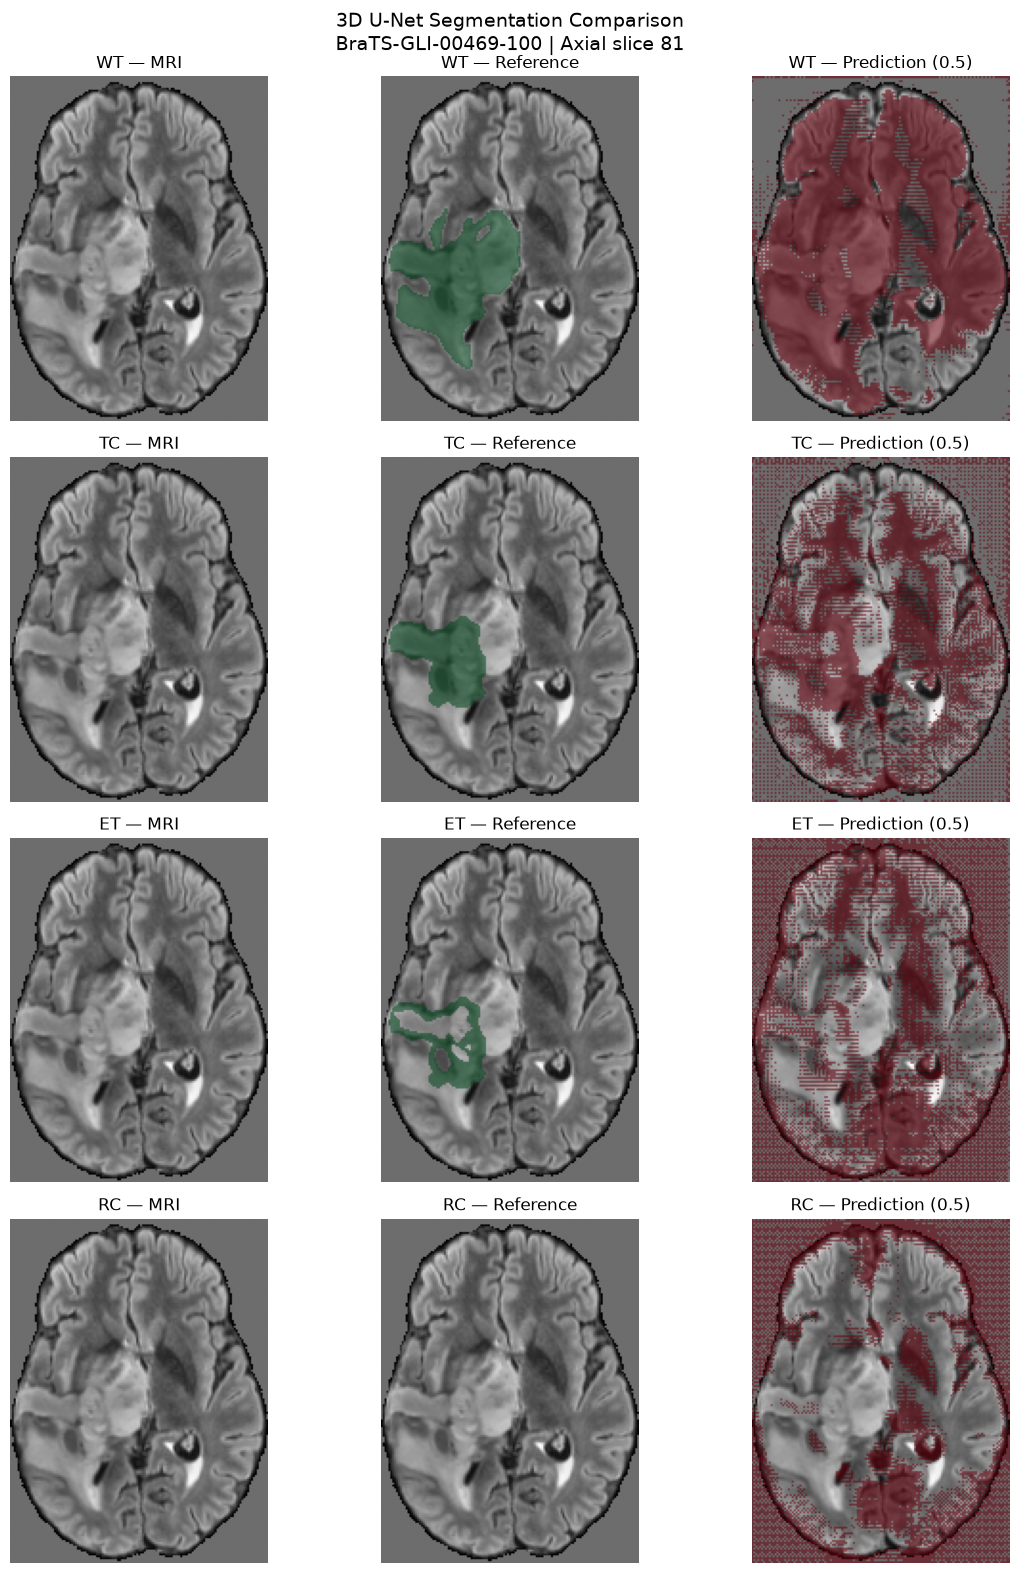


Segmentation visualisation PASSED.


In [61]:
# -------------------------------------------------------------
# SECTION 32.9 — VISUALISE SEGMENTATION PREDICTIONS
# -------------------------------------------------------------
#
# Compare reference and predicted masks on an axial MRI slice.
#
# Rows:
#   WT, TC, ET, RC
#
# Columns:
#   T2-FLAIR MRI
#   MRI + reference segmentation
#   MRI + predicted segmentation
#
# No model inference or files saved.

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# STEP 1 — TRANSFER TENSORS TO CPU
# -------------------------------------------------------------

# MRI channel order:
#   0 = T1 native
#   1 = T1 contrast
#   2 = T2 weighted
#   3 = T2 FLAIR

flair_volume = (
    selected_image[0, 3]
    .detach()
    .cpu()
    .numpy()
)

reference_masks = (
    selected_label[0]
    .detach()
    .cpu()
    .numpy()
)

predicted_masks = (
    selected_prediction[0]
    .detach()
    .cpu()
    .numpy()
)

# -------------------------------------------------------------
# STEP 2 — SELECT AN AXIAL SLICE
# -------------------------------------------------------------
#
# Choose the slice containing the greatest number of
# reference whole-tumour voxels.
#
# After RAS orientation, the third spatial axis is superior-
# inferior, so indexing [:, :, slice_index] is axial.

wt_reference = reference_masks[0]

slice_index = int(
    np.argmax(
        wt_reference.sum(axis=(0, 1))
    )
)

print("Selected axial slice:", slice_index)
print("Case ID:", selected_case_id)

# -------------------------------------------------------------
# STEP 3 — PREPARE DISPLAY
# -------------------------------------------------------------

region_names = ["WT", "TC", "ET", "RC"]

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(12, 16),
)

for region_index, region_name in enumerate(region_names):

    # Rotate for a consistent visual display.
    flair_slice = np.rot90(
        flair_volume[:, :, slice_index]
    )

    reference_slice = np.rot90(
        reference_masks[
            region_index, :, :, slice_index
        ]
    )

    prediction_slice = np.rot90(
        predicted_masks[
            region_index, :, :, slice_index
        ]
    )

    # Column 1: Original MRI
    axes[region_index, 0].imshow(
        flair_slice,
        cmap="gray",
    )

    axes[region_index, 0].set_title(
        f"{region_name} — MRI"
    )

    # Column 2: Reference overlay
    axes[region_index, 1].imshow(
        flair_slice,
        cmap="gray",
    )

    axes[region_index, 1].imshow(
        np.ma.masked_where(
            reference_slice == 0,
            reference_slice,
        ),
        cmap="Greens",
        alpha=0.55,
        vmin=0,
        vmax=1,
    )

    axes[region_index, 1].set_title(
        f"{region_name} — Reference"
    )

    # Column 3: Predicted overlay
    axes[region_index, 2].imshow(
        flair_slice,
        cmap="gray",
    )

    axes[region_index, 2].imshow(
        np.ma.masked_where(
            prediction_slice == 0,
            prediction_slice,
        ),
        cmap="Reds",
        alpha=0.55,
        vmin=0,
        vmax=1,
    )

    axes[region_index, 2].set_title(
        f"{region_name} — Prediction (0.5)"
    )

    # Remove axes for cleaner presentation.
    for column_index in range(3):
        axes[region_index, column_index].axis("off")

plt.suptitle(
    f"3D U-Net Segmentation Comparison\n"
    f"{selected_case_id} | Axial slice {slice_index}",
    fontsize=14,
)

plt.tight_layout()
plt.show()

print("\nSegmentation visualisation PASSED.")

In [62]:
# -------------------------------------------------------------
# SECTION 33.1 — AUDIT TRAINING PATCH COMPOSITION
# -------------------------------------------------------------
#
# Examine the segmentation labels in a small number of
# randomly sampled training patches.
#
# Determine:
#   - Which regions are present
#   - How many positive voxels each region contains
#   - What fraction of each patch is positive
#
# This is a diagnostic check of our existing training
# transform, not a change to the training pipeline.

import pandas as pd

region_names = ["WT", "TC", "ET", "RC"]

patch_records = []

# Sample five training cases using the existing transforms.
# Each case produces two randomly selected patches.

for case_index in range(5):

    sampled_patches = pilot_training_dataset[
        case_index
    ]

    # RandCropByPosNegLabeld with num_samples=2 returns
    # a list of dictionaries, one for each sampled patch.
    assert isinstance(sampled_patches, list)

    for patch_index, patch in enumerate(sampled_patches):

        label = patch["label"]

        assert label.shape[0] == 4

        spatial_voxels = int(
            label.shape[1]
            * label.shape[2]
            * label.shape[3]
        )

        record = {
            "Case ID": pilot_training_cases[
                case_index
            ]["case_id"],
            "Patch": patch_index + 1,
        }

        for region_index, region_name in enumerate(
            region_names
        ):

            positive_voxels = int(
                label[region_index].sum().item()
            )

            record[
                f"{region_name} %"
            ] = round(
                100 * positive_voxels / spatial_voxels,
                3,
            )

        patch_records.append(record)

patch_audit_table = pd.DataFrame(
    patch_records
)

display(patch_audit_table)

print("\nMean percentage of positive voxels:")

percentage_columns = [
    f"{region_name} %"
    for region_name in region_names
]

display(
    patch_audit_table[
        percentage_columns
    ].mean().round(3)
)

print("\nTraining patch composition audit PASSED.")

,Case ID,Patch,WT %,TC %,ET %,RC %
0,BraTS-GLI-00006-100,1,1.745,0.000,0.000,2.307
1,BraTS-GLI-00006-100,2,0.000,0.000,0.000,0.000
2,BraTS-GLI-00006-101,1,2.119,0.000,0.000,2.090
3,BraTS-GLI-00006-101,2,2.079,0.000,0.000,2.090
4,BraTS-GLI-00009-100,1,8.061,0.732,0.712,0.328
5,BraTS-GLI-00009-100,2,7.666,0.572,0.555,0.337
6,BraTS-GLI-00009-101,1,9.581,1.344,1.281,0.082
7,BraTS-GLI-00009-101,2,4.794,0.000,0.000,0.000
8,BraTS-GLI-00020-100,1,13.106,2.641,2.478,0.188
9,BraTS-GLI-00020-100,2,0.733,0.000,0.000,0.000



Mean percentage of positive voxels:


WT %    4.988
TC %    0.529
ET %    0.503
RC %    0.742
dtype: float64


Training patch composition audit PASSED.


In [66]:
# -------------------------------------------------------------
# SECTION 33.2 — INSPECT MONAI'S INTERNAL LOSS COMPONENTS
# -------------------------------------------------------------
#
# Compare:
#   1. MONAI's internal Dice component
#   2. MONAI's internal BCE component
#   3. Standalone PyTorch BCE
#   4. MONAI's complete DiceCE loss
#
# Use MONAI's own methods to avoid assuming how it reduces
# the channel dimension.
#
# No training, GPU inference, or file modifications.

import torch
import torch.nn.functional as F
import monai

from monai.losses import DiceCELoss

# -------------------------------------------------------------
# STEP 1 — RECREATE THE ORIGINAL TRAINING LOSS
# -------------------------------------------------------------

diagnostic_loss = DiceCELoss(
    include_background=True,
    to_onehot_y=False,
    sigmoid=True,
    softmax=False,
    squared_pred=False,
    smooth_nr=1e-5,
    smooth_dr=1e-5,
    lambda_dice=1.0,
    lambda_ce=1.0,
)

# -------------------------------------------------------------
# STEP 2 — CALCULATE COMPONENTS USING MONAI'S OWN METHODS
# -------------------------------------------------------------

with torch.inference_mode():

    # Internal Dice component.
    monai_dice = diagnostic_loss.dice(
        selected_logits,
        selected_label,
    )

    # Internal cross-entropy component.
    # DiceCELoss handles multichannel sigmoid predictions
    # through its BCE calculation.
    monai_bce = diagnostic_loss.ce(
        selected_logits,
        selected_label,
    )

    # Standard PyTorch BCE for comparison.
    pytorch_bce = F.binary_cross_entropy_with_logits(
        selected_logits,
        selected_label.float(),
        reduction="mean",
    )

    # Full MONAI loss.
    monai_total = diagnostic_loss(
        selected_logits,
        selected_label,
    )

    # Reconstruct using MONAI's own components.
    reconstructed_total = monai_dice + monai_bce

# -------------------------------------------------------------
# STEP 3 — DISPLAY THE RESULTS
# -------------------------------------------------------------

print("MONAI version:", monai.__version__)
print("Output shape:", tuple(selected_logits.shape))

print(f"\nMONAI Dice component:    {monai_dice.item():.8f}")
print(f"MONAI BCE component:     {monai_bce.item():.8f}")
print(f"PyTorch BCE mean:        {pytorch_bce.item():.8f}")

print(f"\nReconstructed total:     {reconstructed_total.item():.8f}")
print(f"MONAI DiceCE total:      {monai_total.item():.8f}")

print(
    "Difference:",
    abs(
        reconstructed_total.item()
        - monai_total.item()
    ),
)

print("\nLoss component inspection completed.")

MONAI version: 1.6.1
Output shape: (1, 4, 135, 180, 150)

MONAI Dice component:    0.95074117
MONAI BCE component:     0.04731169
PyTorch BCE mean:        0.81300533

Reconstructed total:     0.99805284
MONAI DiceCE total:      0.99805284
Difference: 0.0

Loss component inspection completed.


In [67]:
# -------------------------------------------------------------
# SECTION 33.3 — INSPECT MONAI DICECE IMPLEMENTATION
# -------------------------------------------------------------
#
# Examine the installed MONAI source code for:
#   1. DiceCELoss.forward()
#   2. DiceCELoss.ce()
#
# This will help explain why calling ce() directly produced
# a different result from standalone PyTorch BCE.
#
# No model execution or training.

import inspect
import monai

from monai.losses import DiceCELoss

print("MONAI version:", monai.__version__)

print("\n" + "=" * 60)
print("DiceCELoss.forward()")
print("=" * 60)

print(
    inspect.getsource(
        DiceCELoss.forward
    )
)

print("\n" + "=" * 60)
print("DiceCELoss.ce()")
print("=" * 60)

print(
    inspect.getsource(
        DiceCELoss.ce
    )
)

print("\nMONAI loss implementation inspection PASSED.")

MONAI version: 1.6.1

DiceCELoss.forward()
    def forward(self, input: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        """
        Args:
            input: the shape should be BNH[WD].
            target: the shape should be BNH[WD] or B1H[WD].

        Raises:
            ValueError: When number of dimensions for input and target are different.
            ValueError: When number of channels for target is neither 1 (without one-hot encoding) nor the same as input.

        Returns:
            torch.Tensor: value of the loss.

        """
        if input.dim() != target.dim():
            raise ValueError(
                "the number of dimensions for input and target should be the same, "
                f"got shape {input.shape} (nb dims: {len(input.shape)}) and {target.shape} (nb dims: {len(target.shape)}). "
                "if target is not one-hot encoded, please provide a tensor with shape B1H[WD]."
            )

        if target.shape[1] != 1 and target.shape[

## Section 33.4 — Identification and Correction of a Multi-Label Loss Function Error

### Background

The initial pilot employed a 3D U-Net with four sigmoid output channels representing overlapping BraTS segmentation regions:

- **WT:** Whole tumour
- **TC:** Tumour core
- **ET:** Enhancing tissue
- **RC:** Resection cavity

These regions are not mutually exclusive. For example, an enhancing tumour voxel may simultaneously belong to WT, TC and ET.

The initial training configuration used MONAI's `DiceCELoss` with `sigmoid=True`, under the assumption that its cross-entropy component would perform independent binary classification across all four channels.

### Identification of the issue

Following the pilot, quantitative evaluation demonstrated extensive oversegmentation despite decreasing training and validation losses.

Inspection of the installed MONAI 1.6.1 implementation revealed that `DiceCELoss` selects its cross-entropy calculation according to the number of output channels:

- **Single-channel output:** Binary cross-entropy
- **Multichannel output:** Categorical cross-entropy

Setting `sigmoid=True` configures the Dice component but does not change this cross-entropy selection.

Because the model produces four overlapping binary segmentation channels, categorical cross-entropy is not appropriate for the intended multi-label formulation.

### Diagnostic findings

For validation case `BraTS-GLI-00469-100`, the original loss was decomposed into:

| Component | Loss |
|---|---:|
| MONAI Dice loss | 0.950741 |
| MONAI categorical cross-entropy | 0.047312 |
| Combined DiceCE loss | 0.998053 |
| Standalone binary cross-entropy (comparison) | 0.813005 |

The combined loss was successfully reconstructed using MONAI's internal methods, confirming the behaviour of the installed implementation.

These results demonstrate a mismatch between the intended loss formulation and the implementation used during pilot training. They do not, by themselves, establish that the loss configuration was the sole cause of poor segmentation.

### Proposed correction

The revised loss will explicitly combine:

\[
\mathcal{L}_{total}
=
\mathcal{L}_{Dice}
+
\mathcal{L}_{BCEWithLogits}
\]

The Dice component will use independent sigmoid activation for each segmentation channel. Binary cross-entropy with logits will independently evaluate the four overlapping regions.

### Experimental implications

The original pilot will be retained as a documented baseline rather than overwritten.

A controlled repeat experiment will use the corrected loss while keeping the dataset split, model architecture, patch sampling strategy and training duration unchanged.

The two experiments will be compared using region-specific Dice coefficients, precision, recall and qualitative MRI overlays. Raw loss values will not be treated as directly comparable because the objective functions differ.

**Status:** Methodological issue identified; corrected loss verification and repeat training pending.

In [68]:
# -------------------------------------------------------------
# SECTION 33.4 — CORRECT MULTI-LABEL SEGMENTATION LOSS
# -------------------------------------------------------------
#
# Our segmentation targets contain four overlapping regions:
#   WT, TC, ET, RC
#
# Each output channel is an independent binary prediction.
#
# Therefore, use:
#   1. Sigmoid Dice loss
#   2. Binary cross-entropy with logits
#
# Do not use categorical cross-entropy for these targets.
#
# This cell evaluates the corrected loss without training.

import torch
import torch.nn as nn

from monai.losses import DiceLoss

# -------------------------------------------------------------
# STEP 1 — DEFINE CORRECTED LOSS COMPONENTS
# -------------------------------------------------------------

multilabel_dice_loss = DiceLoss(
    include_background=True,
    to_onehot_y=False,
    sigmoid=True,
    softmax=False,
    squared_pred=False,
    smooth_nr=1e-5,
    smooth_dr=1e-5,
    reduction="mean",
)

multilabel_bce_loss = nn.BCEWithLogitsLoss(
    reduction="mean"
)

# -------------------------------------------------------------
# STEP 2 — CALCULATE CORRECTED LOSS
# -------------------------------------------------------------

with torch.inference_mode():

    corrected_dice = multilabel_dice_loss(
        selected_logits,
        selected_label,
    )

    corrected_bce = multilabel_bce_loss(
        selected_logits,
        selected_label.float(),
    )

    corrected_total = corrected_dice + corrected_bce

# -------------------------------------------------------------
# STEP 3 — VALIDATE
# -------------------------------------------------------------

assert torch.isfinite(corrected_dice)
assert torch.isfinite(corrected_bce)
assert torch.isfinite(corrected_total)

print("Selected case:", selected_case_id)

print(f"Corrected Dice loss: {corrected_dice.item():.6f}")
print(f"Corrected BCE loss:  {corrected_bce.item():.6f}")
print(f"Corrected total:     {corrected_total.item():.6f}")

print("\nCorrected multi-label loss verification PASSED.")

Selected case: BraTS-GLI-00469-100
Corrected Dice loss: 0.950741
Corrected BCE loss:  0.813005
Corrected total:     1.763747

Corrected multi-label loss verification PASSED.


## Section 33.5 — Implementing a Reusable Multi-Label Loss Function

### Objective

Following the identification of an inappropriate categorical cross-entropy component in the original pilot training configuration, a corrected loss function was developed for the four overlapping BraTS segmentation regions: whole tumour (WT), tumour core (TC), enhancing tissue (ET), and resection cavity (RC).

The corrected objective combines sigmoid Dice loss with binary cross-entropy calculated independently for each output channel:

\[
\mathcal{L}_{total}
=
\lambda_{Dice}\mathcal{L}_{Dice}
+
\lambda_{BCE}\mathcal{L}_{BCEWithLogits}
\]

Both loss weights are initially set to 1.0.

### Implementation

The corrected loss is implemented as a reusable PyTorch `nn.Module` named `MultiLabelDiceBCELoss`, stored in `src/losses.py`.

The implementation:

- Accepts raw model logits and corresponding multi-label segmentation targets.
- Applies sigmoid internally through MONAI's Dice loss.
- Uses PyTorch's `BCEWithLogitsLoss` for independent binary classification of each segmentation region.
- Supports configurable Dice and BCE weights.
- Checks that prediction and target tensor shapes match.

Separating the loss implementation from the development notebook improves code reuse, reproducibility and maintainability.

### Verification plan

Before using the corrected loss for training, its numerical output will be compared against the independently calculated Dice and BCE components. Gradient propagation will also be tested to confirm compatibility with model optimisation.

The original pilot checkpoints will be preserved for comparison with a subsequent controlled experiment using the corrected objective.

**Status:** Corrected loss formulation verified; reusable module implementation and gradient testing pending.

In [70]:
# -------------------------------------------------------------
# SECTION 33.5 — CREATE REUSABLE MULTI-LABEL LOSS MODULE
# -------------------------------------------------------------
#
# Write a reusable loss implementation to src/losses.py.
#
# The loss combines:
#   1. MONAI sigmoid Dice loss
#   2. PyTorch binary cross-entropy with logits
#
# Designed for four overlapping BraTS segmentation regions.
#
# No model training or GPU inference.

from pathlib import Path
import textwrap

# Locate the repository root from the notebook directory.
repository_root = Path.cwd().resolve()

if repository_root.name == "notebooks":
    repository_root = repository_root.parent

assert (repository_root / "src").is_dir(), (
    "Could not locate the repository's src directory."
)

loss_module_path = repository_root / "src" / "losses.py"

# Avoid silently overwriting existing source code.
assert not loss_module_path.exists(), (
    f"File already exists: {loss_module_path}"
)

loss_module_source = textwrap.dedent('''
    """Loss functions for multi-label glioma MRI segmentation."""

    import torch
    from torch import nn
    from monai.losses import DiceLoss


    class MultiLabelDiceBCELoss(nn.Module):
        """
        Combine sigmoid Dice loss and binary cross-entropy.

        Intended for overlapping binary segmentation regions,
        such as WT, TC, ET and RC.

        Inputs:
            logits: Tensor of shape (B, C, H, W, D).
            targets: Binary tensor with the same shape.

        The input must contain raw logits, not probabilities.
        """

        def __init__(self, dice_weight=1.0, bce_weight=1.0):
            super().__init__()

            self.dice_weight = dice_weight
            self.bce_weight = bce_weight

            self.dice_loss = DiceLoss(
                include_background=True,
                to_onehot_y=False,
                sigmoid=True,
                softmax=False,
                squared_pred=False,
                smooth_nr=1e-5,
                smooth_dr=1e-5,
                reduction="mean",
            )

            self.bce_loss = nn.BCEWithLogitsLoss(
                reduction="mean"
            )

        def forward(self, logits, targets):
            """Return the weighted Dice + BCE loss."""

            if logits.shape != targets.shape:
                raise ValueError(
                    "Logits and targets must have matching shapes. "
                    f"Received {logits.shape} and {targets.shape}."
                )

            targets = targets.to(dtype=logits.dtype)

            dice = self.dice_loss(logits, targets)
            bce = self.bce_loss(logits, targets)

            return (
                self.dice_weight * dice
                + self.bce_weight * bce
            )
''').lstrip()

loss_module_path.write_text(
    loss_module_source,
    encoding="utf-8",
)

print("Created:", loss_module_path)
print("File size:", loss_module_path.stat().st_size, "bytes")
print("\nReusable multi-label loss module created successfully.")

Created: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/src/losses.py
File size: 1592 bytes

Reusable multi-label loss module created successfully.


In [71]:
# -------------------------------------------------------------
# SECTION 33.6 — VERIFY REUSABLE MULTI-LABEL LOSS MODULE
# -------------------------------------------------------------
#
# Verify that src/losses.py:
#   1. Can be imported successfully
#   2. Reproduces our independently calculated loss
#   3. Supports gradient backpropagation
#
# No model training or checkpoint modifications.

import sys
import torch

from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — LOCATE THE REPOSITORY
# -------------------------------------------------------------

repository_root = Path.cwd().resolve()

if repository_root.name == "notebooks":
    repository_root = repository_root.parent

# Make the repository's src directory importable.
source_directory = repository_root / "src"

assert source_directory.is_dir(), (
    f"Source directory not found: {source_directory}"
)

if str(source_directory) not in sys.path:
    sys.path.insert(0, str(source_directory))

# Import the corrected loss implementation.
from losses import MultiLabelDiceBCELoss

print("Imported MultiLabelDiceBCELoss successfully.")

# -------------------------------------------------------------
# STEP 2 — REPRODUCE PREVIOUS VALIDATION LOSS
# -------------------------------------------------------------

reusable_loss = MultiLabelDiceBCELoss(
    dice_weight=1.0,
    bce_weight=1.0,
).to(evaluation_device)

with torch.inference_mode():

    reusable_total = reusable_loss(
        selected_logits,
        selected_label,
    )

print(
    "\nReusable loss:",
    round(reusable_total.item(), 6),
)

print(
    "Previous corrected loss:",
    round(corrected_total.item(), 6),
)

assert torch.allclose(
    reusable_total,
    corrected_total,
    atol=1e-6,
), "Reusable loss does not match the previous calculation."

print("Numerical equivalence: PASSED")

# -------------------------------------------------------------
# STEP 3 — TEST GRADIENT PROPAGATION
# -------------------------------------------------------------
#
# Use a small synthetic example rather than a full MRI volume.
#
# The logits require gradients so we can confirm that the
# corrected loss supports backpropagation.

test_logits = torch.randn(
    (1, 4, 16, 16, 16),
    dtype=torch.float32,
    requires_grad=True,
)

# Create synthetic overlapping binary segmentation targets.
# Multiple channels can be positive at the same voxel.
test_targets = torch.zeros_like(test_logits)

test_targets[:, 0, 4:12, 4:12, 4:12] = 1.0
test_targets[:, 1, 6:10, 6:10, 6:10] = 1.0
test_targets[:, 2, 7:9, 7:9, 7:9] = 1.0
test_targets[:, 3, 2:5, 2:5, 2:5] = 1.0

# Create a CPU loss instance for this lightweight test.
test_loss_function = MultiLabelDiceBCELoss()

test_loss = test_loss_function(
    test_logits,
    test_targets,
)

# Compute gradients with respect to the logits.
test_loss.backward()

# -------------------------------------------------------------
# STEP 4 — VERIFY GRADIENTS
# -------------------------------------------------------------

assert test_logits.grad is not None, (
    "No gradients were generated."
)

assert torch.isfinite(test_logits.grad).all(), (
    "Gradients contain NaN or infinity."
)

assert test_logits.grad.abs().sum() > 0, (
    "All gradients are zero."
)

print(
    "\nSynthetic test loss:",
    round(test_loss.item(), 6),
)

print(
    "Mean absolute gradient:",
    test_logits.grad.abs().mean().item(),
)

print("Gradient propagation: PASSED")

print("\nReusable multi-label loss verification PASSED.")

Imported MultiLabelDiceBCELoss successfully.

Reusable loss: 1.763747
Previous corrected loss: 1.763747
Numerical equivalence: PASSED

Synthetic test loss: 1.7412
Mean absolute gradient: 3.307575389044359e-05
Gradient propagation: PASSED

Reusable multi-label loss verification PASSED.


## Section 34 — Controlled Repeat Pilot Using Corrected Multi-Label Loss

In [72]:
# -------------------------------------------------------------
# SECTION 34.1 — PREPARE CORRECTED LOSS EXPERIMENT
# -------------------------------------------------------------
#
# Create a new experiment directory on the WSL filesystem.
#
# Preserve the original pilot experiment and its checkpoints.
#
# This cell does not start training or allocate GPU memory.

from pathlib import Path
from datetime import datetime
import json

# -------------------------------------------------------------
# STEP 1 — DEFINE EXPERIMENT LOCATION
# -------------------------------------------------------------

experiment_root = (
    Path.home()
    / "experiments"
    / "glioma-mri-segmentation"
)

# Create a unique identifier for the corrected experiment.
corrected_experiment_id = (
    "pilot_multilabel_dice_bce_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

corrected_experiment_directory = (
    experiment_root / corrected_experiment_id
)

corrected_checkpoint_directory = (
    corrected_experiment_directory / "checkpoints"
)

corrected_log_directory = (
    corrected_experiment_directory / "logs"
)

# Refuse to reuse an existing experiment directory.
assert not corrected_experiment_directory.exists(), (
    "Experiment directory already exists."
)

corrected_checkpoint_directory.mkdir(
    parents=True,
    exist_ok=False,
)

corrected_log_directory.mkdir(
    parents=True,
    exist_ok=False,
)

# -------------------------------------------------------------
# STEP 2 — DOCUMENT EXPERIMENT CONFIGURATION
# -------------------------------------------------------------

corrected_pilot_config = {
    "experiment_id": corrected_experiment_id,
    "experiment_type": "corrected_loss_pilot",
    "training_cases": 24,
    "validation_cases": 4,
    "epochs": 10,
    "patch_size": [96, 96, 96],
    "patches_per_case": 2,
    "batch_size": 1,
    "optimizer": "AdamW",
    "learning_rate": 1e-4,
    "weight_decay": 1e-5,
    "loss": "MultiLabelDiceBCELoss",
    "dice_weight": 1.0,
    "bce_weight": 1.0,
    "random_seed": 42,
    "baseline_experiment": str(experiment_directory),
}

corrected_config_path = (
    corrected_experiment_directory / "config.json"
)

with corrected_config_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        corrected_pilot_config,
        file,
        indent=2,
    )

# -------------------------------------------------------------
# STEP 3 — VERIFY EXPERIMENT DIRECTORY
# -------------------------------------------------------------

assert corrected_config_path.is_file()
assert corrected_checkpoint_directory.is_dir()
assert corrected_log_directory.is_dir()

print("Corrected experiment:", corrected_experiment_id)
print("Experiment directory:", corrected_experiment_directory)
print("Checkpoint directory:", corrected_checkpoint_directory)
print("Log directory:", corrected_log_directory)
print("Configuration saved:", corrected_config_path)

print("\nCorrected pilot experiment preparation PASSED.")

Corrected experiment: pilot_multilabel_dice_bce_20261013_010546
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546
Checkpoint directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/checkpoints
Log directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs
Configuration saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/config.json

Corrected pilot experiment preparation PASSED.


In [73]:
# -------------------------------------------------------------
# SECTION 34.2 — VERIFY CORRECTED PILOT CONFIGURATION
# -------------------------------------------------------------
#
# Check that the corrected experiment is ready for training.
#
# This cell:
#   - Verifies the dataset sizes
#   - Confirms subject-level separation
#   - Checks the corrected loss class
#   - Verifies experiment directories
#   - Checks GPU availability
#
# No training or GPU-intensive inference is performed.

import torch

from losses import MultiLabelDiceBCELoss

# -------------------------------------------------------------
# STEP 1 — VERIFY DATASET SIZES
# -------------------------------------------------------------

assert len(pilot_training_cases) == 24
assert len(pilot_validation_cases) == 4

assert len(pilot_training_dataset) == 24
assert len(pilot_validation_dataset) == 4

print("Training cases:", len(pilot_training_cases))
print("Validation cases:", len(pilot_validation_cases))

# -------------------------------------------------------------
# STEP 2 — VERIFY SUBJECT-LEVEL SEPARATION
# -------------------------------------------------------------

training_subjects = {
    case["subject_id"]
    for case in pilot_training_cases
}

validation_subjects = {
    case["subject_id"]
    for case in pilot_validation_cases
}

overlapping_subjects = (
    training_subjects & validation_subjects
)

assert len(overlapping_subjects) == 0, (
    f"Subject leakage detected: {overlapping_subjects}"
)

print("Subject-level overlap:", len(overlapping_subjects))

# -------------------------------------------------------------
# STEP 3 — VERIFY LOSS FUNCTION
# -------------------------------------------------------------

corrected_loss_function = MultiLabelDiceBCELoss(
    dice_weight=1.0,
    bce_weight=1.0,
)

assert isinstance(
    corrected_loss_function,
    torch.nn.Module,
)

print(
    "Corrected loss:",
    type(corrected_loss_function).__name__,
)

# -------------------------------------------------------------
# STEP 4 — VERIFY EXPERIMENT PATHS
# -------------------------------------------------------------

assert corrected_experiment_directory.is_dir()
assert corrected_checkpoint_directory.is_dir()
assert corrected_log_directory.is_dir()
assert corrected_config_path.is_file()

print("Experiment directory:", corrected_experiment_directory)

# -------------------------------------------------------------
# STEP 5 — VERIFY COMPUTE DEVICE
# -------------------------------------------------------------

assert torch.cuda.is_available(), (
    "CUDA is unavailable. Check the glioma-ml environment."
)

print("GPU:", torch.cuda.get_device_name(0))

# -------------------------------------------------------------
# STEP 6 — VERIFY CONFIGURATION
# -------------------------------------------------------------

assert corrected_pilot_config["loss"] == (
    "MultiLabelDiceBCELoss"
)

assert corrected_pilot_config["epochs"] == 10
assert corrected_pilot_config["random_seed"] == 42

print("Configured epochs:", corrected_pilot_config["epochs"])
print("Configured random seed:", corrected_pilot_config["random_seed"])

print("\nCorrected pilot pre-training verification PASSED.")

Training cases: 24
Validation cases: 4
Subject-level overlap: 0
Corrected loss: MultiLabelDiceBCELoss
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546
GPU: NVIDIA GeForce RTX 4080 SUPER
Configured epochs: 10
Configured random seed: 42

Corrected pilot pre-training verification PASSED.


In [74]:
# -------------------------------------------------------------
# SECTION 34.3 — INITIALISE CORRECTED PILOT
# -------------------------------------------------------------
#
# Prepare a fresh 3D U-Net for the corrected-loss experiment.
#
# Keep the original pilot architecture and optimiser settings.
#
# Changes from the original pilot:
#   - Explicit random seed
#   - Corrected MultiLabelDiceBCELoss
#
# This cell does not start training or save checkpoints.

import random
import numpy as np
import torch

from monai.networks.nets import UNet
from monai.utils import set_determinism

from losses import MultiLabelDiceBCELoss

# -------------------------------------------------------------
# STEP 1 — SET RANDOM SEEDS
# -------------------------------------------------------------
#
# Set seeds before initialising the new network.
#
# MONAI's set_determinism also configures deterministic
# behaviour where supported. Some GPU operations may still
# have platform-dependent limitations.

training_seed = corrected_pilot_config["random_seed"]

random.seed(training_seed)
np.random.seed(training_seed)
torch.manual_seed(training_seed)
torch.cuda.manual_seed_all(training_seed)

set_determinism(seed=training_seed)

print("Random seed:", training_seed)

# -------------------------------------------------------------
# STEP 2 — INITIALISE FRESH 3D U-NET
# -------------------------------------------------------------

corrected_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(evaluation_device)

# -------------------------------------------------------------
# STEP 3 — INITIALISE CORRECTED LOSS
# -------------------------------------------------------------

corrected_training_loss = MultiLabelDiceBCELoss(
    dice_weight=1.0,
    bce_weight=1.0,
).to(evaluation_device)

# -------------------------------------------------------------
# STEP 4 — INITIALISE OPTIMISER
# -------------------------------------------------------------

corrected_optimizer = torch.optim.AdamW(
    corrected_model.parameters(),
    lr=corrected_pilot_config["learning_rate"],
    weight_decay=corrected_pilot_config["weight_decay"],
)

# -------------------------------------------------------------
# STEP 5 — VERIFY MODEL CONFIGURATION
# -------------------------------------------------------------

corrected_parameter_count = sum(
    parameter.numel()
    for parameter in corrected_model.parameters()
    if parameter.requires_grad
)

assert corrected_parameter_count == 4_811_129, (
    "Corrected model architecture differs from original pilot."
)

assert corrected_model.training, (
    "Model should be in training mode."
)

print("Model:", type(corrected_model).__name__)
print("Trainable parameters:", f"{corrected_parameter_count:,}")
print("Device:", next(corrected_model.parameters()).device)
print("Loss:", type(corrected_training_loss).__name__)
print("Optimiser:", type(corrected_optimizer).__name__)

print("\nCorrected pilot initialisation PASSED.")

Random seed: 42
Model: UNet
Trainable parameters: 4,811,129
Device: cuda:0
Loss: MultiLabelDiceBCELoss
Optimiser: AdamW

Corrected pilot initialisation PASSED.


In [75]:
# -------------------------------------------------------------
# SECTION 34.4 — CORRECTED MULTI-LABEL PILOT TRAINING
# -------------------------------------------------------------
#
# Train a fresh 3D U-Net using the corrected Dice + BCE loss.
#
# Features:
#   - 10 training epochs
#   - Full-volume sliding-window validation
#   - CSV training history
#   - Checkpoint after every epoch
#   - Rolling recovery checkpoint every 5 batches
#   - Maximum runtime safeguard
#
# This is a GPU-intensive operation.
#
# IMPORTANT:
# Do not rerun Cell 57 after training begins.
# Do not rerun this cell without deciding whether to resume
# or restart, as the model and optimiser retain their state.

import csv
import json
import time
from datetime import datetime

import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — CONFIGURATION
# -------------------------------------------------------------

maximum_epochs = corrected_pilot_config["epochs"]
maximum_runtime_seconds = 150 * 60

validation_roi_size = tuple(
    corrected_pilot_config["patch_size"]
)

training_history_path = (
    corrected_log_directory / "training_history.csv"
)

training_summary_path = (
    corrected_experiment_directory / "training_summary.json"
)

recovery_checkpoint_path = (
    corrected_checkpoint_directory / "recovery_latest.pt"
)

final_checkpoint_path_corrected = (
    corrected_checkpoint_directory / "final_latest.pt"
)

# Prevent accidental overwriting of a completed experiment.
assert not training_history_path.exists(), (
    "Training history already exists. "
    "Do not restart without reviewing the existing experiment."
)

assert not final_checkpoint_path_corrected.exists(), (
    "Final checkpoint already exists."
)

# -------------------------------------------------------------
# STEP 2 — CHECKPOINT HELPER
# -------------------------------------------------------------

def save_corrected_checkpoint(path, epoch, batch, status):
    """
    Save the complete training state for reproducibility
    and possible recovery.
    """

    checkpoint = {
        "epoch": epoch,
        "batch": batch,
        "status": status,
        "model_state_dict": corrected_model.state_dict(),
        "optimizer_state_dict": corrected_optimizer.state_dict(),
        "experiment_id": corrected_experiment_id,
        "loss_name": "MultiLabelDiceBCELoss",
        "saved_at": datetime.now().isoformat(),
    }

    # Write to a temporary file before replacing the target.
    temporary_path = path.with_suffix(".tmp")

    torch.save(checkpoint, temporary_path)
    temporary_path.replace(path)


# -------------------------------------------------------------
# STEP 3 — PREPARE TRAINING HISTORY
# -------------------------------------------------------------

history_fields = [
    "epoch",
    "training_loss",
    "validation_loss",
    "elapsed_minutes",
]

with training_history_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=history_fields,
    )

    writer.writeheader()

# -------------------------------------------------------------
# STEP 4 — TRAINING LOOP
# -------------------------------------------------------------

experiment_start = time.monotonic()

completed_epochs = 0
stop_reason = "maximum_epochs_completed"

print("Starting corrected pilot training...")
print("Experiment:", corrected_experiment_id)
print("Device:", evaluation_device)

for epoch in range(1, maximum_epochs + 1):

    # ---------------------------------------------------------
    # TRAINING PHASE
    # ---------------------------------------------------------

    corrected_model.train()

    epoch_training_loss = 0.0
    training_batches = 0

    for batch_index, batch in enumerate(
        pilot_training_loader,
        start=1,
    ):

        # The training transform generates two patches
        # per case. The DataLoader combines them into
        # a batch of shape (2, 4, 96, 96, 96).

        images = batch["image"].to(evaluation_device)
        labels = batch["label"].to(evaluation_device)

        corrected_optimizer.zero_grad(set_to_none=True)

        logits = corrected_model(images)

        loss = corrected_training_loss(
            logits,
            labels,
        )

        if not bool(torch.isfinite(loss)):
            raise RuntimeError(
                f"Non-finite training loss at "
                f"epoch {epoch}, batch {batch_index}."
            )

        loss.backward()
        corrected_optimizer.step()

        epoch_training_loss += loss.item()
        training_batches += 1

        # Save a recovery checkpoint every five batches.
        if batch_index % 5 == 0:

            save_corrected_checkpoint(
                recovery_checkpoint_path,
                epoch,
                batch_index,
                "training_in_progress",
            )

        # Stop cooperatively if runtime is exceeded.
        if (
            time.monotonic() - experiment_start
            >= maximum_runtime_seconds
        ):
            stop_reason = "runtime_limit_reached"
            break

    if training_batches == 0:
        raise RuntimeError("No training batches processed.")

    mean_training_loss = (
        epoch_training_loss / training_batches
    )

    # ---------------------------------------------------------
    # VALIDATION PHASE
    # ---------------------------------------------------------

    corrected_model.eval()

    validation_loss_total = 0.0
    validation_batches = 0

    with torch.inference_mode():

        for validation_batch in pilot_validation_loader:

            validation_images = (
                validation_batch["image"]
                .to(evaluation_device)
            )

            validation_labels = (
                validation_batch["label"]
                .to(evaluation_device)
            )

            validation_logits = sliding_window_inference(
                inputs=validation_images,
                roi_size=validation_roi_size,
                sw_batch_size=1,
                predictor=corrected_model,
                overlap=0.25,
                mode="constant",
            )

            validation_loss = corrected_training_loss(
                validation_logits,
                validation_labels,
            )

            if not bool(torch.isfinite(validation_loss)):
                raise RuntimeError(
                    f"Non-finite validation loss "
                    f"at epoch {epoch}."
                )

            validation_loss_total += validation_loss.item()
            validation_batches += 1

    mean_validation_loss = (
        validation_loss_total / validation_batches
    )

    completed_epochs = epoch

    elapsed_minutes = (
        time.monotonic() - experiment_start
    ) / 60

    # ---------------------------------------------------------
    # LOG EPOCH RESULTS
    # ---------------------------------------------------------

    history_record = {
        "epoch": epoch,
        "training_loss": mean_training_loss,
        "validation_loss": mean_validation_loss,
        "elapsed_minutes": elapsed_minutes,
    }

    with training_history_path.open(
        "a",
        newline="",
        encoding="utf-8",
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=history_fields,
        )

        writer.writerow(history_record)

    # ---------------------------------------------------------
    # SAVE EPOCH CHECKPOINT
    # ---------------------------------------------------------

    epoch_checkpoint_path = (
        corrected_checkpoint_directory
        / f"epoch_{epoch:03d}.pt"
    )

    save_corrected_checkpoint(
        epoch_checkpoint_path,
        epoch,
        training_batches,
        "epoch_completed",
    )

    print(
        f"Epoch {epoch:02d}/{maximum_epochs} | "
        f"Train: {mean_training_loss:.4f} | "
        f"Val: {mean_validation_loss:.4f} | "
        f"Elapsed: {elapsed_minutes:.2f} min"
    )

    if (
        time.monotonic() - experiment_start
        >= maximum_runtime_seconds
    ):
        stop_reason = "runtime_limit_reached"

    if stop_reason == "runtime_limit_reached":
        break

# -------------------------------------------------------------
# STEP 5 — SAVE FINAL CHECKPOINT
# -------------------------------------------------------------

save_corrected_checkpoint(
    final_checkpoint_path_corrected,
    completed_epochs,
    training_batches,
    stop_reason,
)

# -------------------------------------------------------------
# STEP 6 — SAVE EXPERIMENT SUMMARY
# -------------------------------------------------------------

training_summary = {
    "experiment_id": corrected_experiment_id,
    "completed_epochs": completed_epochs,
    "requested_epochs": maximum_epochs,
    "stop_reason": stop_reason,
    "elapsed_minutes": (
        time.monotonic() - experiment_start
    ) / 60,
    "loss": "MultiLabelDiceBCELoss",
    "final_checkpoint": str(final_checkpoint_path_corrected),
}

with training_summary_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        training_summary,
        file,
        indent=2,
    )

print("\nCorrected pilot training finished.")
print("Completed epochs:", completed_epochs)
print("Stop reason:", stop_reason)
print("Final checkpoint:", final_checkpoint_path_corrected)
print("Summary:", training_summary_path)

Starting corrected pilot training...
Experiment: pilot_multilabel_dice_bce_20261013_010546
Device: cuda:0
Epoch 01/10 | Train: 1.8059 | Val: 1.7435 | Elapsed: 0.25 min
Epoch 02/10 | Train: 1.7371 | Val: 1.7145 | Elapsed: 0.50 min
Epoch 03/10 | Train: 1.7016 | Val: 1.6964 | Elapsed: 0.75 min
Epoch 04/10 | Train: 1.6843 | Val: 1.6837 | Elapsed: 0.98 min
Epoch 05/10 | Train: 1.6622 | Val: 1.6702 | Elapsed: 1.21 min
Epoch 06/10 | Train: 1.6535 | Val: 1.6517 | Elapsed: 1.45 min
Epoch 07/10 | Train: 1.6234 | Val: 1.6205 | Elapsed: 1.68 min
Epoch 08/10 | Train: 1.5986 | Val: 1.5752 | Elapsed: 1.91 min
Epoch 09/10 | Train: 1.5663 | Val: 1.5275 | Elapsed: 2.15 min
Epoch 10/10 | Train: 1.5251 | Val: 1.4854 | Elapsed: 2.38 min

Corrected pilot training finished.
Completed epochs: 10
Stop reason: maximum_epochs_completed
Final checkpoint: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/checkpoints/final_latest.pt
Summary: /home/corvus_splendens/

In [76]:
# -------------------------------------------------------------
# SECTION 34.5 — VERIFY CORRECTED PILOT OUTPUTS
# -------------------------------------------------------------
#
# Confirm that training completed successfully and that
# checkpoints, history and experiment metadata were saved.
#
# This cell does not run model training or inference.

import csv
import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — VERIFY EXPECTED OUTPUT FILES
# -------------------------------------------------------------

corrected_final_checkpoint = (
    corrected_checkpoint_directory / "final_latest.pt"
)

corrected_history_file = (
    corrected_log_directory / "training_history.csv"
)

corrected_summary_file = (
    corrected_experiment_directory / "training_summary.json"
)

expected_files = [
    corrected_final_checkpoint,
    corrected_history_file,
    corrected_summary_file,
    corrected_config_path,
]

for file_path in expected_files:
    assert file_path.is_file(), (
        f"Missing experiment file: {file_path}"
    )

    print(
        f"{file_path.name}: "
        f"{file_path.stat().st_size / (1024 ** 2):.3f} MiB"
    )

# -------------------------------------------------------------
# STEP 2 — VERIFY TRAINING SUMMARY
# -------------------------------------------------------------

with corrected_summary_file.open(
    "r",
    encoding="utf-8",
) as file:
    corrected_summary = json.load(file)

assert corrected_summary["completed_epochs"] == 10
assert corrected_summary["stop_reason"] == (
    "maximum_epochs_completed"
)

assert corrected_summary["loss"] == (
    "MultiLabelDiceBCELoss"
)

print(
    "\nCompleted epochs:",
    corrected_summary["completed_epochs"],
)

print(
    "Stop reason:",
    corrected_summary["stop_reason"],
)

# -------------------------------------------------------------
# STEP 3 — VERIFY TRAINING HISTORY
# -------------------------------------------------------------

with corrected_history_file.open(
    "r",
    newline="",
    encoding="utf-8",
) as file:

    corrected_history = list(
        csv.DictReader(file)
    )

assert len(corrected_history) == 10, (
    "Expected 10 epoch history records."
)

first_epoch = corrected_history[0]
last_epoch = corrected_history[-1]

assert int(first_epoch["epoch"]) == 1
assert int(last_epoch["epoch"]) == 10

print("\nLogged epochs:", len(corrected_history))

print(
    "First validation loss:",
    round(float(first_epoch["validation_loss"]), 6),
)

print(
    "Final validation loss:",
    round(float(last_epoch["validation_loss"]), 6),
)

# -------------------------------------------------------------
# STEP 4 — VERIFY EPOCH CHECKPOINT COUNT
# -------------------------------------------------------------

epoch_checkpoints = sorted(
    corrected_checkpoint_directory.glob("epoch_*.pt")
)

assert len(epoch_checkpoints) == 10, (
    "Expected one checkpoint per completed epoch."
)

print(
    "\nEpoch checkpoints:",
    len(epoch_checkpoints),
)

print(
    "Final checkpoint:",
    corrected_final_checkpoint,
)

print("\nCorrected pilot output verification PASSED.")

final_latest.pt: 55.141 MiB
training_history.csv: 0.001 MiB
training_summary.json: 0.000 MiB
config.json: 0.001 MiB

Completed epochs: 10
Stop reason: maximum_epochs_completed

Logged epochs: 10
First validation loss: 1.743531
Final validation loss: 1.485445

Epoch checkpoints: 10
Final checkpoint: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/checkpoints/final_latest.pt

Corrected pilot output verification PASSED.


## Section 35 — Comparative Evaluation of Original and Corrected Loss Functions

In [77]:
# -------------------------------------------------------------
# SECTION 35.1 — LOAD CORRECTED PILOT MODEL
# -------------------------------------------------------------
#
# Load the corrected model from its saved final checkpoint.
#
# Verify:
#   1. Checkpoint metadata
#   2. Model architecture compatibility
#   3. Parameter integrity
#   4. Evaluation mode
#
# This cell does not run training or full-volume inference.

import torch

from monai.networks.nets import UNet

# -------------------------------------------------------------
# STEP 1 — LOAD CHECKPOINT
# -------------------------------------------------------------
#
# Load onto CPU first to avoid unnecessary GPU memory use.

corrected_checkpoint = torch.load(
    corrected_final_checkpoint,
    map_location="cpu",
    weights_only=True,
)

assert corrected_checkpoint["epoch"] == 10

assert corrected_checkpoint["loss_name"] == (
    "MultiLabelDiceBCELoss"
)

assert corrected_checkpoint["status"] == (
    "maximum_epochs_completed"
)

print("Checkpoint epoch:", corrected_checkpoint["epoch"])
print("Checkpoint loss:", corrected_checkpoint["loss_name"])
print("Checkpoint status:", corrected_checkpoint["status"])

# -------------------------------------------------------------
# STEP 2 — RECONSTRUCT MODEL ARCHITECTURE
# -------------------------------------------------------------
#
# Use exactly the same architecture as both pilot runs.

corrected_evaluation_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
)

# Strict loading verifies that parameter names and tensor
# dimensions match the saved checkpoint.

corrected_evaluation_model.load_state_dict(
    corrected_checkpoint["model_state_dict"],
    strict=True,
)

# -------------------------------------------------------------
# STEP 3 — VERIFY PARAMETER INTEGRITY
# -------------------------------------------------------------

for parameter_name, parameter in (
    corrected_evaluation_model.named_parameters()
):

    assert torch.isfinite(parameter).all(), (
        f"Non-finite parameters detected: {parameter_name}"
    )

# -------------------------------------------------------------
# STEP 4 — MOVE MODEL TO EVALUATION DEVICE
# -------------------------------------------------------------

corrected_evaluation_model = (
    corrected_evaluation_model.to(evaluation_device)
)

corrected_evaluation_model.eval()

assert not corrected_evaluation_model.training

corrected_parameter_count = sum(
    parameter.numel()
    for parameter in corrected_evaluation_model.parameters()
    if parameter.requires_grad
)

assert corrected_parameter_count == 4_811_129

print("\nEvaluation device:", evaluation_device)
print("Trainable parameters:", f"{corrected_parameter_count:,}")
print("Evaluation mode:", not corrected_evaluation_model.training)

print("\nCorrected model checkpoint verification PASSED.")

Checkpoint epoch: 10
Checkpoint loss: MultiLabelDiceBCELoss
Checkpoint status: maximum_epochs_completed

Evaluation device: cuda:0
Trainable parameters: 4,811,129
Evaluation mode: True

Corrected model checkpoint verification PASSED.


In [78]:
# -------------------------------------------------------------
# SECTION 35.2 — COMPARE ORIGINAL AND CORRECTED MODELS
# -------------------------------------------------------------
#
# Evaluate both trained models on the same four validation
# cases using identical inference and segmentation settings.
#
# Metrics:
#   - Dice similarity coefficient
#   - Precision
#   - Recall
#   - Predicted voxel count
#   - Reference voxel count
#
# For absent reference regions, Dice and recall are NaN.
#
# This cell performs GPU inference but NO training.

import csv
import math
import time

import numpy as np
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — VERIFY EVALUATION MODELS
# -------------------------------------------------------------

assert not evaluation_model.training
assert not corrected_evaluation_model.training

evaluation_models = {
    "original_dice_ce": evaluation_model,
    "corrected_dice_bce": corrected_evaluation_model,
}

region_names = ("WT", "TC", "ET", "RC")
probability_threshold = 0.5

comparison_results = []

# -------------------------------------------------------------
# STEP 2 — DEFINE METRIC CALCULATION
# -------------------------------------------------------------

def calculate_binary_metrics(prediction, reference):
    """
    Calculate binary segmentation metrics.

    When the reference is empty, Dice and recall are NaN
    because the target region is absent.

    Precision is NaN when there are no predicted positives.
    """

    prediction = prediction.astype(bool)
    reference = reference.astype(bool)

    true_positive = np.logical_and(
        prediction, reference
    ).sum()

    false_positive = np.logical_and(
        prediction, ~reference
    ).sum()

    false_negative = np.logical_and(
        ~prediction, reference
    ).sum()

    predicted_voxels = int(prediction.sum())
    reference_voxels = int(reference.sum())

    if reference_voxels == 0:
        dice = float("nan")
        recall = float("nan")
    else:
        dice = (
            2 * true_positive
            / (2 * true_positive + false_positive + false_negative)
        )

        recall = true_positive / reference_voxels

    if predicted_voxels == 0:
        precision = float("nan")
    else:
        precision = true_positive / predicted_voxels

    return {
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "predicted_voxels": predicted_voxels,
        "reference_voxels": reference_voxels,
    }


# -------------------------------------------------------------
# STEP 3 — RUN FULL-VOLUME INFERENCE
# -------------------------------------------------------------

comparison_start = time.monotonic()

for case_index, validation_case in enumerate(
    pilot_validation_cases
):

    case_id = validation_case["case_id"]

    # Use the same validation preprocessing as the pilot.
    validation_sample = pilot_validation_dataset[
        case_index
    ]

    image = validation_sample["image"].unsqueeze(0)
    reference = validation_sample["label"]

    # Keep the reference masks on CPU for metric calculation.
    reference_np = reference.cpu().numpy()

    print(
        f"\nCase {case_index + 1}/4: {case_id}"
    )

    for model_name, model in evaluation_models.items():

        model.eval()

        with torch.inference_mode():

            image_gpu = image.to(evaluation_device)

            logits = sliding_window_inference(
                inputs=image_gpu,
                roi_size=(96, 96, 96),
                sw_batch_size=1,
                predictor=model,
                overlap=0.25,
                mode="constant",
            )

            probabilities = torch.sigmoid(logits)

            prediction = (
                probabilities >= probability_threshold
            )

            prediction_np = (
                prediction[0]
                .cpu()
                .numpy()
            )

        # Calculate metrics for each binary region.
        for region_index, region_name in enumerate(
            region_names
        ):

            metrics = calculate_binary_metrics(
                prediction_np[region_index],
                reference_np[region_index],
            )

            comparison_results.append({
                "case_id": case_id,
                "model": model_name,
                "region": region_name,
                **metrics,
            })

        print(
            f"  {model_name}: inference completed"
        )

# -------------------------------------------------------------
# STEP 4 — SAVE COMPARISON RESULTS
# -------------------------------------------------------------

comparison_csv_path = (
    corrected_log_directory
    / "original_vs_corrected_metrics.csv"
)

comparison_fields = [
    "case_id",
    "model",
    "region",
    "dice",
    "precision",
    "recall",
    "predicted_voxels",
    "reference_voxels",
]

with comparison_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=comparison_fields,
    )

    writer.writeheader()
    writer.writerows(comparison_results)

# -------------------------------------------------------------
# STEP 5 — SUMMARISE REGION-SPECIFIC DICE
# -------------------------------------------------------------

print("\n" + "=" * 65)
print("MEAN DICE — CASES WITH REGION PRESENT")
print("=" * 65)

for region_name in region_names:

    print(f"\n{region_name}")

    for model_name in evaluation_models:

        region_dice = [
            result["dice"]
            for result in comparison_results
            if result["region"] == region_name
            and result["model"] == model_name
            and math.isfinite(result["dice"])
        ]

        mean_dice = (
            float(np.mean(region_dice))
            if region_dice
            else float("nan")
        )

        print(
            f"  {model_name}: "
            f"{mean_dice:.4f} "
            f"(n={len(region_dice)})"
        )

elapsed_minutes = (
    time.monotonic() - comparison_start
) / 60

print("\nTotal evaluation time:", round(elapsed_minutes, 2), "min")
print("Results saved:", comparison_csv_path)
print("\nComparative evaluation completed.")


Case 1/4: BraTS-GLI-00033-100
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

Case 2/4: BraTS-GLI-00033-101
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

Case 3/4: BraTS-GLI-00469-100
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

Case 4/4: BraTS-GLI-00469-101
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

MEAN DICE — CASES WITH REGION PRESENT

WT
  original_dice_ce: 0.0906 (n=4)
  corrected_dice_bce: 0.1315 (n=4)

TC
  original_dice_ce: 0.0242 (n=2)
  corrected_dice_bce: 0.0935 (n=2)

ET
  original_dice_ce: 0.0091 (n=2)
  corrected_dice_bce: 0.0553 (n=2)

RC
  original_dice_ce: 0.0394 (n=3)
  corrected_dice_bce: 0.1411 (n=3)

Total evaluation time: 0.05 min
Results saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/original_vs_corrected_metrics.csv

Comparative evaluation completed

In [79]:
# -------------------------------------------------------------
# SECTION 35.3 — PRECISION, RECALL AND VOLUME ANALYSIS
# -------------------------------------------------------------
#
# Investigate whether the corrected model reduces the
# excessive positive predictions seen in the original pilot.
#
# Only cases with a reference region present are included
# in the volume-ratio and precision/recall summaries.
#
# No GPU operations are performed.

import math
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — LOAD SAVED COMPARISON RESULTS
# -------------------------------------------------------------

comparison_df = pd.read_csv(
    comparison_csv_path
)

expected_columns = {
    "case_id",
    "model",
    "region",
    "dice",
    "precision",
    "recall",
    "predicted_voxels",
    "reference_voxels",
}

assert expected_columns.issubset(
    comparison_df.columns
)

print(
    "Comparison records:",
    len(comparison_df)
)

# -------------------------------------------------------------
# STEP 2 — CALCULATE PREDICTED/REFERENCE VOLUME RATIO
# -------------------------------------------------------------

comparison_df["volume_ratio"] = np.where(
    comparison_df["reference_voxels"] > 0,
    comparison_df["predicted_voxels"]
    / comparison_df["reference_voxels"].replace(0, np.nan),
    np.nan,
)

# -------------------------------------------------------------
# STEP 3 — SUMMARISE CASES WITH PRESENT REGIONS
# -------------------------------------------------------------

present_region_df = comparison_df[
    comparison_df["reference_voxels"] > 0
].copy()

summary_df = (
    present_region_df
    .groupby(["region", "model"], as_index=False)
    .agg(
        cases=("case_id", "count"),
        mean_dice=("dice", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_volume_ratio=("volume_ratio", "mean"),
    )
)

# Order the results consistently.
summary_df["region"] = pd.Categorical(
    summary_df["region"],
    categories=["WT", "TC", "ET", "RC"],
    ordered=True,
)

summary_df = summary_df.sort_values(
    ["region", "model"]
)

print("\nREGION-SPECIFIC COMPARISON")
print(
    summary_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}",
    )
)

# -------------------------------------------------------------
# STEP 4 — INSPECT ABSENT REGIONS
# -------------------------------------------------------------
#
# A region absent from the reference should ideally also
# be absent from the prediction.
#
# These cases were excluded from mean Dice calculations,
# so we examine their false-positive voxel counts separately.

absent_region_df = comparison_df[
    comparison_df["reference_voxels"] == 0
].copy()

print("\nFALSE POSITIVES IN ABSENT REGIONS")

print(
    absent_region_df[
        [
            "case_id",
            "model",
            "region",
            "predicted_voxels",
        ]
    ].to_string(index=False)
)

# -------------------------------------------------------------
# STEP 5 — SAVE ANALYSIS
# -------------------------------------------------------------

summary_path = (
    corrected_log_directory
    / "region_precision_recall_volume_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False,
)

print("\nSummary saved:", summary_path)
print("Precision, recall and volume analysis PASSED.")

Comparison records: 32

REGION-SPECIFIC COMPARISON
region              model  cases  mean_dice  mean_precision  mean_recall  mean_volume_ratio
    WT corrected_dice_bce      4     0.1315          0.0751       0.9905            31.2861
    WT   original_dice_ce      4     0.0906          0.0496       0.9968            45.9656
    TC corrected_dice_bce      2     0.0935          0.0523       0.4524            15.5424
    TC   original_dice_ce      2     0.0242          0.0124       0.5052            67.6246
    ET corrected_dice_bce      2     0.0553          0.0291       0.7303            55.7167
    ET   original_dice_ce      2     0.0091          0.0046       0.4098           232.6018
    RC corrected_dice_bce      3     0.1411          0.0811       0.8219           142.1694
    RC   original_dice_ce      3     0.0394          0.0203       0.7628           674.5426

FALSE POSITIVES IN ABSENT REGIONS
            case_id              model region  predicted_voxels
BraTS-GLI-00033-100   

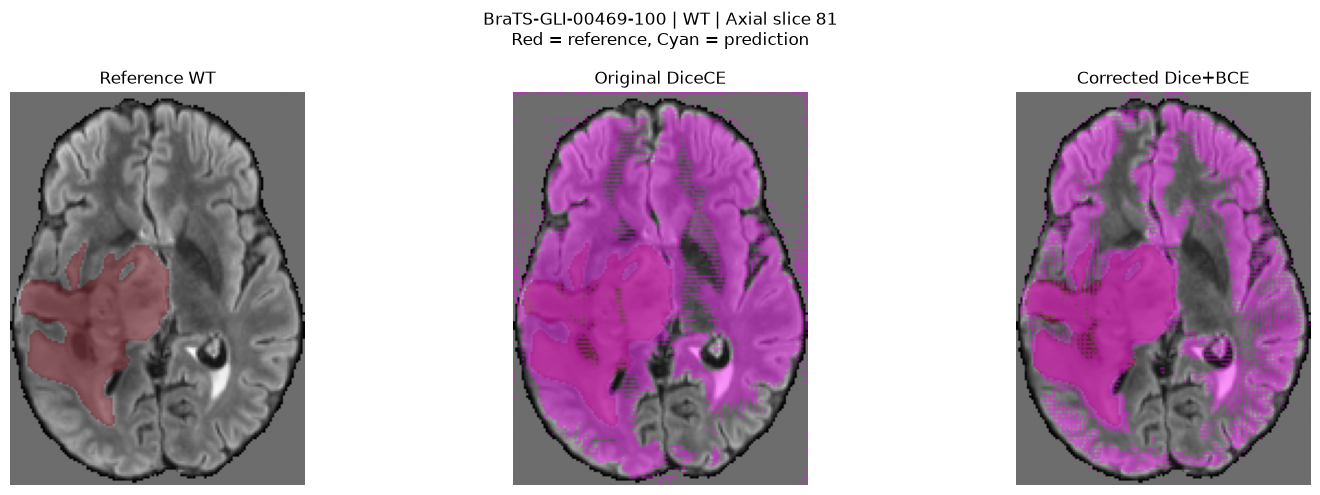

Case: BraTS-GLI-00469-100
Axial slice: 81
WT reference voxels: 143884
Original DiceCE predicted WT voxels: 1099199
Corrected Dice+BCE predicted WT voxels: 725347

WT visual comparison completed.


In [80]:
# -------------------------------------------------------------
# SECTION 35.4 — VISUAL COMPARISON OF WT SEGMENTATION
# -------------------------------------------------------------
#
# Compare the original and corrected model predictions
# on the same MRI slice.
#
# Case: BraTS-GLI-00469-100
# Region: WT (whole tumour)
#
# Red: reference WT
# Cyan: predicted WT
#
# GPU inference only; no training.

import numpy as np
import matplotlib.pyplot as plt
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — SELECT THE SAME VALIDATION CASE
# -------------------------------------------------------------

visual_case_id = "BraTS-GLI-00469-100"

visual_case_index = next(
    index
    for index, case in enumerate(pilot_validation_cases)
    if case["case_id"] == visual_case_id
)

visual_sample = pilot_validation_dataset[
    visual_case_index
]

visual_image = visual_sample["image"].unsqueeze(0)
visual_reference = visual_sample["label"].cpu().numpy()

# -------------------------------------------------------------
# STEP 2 — GENERATE PREDICTIONS FROM BOTH MODELS
# -------------------------------------------------------------

visual_predictions = {}

for model_name, model in {
    "Original DiceCE": evaluation_model,
    "Corrected Dice+BCE": corrected_evaluation_model,
}.items():

    model.eval()

    with torch.inference_mode():

        visual_logits = sliding_window_inference(
            inputs=visual_image.to(evaluation_device),
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25,
            mode="constant",
        )

        visual_predictions[model_name] = (
            (torch.sigmoid(visual_logits) >= 0.5)
            [0]
            .cpu()
            .numpy()
        )

# -------------------------------------------------------------
# STEP 3 — SELECT AN AXIAL SLICE WITH MAXIMUM REFERENCE WT
# -------------------------------------------------------------

wt_reference = visual_reference[0]

slice_index = int(
    np.argmax(wt_reference.sum(axis=(0, 1)))
)

# T2-FLAIR is channel 3 in our four-modality ordering.
flair_slice = visual_image[0, 3, :, :, slice_index].numpy()

reference_slice = wt_reference[:, :, slice_index]

# -------------------------------------------------------------
# STEP 4 — PLOT SIDE-BY-SIDE OVERLAYS
# -------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
)

panels = [
    ("Reference WT", None),
    (
        "Original DiceCE",
        visual_predictions["Original DiceCE"][0],
    ),
    (
        "Corrected Dice+BCE",
        visual_predictions["Corrected Dice+BCE"][0],
    ),
]

for ax, (title, prediction_volume) in zip(
    axes, panels
):

    ax.imshow(
        flair_slice.T,
        cmap="gray",
        origin="lower",
    )

    # Reference WT: red.
    reference_overlay = np.ma.masked_where(
        ~reference_slice.astype(bool),
        reference_slice,
    )

    ax.imshow(
        reference_overlay.T,
        cmap="Reds",
        alpha=0.45,
        origin="lower",
        vmin=0,
        vmax=1,
    )

    # Predicted WT: cyan.
    if prediction_volume is not None:

        prediction_slice = (
            prediction_volume[:, :, slice_index]
        )

        prediction_overlay = np.ma.masked_where(
            ~prediction_slice.astype(bool),
            prediction_slice,
        )

        ax.imshow(
            prediction_overlay.T,
            cmap="cool",
            alpha=0.40,
            origin="lower",
            vmin=0,
            vmax=1,
        )

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"{visual_case_id} | WT | Axial slice {slice_index}\n"
    "Red = reference, Cyan = prediction",
    fontsize=12,
)

plt.tight_layout()
plt.show()

print("Case:", visual_case_id)
print("Axial slice:", slice_index)
print("WT reference voxels:", int(wt_reference.sum()))

for model_name, prediction in visual_predictions.items():
    print(
        f"{model_name} predicted WT voxels:",
        int(prediction[0].sum()),
    )

print("\nWT visual comparison completed.")

In [81]:
# -------------------------------------------------------------
# SECTION 35.5 — CORRECTED WT PROBABILITY DISTRIBUTIONS
# -------------------------------------------------------------
#
# Investigate whether false-positive WT predictions have
# probabilities close to the default threshold of 0.5.
#
# Case: BraTS-GLI-00469-100
#
# GPU inference only; no training.

import numpy as np
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — RUN CORRECTED MODEL INFERENCE
# -------------------------------------------------------------

corrected_evaluation_model.eval()

with torch.inference_mode():

    probability_logits = sliding_window_inference(
        inputs=visual_image.to(evaluation_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=corrected_evaluation_model,
        overlap=0.25,
        mode="constant",
    )

    corrected_wt_probabilities = (
        torch.sigmoid(probability_logits)[0, 0]
        .cpu()
        .numpy()
    )

# -------------------------------------------------------------
# STEP 2 — IDENTIFY REFERENCE WT AND BACKGROUND
# -------------------------------------------------------------

reference_wt_mask = (
    visual_reference[0] > 0
)

# Define brain/foreground from the nonzero MRI signal.
# This excludes most of the zero-padded image background.
mri_foreground_mask = (
    np.any(
        visual_image[0].cpu().numpy() != 0,
        axis=0,
    )
)

inside_wt = corrected_wt_probabilities[
    reference_wt_mask
]

outside_wt_in_brain = corrected_wt_probabilities[
    (~reference_wt_mask) & mri_foreground_mask
]

outside_brain = corrected_wt_probabilities[
    ~mri_foreground_mask
]

# -------------------------------------------------------------
# STEP 3 — SUMMARISE PROBABILITIES
# -------------------------------------------------------------

def summarise_probabilities(name, values):

    print(f"\n{name}")
    print("Voxels:", len(values))
    print("Mean:", round(float(np.mean(values)), 4))
    print("Median:", round(float(np.median(values)), 4))
    print("90th percentile:", round(float(np.percentile(values, 90)), 4))
    print("99th percentile:", round(float(np.percentile(values, 99)), 4))

    for threshold in (0.5, 0.7, 0.9, 0.99):

        fraction = np.mean(values >= threshold)

        print(
            f"Fraction >= {threshold:.2f}: "
            f"{fraction:.4f}"
        )


summarise_probabilities(
    "Reference WT",
    inside_wt,
)

summarise_probabilities(
    "Non-WT MRI foreground",
    outside_wt_in_brain,
)

summarise_probabilities(
    "Outside MRI foreground",
    outside_brain,
)

print("\nCorrected WT probability analysis completed.")


Reference WT
Voxels: 143884
Mean: 0.7317
Median: 0.7333
90th percentile: 0.8925
99th percentile: 0.9525
Fraction >= 0.50: 0.9784
Fraction >= 0.70: 0.5892
Fraction >= 0.90: 0.0836
Fraction >= 0.99: 0.0000

Non-WT MRI foreground
Voxels: 1402572
Mean: 0.4729
Median: 0.4696
90th percentile: 0.6558
99th percentile: 0.8049
Fraction >= 0.50: 0.4149
Fraction >= 0.70: 0.0580
Fraction >= 0.90: 0.0008
Fraction >= 0.99: 0.0000

Outside MRI foreground
Voxels: 2098544
Mean: 0.318
Median: 0.3164
90th percentile: 0.3944
99th percentile: 0.4579
Fraction >= 0.50: 0.0013
Fraction >= 0.70: 0.0000
Fraction >= 0.90: 0.0000
Fraction >= 0.99: 0.0000

Corrected WT probability analysis completed.


WT THRESHOLD SENSITIVITY
 threshold   dice  precision  recall  volume_ratio
    0.3000 0.1013     0.0533  1.0000       18.7441
    0.3500 0.1432     0.0771  0.9998       12.9676
    0.4000 0.2015     0.1121  0.9989        8.9128
    0.4500 0.2620     0.1509  0.9943        6.5891
    0.5000 0.3239     0.1941  0.9784        5.0412
    0.5500 0.3959     0.2515  0.9302        3.6990
    0.6000 0.4671     0.3234  0.8407        2.5997
    0.6500 0.5221     0.4091  0.7214        1.7634
    0.7000 0.5467     0.5099  0.5892        1.1555
    0.7500 0.5289     0.6282  0.4567        0.7269
    0.8000 0.4564     0.7524  0.3276        0.4354
    0.8500 0.3249     0.8563  0.2005        0.2341
    0.9000 0.1533     0.9181  0.0836        0.0911
    0.9500 0.0232     0.9467  0.0117        0.0124

Highest observed Dice (exploratory):
Threshold: 0.7
Dice: 0.5467
Precision: 0.5099
Recall: 0.5892
Volume ratio: 1.16


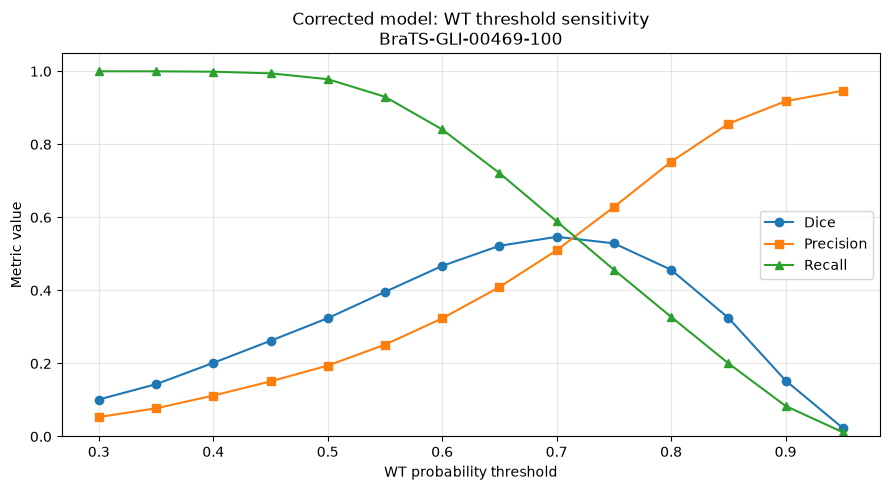


WT threshold sensitivity analysis PASSED.


In [82]:
# -------------------------------------------------------------
# SECTION 35.6 — WT THRESHOLD SENSITIVITY ANALYSIS
# -------------------------------------------------------------
#
# Evaluate how different probability thresholds affect:
#   - Dice similarity
#   - Precision
#   - Recall
#   - Predicted/reference volume ratio
#
# Uses the corrected model's probability volume from Cell 64.
#
# No GPU inference or training is performed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# STEP 1 — VERIFY EXISTING PROBABILITY AND REFERENCE MASKS
# -------------------------------------------------------------

assert corrected_wt_probabilities.shape == (
    reference_wt_mask.shape
)

assert np.isfinite(corrected_wt_probabilities).all()

assert reference_wt_mask.sum() > 0

# -------------------------------------------------------------
# STEP 2 — DEFINE THRESHOLDS
# -------------------------------------------------------------

wt_thresholds = np.round(
    np.arange(0.30, 0.951, 0.05),
    2,
)

threshold_results = []

reference_voxels = int(reference_wt_mask.sum())

# -------------------------------------------------------------
# STEP 3 — CALCULATE METRICS AT EACH THRESHOLD
# -------------------------------------------------------------

for threshold in wt_thresholds:

    predicted_mask = (
        corrected_wt_probabilities >= threshold
    )

    predicted_voxels = int(predicted_mask.sum())

    true_positive = int(
        np.logical_and(
            predicted_mask,
            reference_wt_mask,
        ).sum()
    )

    false_positive = predicted_voxels - true_positive
    false_negative = reference_voxels - true_positive

    dice_denominator = (
        2 * true_positive
        + false_positive
        + false_negative
    )

    dice = (
        2 * true_positive / dice_denominator
        if dice_denominator > 0
        else np.nan
    )

    precision = (
        true_positive / predicted_voxels
        if predicted_voxels > 0
        else np.nan
    )

    recall = true_positive / reference_voxels

    volume_ratio = (
        predicted_voxels / reference_voxels
    )

    threshold_results.append({
        "threshold": float(threshold),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "volume_ratio": float(volume_ratio),
    })

threshold_df = pd.DataFrame(threshold_results)

# -------------------------------------------------------------
# STEP 4 — IDENTIFY HIGHEST OBSERVED DICE
# -------------------------------------------------------------

best_row = threshold_df.loc[
    threshold_df["dice"].idxmax()
]

print("WT THRESHOLD SENSITIVITY")
print(
    threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nHighest observed Dice (exploratory):")
print("Threshold:", round(best_row["threshold"], 2))
print("Dice:", round(best_row["dice"], 4))
print("Precision:", round(best_row["precision"], 4))
print("Recall:", round(best_row["recall"], 4))
print("Volume ratio:", round(best_row["volume_ratio"], 2))

# -------------------------------------------------------------
# STEP 5 — VISUALISE METRIC TRADE-OFFS
# -------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["dice"],
    marker="o",
    label="Dice",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="s",
    label="Precision",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="^",
    label="Recall",
)

plt.xlabel("WT probability threshold")
plt.ylabel("Metric value")
plt.title(
    "Corrected model: WT threshold sensitivity\n"
    "BraTS-GLI-00469-100"
)

plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nWT threshold sensitivity analysis PASSED.")

Completed: BraTS-GLI-00033-100
Completed: BraTS-GLI-00033-101
Completed: BraTS-GLI-00469-100
Completed: BraTS-GLI-00469-101

MEAN WT METRICS ACROSS FOUR CASES
 threshold  mean_dice  mean_precision  mean_recall
    0.3000     0.0390          0.0202       1.0000
    0.3500     0.0559          0.0295       0.9999
    0.4000     0.0789          0.0426       0.9995
    0.4500     0.1036          0.0575       0.9975
    0.5000     0.1315          0.0751       0.9905
    0.5500     0.1674          0.0996       0.9708
    0.6000     0.2119          0.1335       0.9330
    0.6500     0.2650          0.1803       0.8748
    0.7000     0.3268          0.2461       0.7955
    0.7500     0.3972          0.3419       0.6948
    0.8000     0.4637          0.4787       0.5737
    0.8500     0.4828          0.6600       0.4309
    0.9000     0.3843          0.8324       0.2662
    0.9500     0.1785          0.9348       0.1016

Highest observed mean WT Dice:
Threshold: 0.85
Mean Dice: 0.4828
Mean preci

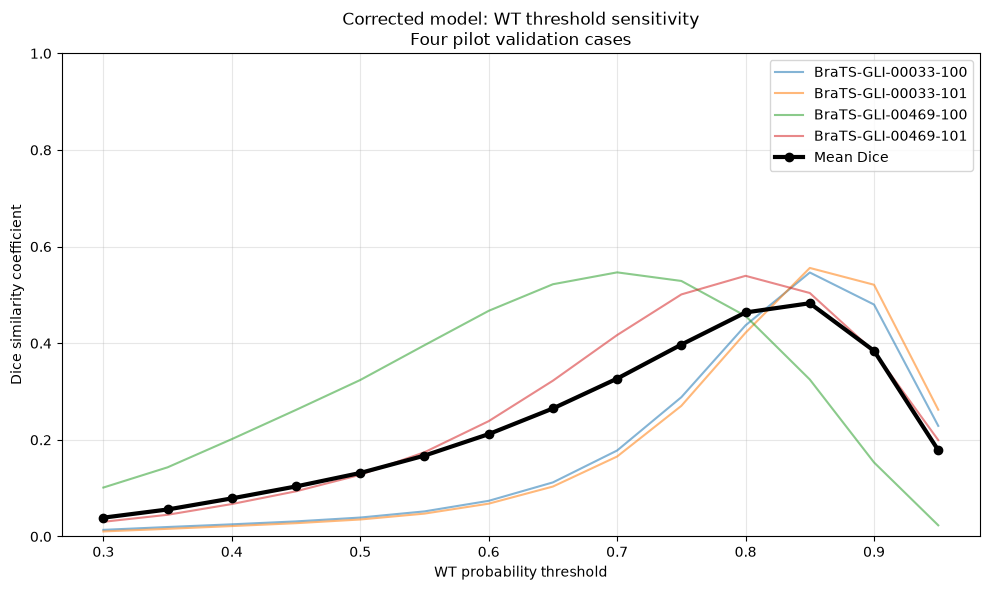


Multi-case WT threshold analysis PASSED.


In [83]:
# -------------------------------------------------------------
# SECTION 35.7 — MULTI-CASE WT THRESHOLD ANALYSIS
# -------------------------------------------------------------
#
# Evaluate WT segmentation at different thresholds across
# all four pilot validation cases.
#
# This helps determine whether the threshold behaviour
# observed in one case generalises to the small pilot subset.
#
# No training or checkpoint modifications.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — DEFINE THRESHOLDS
# -------------------------------------------------------------

multi_case_thresholds = np.round(
    np.arange(0.30, 0.951, 0.05),
    2,
)

multi_case_results = []

corrected_evaluation_model.eval()

# -------------------------------------------------------------
# STEP 2 — EVALUATE EACH VALIDATION CASE
# -------------------------------------------------------------

for case_index, case in enumerate(
    pilot_validation_cases
):

    case_id = case["case_id"]

    sample = pilot_validation_dataset[case_index]

    image = sample["image"].unsqueeze(0)
    reference_wt = (
        sample["label"][0].cpu().numpy() > 0
    )

    assert reference_wt.sum() > 0

    # Run full-volume inference once per case.
    with torch.inference_mode():

        logits = sliding_window_inference(
            inputs=image.to(evaluation_device),
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=corrected_evaluation_model,
            overlap=0.25,
            mode="constant",
        )

        wt_probabilities = (
            torch.sigmoid(logits)[0, 0]
            .cpu()
            .numpy()
        )

    # Calculate Dice for every threshold without
    # repeating inference.
    for threshold in multi_case_thresholds:

        prediction = (
            wt_probabilities >= threshold
        )

        true_positive = np.logical_and(
            prediction,
            reference_wt,
        ).sum()

        predicted_voxels = prediction.sum()
        reference_voxels = reference_wt.sum()

        dice = (
            2 * true_positive
            / (predicted_voxels + reference_voxels)
        )

        precision = (
            true_positive / predicted_voxels
            if predicted_voxels > 0
            else np.nan
        )

        recall = (
            true_positive / reference_voxels
        )

        multi_case_results.append({
            "case_id": case_id,
            "threshold": float(threshold),
            "dice": float(dice),
            "precision": float(precision),
            "recall": float(recall),
        })

    print("Completed:", case_id)

# -------------------------------------------------------------
# STEP 3 — AGGREGATE MEAN METRICS
# -------------------------------------------------------------

multi_case_df = pd.DataFrame(
    multi_case_results
)

threshold_summary = (
    multi_case_df
    .groupby("threshold", as_index=False)
    .agg(
        mean_dice=("dice", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
    )
)

print("\nMEAN WT METRICS ACROSS FOUR CASES")
print(
    threshold_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

# -------------------------------------------------------------
# STEP 4 — IDENTIFY EXPLORATORY BEST THRESHOLD
# -------------------------------------------------------------

best_threshold_row = threshold_summary.loc[
    threshold_summary["mean_dice"].idxmax()
]

print("\nHighest observed mean WT Dice:")
print("Threshold:", best_threshold_row["threshold"])
print("Mean Dice:", round(best_threshold_row["mean_dice"], 4))
print("Mean precision:", round(best_threshold_row["mean_precision"], 4))
print("Mean recall:", round(best_threshold_row["mean_recall"], 4))

# -------------------------------------------------------------
# STEP 5 — VISUALISE PER-CASE AND MEAN DICE
# -------------------------------------------------------------

plt.figure(figsize=(10, 6))

for case_id, case_df in multi_case_df.groupby("case_id"):

    plt.plot(
        case_df["threshold"],
        case_df["dice"],
        alpha=0.55,
        label=case_id,
    )

plt.plot(
    threshold_summary["threshold"],
    threshold_summary["mean_dice"],
    color="black",
    linewidth=3,
    marker="o",
    label="Mean Dice",
)

plt.xlabel("WT probability threshold")
plt.ylabel("Dice similarity coefficient")
plt.title(
    "Corrected model: WT threshold sensitivity\n"
    "Four pilot validation cases"
)

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# STEP 6 — SAVE RESULTS
# -------------------------------------------------------------

multi_case_df.to_csv(
    corrected_log_directory
    / "wt_threshold_per_case.csv",
    index=False,
)

threshold_summary.to_csv(
    corrected_log_directory
    / "wt_threshold_summary.csv",
    index=False,
)

print("\nMulti-case WT threshold analysis PASSED.")

In [84]:
# -------------------------------------------------------------
# SECTION 35.8 — DOCUMENT THRESHOLD SENSITIVITY
# -------------------------------------------------------------
#
# Save the exploratory best WT threshold for each case
# and the best threshold based on mean Dice.
#
# These thresholds are exploratory, not independently
# validated operating thresholds.
#
# No GPU operations are performed.

import json
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — IDENTIFY BEST THRESHOLD PER CASE
# -------------------------------------------------------------

best_case_indices = (
    multi_case_df
    .groupby("case_id")["dice"]
    .idxmax()
)

best_per_case = (
    multi_case_df
    .loc[
        best_case_indices,
        ["case_id", "threshold", "dice", "precision", "recall"]
    ]
    .sort_values("case_id")
    .reset_index(drop=True)
)

print("BEST OBSERVED WT THRESHOLD PER CASE")

print(
    best_per_case.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

# -------------------------------------------------------------
# STEP 2 — IDENTIFY BEST MEAN THRESHOLD
# -------------------------------------------------------------

best_mean_row = threshold_summary.loc[
    threshold_summary["mean_dice"].idxmax()
]

print("\nBEST OBSERVED MEAN WT THRESHOLD")

print("Threshold:", float(best_mean_row["threshold"]))
print("Mean Dice:", round(float(best_mean_row["mean_dice"]), 4))
print(
    "Mean precision:",
    round(float(best_mean_row["mean_precision"]), 4),
)
print(
    "Mean recall:",
    round(float(best_mean_row["mean_recall"]), 4),
)

# -------------------------------------------------------------
# STEP 3 — SAVE SUMMARY
# -------------------------------------------------------------

threshold_report = {
    "experiment_id": corrected_experiment_id,
    "region": "WT",
    "validation_cases": len(pilot_validation_cases),
    "independent_validation_subjects": len({
        case["subject_id"]
        for case in pilot_validation_cases
    }),
    "threshold_selection": "exploratory_validation_only",
    "best_mean_threshold": float(
        best_mean_row["threshold"]
    ),
    "best_mean_dice": float(
        best_mean_row["mean_dice"]
    ),
    "per_case_results": best_per_case.to_dict(
        orient="records"
    ),
    "limitations": [
        "Only four validation cases from two subjects.",
        "Thresholds selected and evaluated on the same cases.",
        "Results are not independently validated.",
        "WT only; TC, ET and RC thresholds not evaluated.",
    ],
}

threshold_report_path = (
    corrected_log_directory
    / "wt_threshold_exploratory_summary.json"
)

with threshold_report_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        threshold_report,
        file,
        indent=2,
    )

assert threshold_report_path.is_file()

print("\nSaved:", threshold_report_path)
print("WT threshold experiment documentation PASSED.")

BEST OBSERVED WT THRESHOLD PER CASE
            case_id  threshold   dice  precision  recall
BraTS-GLI-00033-100     0.8500 0.5464     0.5469  0.5459
BraTS-GLI-00033-101     0.8500 0.5558     0.5286  0.5861
BraTS-GLI-00469-100     0.7000 0.5467     0.5099  0.5892
BraTS-GLI-00469-101     0.8000 0.5395     0.5499  0.5295

BEST OBSERVED MEAN WT THRESHOLD
Threshold: 0.85
Mean Dice: 0.4828
Mean precision: 0.66
Mean recall: 0.4309

Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/wt_threshold_exploratory_summary.json
WT threshold experiment documentation PASSED.


### Section 35.9 — Segmentation Model Troubleshooting and Hyperparameter Investigation

Following the initial 3D U-Net training pilot, segmentation performance was evaluated to identify potential causes of poor tumour delineation and determine which modelling parameters required adjustment.

#### 1. Initial segmentation problems

The original model demonstrated very low Dice scores across WT, TC, ET and RC, despite decreasing training and validation losses.

Visual inspection revealed extensive **oversegmentation**, with predicted masks extending into normal brain tissue and occasionally outside the brain. Some predictions also exhibited grid-like patterns.

Quantitative evaluation confirmed that the model frequently achieved high recall but extremely low precision, indicating that it identified many genuine tumour voxels while simultaneously producing excessive false-positive predictions.

#### 2. Investigation and correction of the loss function

The original training configuration used MONAI's `DiceCELoss` for four overlapping binary segmentation channels.

Inspection of the underlying implementation revealed that the cross-entropy component was categorical rather than binary, making it unsuitable for the multi-label segmentation targets.

The loss function was therefore replaced with a custom `MultiLabelDiceBCELoss`, combining sigmoid Dice loss and `BCEWithLogitsLoss` with equal weighting.

A second 10-epoch pilot was trained using the same architecture, dataset subsets, patch dimensions, optimiser and learning rate.

**The corrected model improved mean Dice scores across all four regions**, although oversegmentation persisted.

| Region | Original Dice | Corrected Dice |
|---|---:|---:|
| WT | 0.0906 | 0.1315 |
| TC | 0.0242 | 0.0935 |
| ET | 0.0091 | 0.0553 |
| RC | 0.0394 | 0.1411 |

This demonstrated that the loss formulation was an important contributor to poor performance, but was not the only limitation.

#### 3. Probability threshold optimisation

The corrected model continued to generate excessive false positives at the default sigmoid probability threshold of **0.50**.

Analysis of the predicted probability distributions showed that reference tumour voxels generally received higher probabilities than non-tumour voxels, suggesting that the network had learned some useful discriminative features.

A threshold sensitivity analysis was therefore performed, varying the WT classification threshold from 0.30 to 0.95.

Increasing the threshold improved precision and reduced oversegmentation, but also decreased recall.

The best observed WT thresholds differed between validation cases:

| Case | Best observed threshold | WT Dice |
|---|---:|---:|
| BraTS-GLI-00033-100 | 0.85 | 0.5464 |
| BraTS-GLI-00033-101 | 0.85 | 0.5558 |
| BraTS-GLI-00469-100 | 0.70 | 0.5467 |
| BraTS-GLI-00469-101 | 0.80 | 0.5395 |

A common threshold of **0.85** produced the highest mean WT Dice across the four cases, increasing it from approximately **0.13 at threshold 0.50 to 0.48**.

However, this improvement came at the expense of sensitivity, with mean recall falling to approximately 0.43.

These thresholds were explored on only four validation cases from two subjects and must not be regarded as independently validated operating thresholds.

#### 4. Remaining issues and proposed hyperparameter adjustments

The investigations identified several potential areas for further optimisation:

| Parameter or component | Current configuration | Proposed investigation |
|---|---|---|
| Loss function | Corrected sigmoid Dice + BCE | Retain as baseline; investigate alternative loss weighting if necessary |
| Probability threshold | 0.50 initially | Evaluate region-specific thresholds on a larger validation cohort |
| Training dataset | 24 cases | Increase training cases and subject diversity |
| Training duration | 10 epochs | Increase epochs and monitor validation performance |
| Patch sampling | Positive/negative random crops | Investigate better representation of small TC, ET and RC regions |
| Sliding-window inference | 25% overlap, constant blending | Investigate possible boundary artefacts and Gaussian blending |
| Network architecture | 3D U-Net | Retain initially; reconsider only after training and sampling improvements |

These are **proposed investigations**, not changes already tested. In particular, the effects of longer training, alternative patch sampling and Gaussian blending have not yet been established.

#### 5. Overall interpretation

The troubleshooting process identified two important contributors to poor segmentation:

1. **An inappropriate loss formulation**, which was corrected and resulted in improved segmentation performance.
2. **Excessive false-positive classification at the default probability threshold**, which could be partially mitigated through threshold adjustment.

The results suggest that the network has begun learning meaningful imaging features but has not yet developed sufficiently reliable spatial discrimination.

The next priority is to train the corrected model on a larger and more representative dataset, while investigating class imbalance, sampling strategies and inference artefacts.

**The objective of subsequent experiments will be to improve genuine segmentation accuracy and generalisation, rather than simply minimise training loss or maximise Dice on the small pilot validation subset.**

In [85]:
# -------------------------------------------------------------
# SECTION 36.1 — VERIFY FULL DATASET SPLIT
# -------------------------------------------------------------
#
# Review the subject-level training, validation and test
# partitions before designing a larger training experiment.
#
# This cell:
#   - Checks the number of cases in each partition
#   - Counts independent subjects
#   - Verifies that subjects do not cross partitions
#   - Checks for duplicate case IDs
#
# No MRI files are loaded.
# No GPU operations are performed.

# -------------------------------------------------------------
# STEP 1 — COLLECT DATASET PARTITIONS
# -------------------------------------------------------------

dataset_partitions = {
    "Training": train_cases,
    "Validation": validation_cases,
    "Test": test_cases,
}

partition_subjects = {}
all_case_ids = []

# -------------------------------------------------------------
# STEP 2 — INSPECT EACH PARTITION
# -------------------------------------------------------------

print("FULL DATASET SPLIT")
print("-" * 55)

for partition_name, cases in dataset_partitions.items():

    case_ids = [
        case["case_id"]
        for case in cases
    ]

    subject_ids = {
        case["subject_id"]
        for case in cases
    }

    # Check that cases are unique within each partition.
    assert len(case_ids) == len(set(case_ids)), (
        f"Duplicate case IDs in {partition_name}."
    )

    partition_subjects[partition_name] = subject_ids
    all_case_ids.extend(case_ids)

    print(
        f"{partition_name:12s} "
        f"Cases: {len(cases):4d} | "
        f"Subjects: {len(subject_ids):4d}"
    )

# -------------------------------------------------------------
# STEP 3 — VERIFY SUBJECT-LEVEL INDEPENDENCE
# -------------------------------------------------------------

assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Validation"]
)

assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Test"]
)

assert partition_subjects["Validation"].isdisjoint(
    partition_subjects["Test"]
)

print("\nSubject-level separation: PASSED")

# -------------------------------------------------------------
# STEP 4 — VERIFY DATASET TOTALS
# -------------------------------------------------------------

assert len(train_cases) == 936
assert len(validation_cases) == 216
assert len(test_cases) == 198

assert len(all_case_ids) == 1350

assert len(all_case_ids) == len(set(all_case_ids)), (
    "Duplicate case IDs detected across partitions."
)

total_subjects = len(
    set().union(*partition_subjects.values())
)

print("\nTotal cases:", len(all_case_ids))
print("Total independent subjects:", total_subjects)

print("\nFull dataset split verification PASSED.")

FULL DATASET SPLIT
-------------------------------------------------------
Training     Cases:  936 | Subjects:  429
Validation   Cases:  216 | Subjects:   92
Test         Cases:  198 | Subjects:   92

Subject-level separation: PASSED

Total cases: 1350
Total independent subjects: 613

Full dataset split verification PASSED.


In [86]:
# -------------------------------------------------------------
# SECTION 36.2 — ANALYSE CASE DISTRIBUTION PER SUBJECT
# -------------------------------------------------------------
#
# Determine how many longitudinal MRI cases each subject
# contributes to the training, validation and test datasets.
#
# This will inform subject-diverse sampling for the next
# larger-scale training experiment.
#
# No MRI loading or GPU operations.

from collections import Counter
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — COUNT CASES PER SUBJECT
# -------------------------------------------------------------

subject_distribution_records = []

for partition_name, cases in dataset_partitions.items():

    subject_counts = Counter(
        case["subject_id"]
        for case in cases
    )

    for subject_id, case_count in subject_counts.items():

        subject_distribution_records.append({
            "partition": partition_name,
            "subject_id": subject_id,
            "case_count": case_count,
        })

subject_distribution_df = pd.DataFrame(
    subject_distribution_records
)

# -------------------------------------------------------------
# STEP 2 — SUMMARISE EACH PARTITION
# -------------------------------------------------------------

distribution_summary = (
    subject_distribution_df
    .groupby("partition")["case_count"]
    .agg(
        subjects="count",
        minimum_cases="min",
        median_cases="median",
        mean_cases="mean",
        maximum_cases="max",
    )
    .reset_index()
)

print("CASES PER SUBJECT — DATASET SUMMARY")

print(
    distribution_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}",
    )
)

# -------------------------------------------------------------
# STEP 3 — SHOW TRAINING SUBJECT DISTRIBUTION
# -------------------------------------------------------------

training_subject_distribution = (
    subject_distribution_df[
        subject_distribution_df["partition"] == "Training"
    ]
)

training_case_frequency = (
    training_subject_distribution["case_count"]
    .value_counts()
    .sort_index()
)

print("\nTRAINING SUBJECTS BY NUMBER OF CASES")

for case_count, number_of_subjects in (
    training_case_frequency.items()
):

    print(
        f"{case_count} case(s): "
        f"{number_of_subjects} subjects"
    )

# -------------------------------------------------------------
# STEP 4 — CHECK CONSISTENCY
# -------------------------------------------------------------

assert (
    training_subject_distribution["case_count"].sum()
    == len(train_cases)
)

assert (
    len(training_subject_distribution)
    == 429
)

print("\nSubject distribution analysis PASSED.")

CASES PER SUBJECT — DATASET SUMMARY
 partition  subjects  minimum_cases  median_cases  mean_cases  maximum_cases
      Test        92              1          2.00        2.15              7
  Training       429              1          2.00        2.18             10
Validation        92              1          2.00        2.35              8

TRAINING SUBJECTS BY NUMBER OF CASES
1 case(s): 87 subjects
2 case(s): 268 subjects
3 case(s): 28 subjects
4 case(s): 21 subjects
5 case(s): 13 subjects
6 case(s): 8 subjects
7 case(s): 2 subjects
8 case(s): 1 subjects
10 case(s): 1 subjects

Subject distribution analysis PASSED.


In [87]:
# -------------------------------------------------------------
# SECTION 36.3 — ANALYSE SEGMENTATION REGION PREVALENCE
# -------------------------------------------------------------
#
# Examine WT, TC, ET and RC prevalence across the complete
# training partition.
#
# Uses raw BraTS segmentation labels:
#   WT = labels 1, 2, 3
#   TC = labels 1, 3
#   ET = label 3
#   RC = label 4
#
# Only segmentation files are loaded.
# No MRI modalities or GPU operations are required.

from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd
import time

# -------------------------------------------------------------
# STEP 1 — DEFINE OUTPUT PATH
# -------------------------------------------------------------

region_prevalence_path = (
    corrected_log_directory
    / "training_region_prevalence.csv"
)

# Avoid silently overwriting previous analysis.
assert not region_prevalence_path.exists(), (
    f"Output already exists: {region_prevalence_path}"
)

# -------------------------------------------------------------
# STEP 2 — DEFINE REGION LABELS
# -------------------------------------------------------------

region_label_values = {
    "WT": (1, 2, 3),
    "TC": (1, 3),
    "ET": (3,),
    "RC": (4,),
}

region_prevalence_records = []

analysis_start = time.monotonic()

# -------------------------------------------------------------
# STEP 3 — INSPECT EACH TRAINING CASE
# -------------------------------------------------------------

for case_index, case in enumerate(train_cases, start=1):

    segmentation_path = Path(case["label"])

    assert segmentation_path.is_file(), (
        f"Missing segmentation: {segmentation_path}"
    )

    # Load only the segmentation label volume.
    segmentation_image = nib.load(
        str(segmentation_path)
    )

    segmentation = np.asarray(
        segmentation_image.dataobj
    )

    # Check that the raw labels match our expected mapping.
    observed_labels = set(
        np.unique(segmentation).tolist()
    )

    assert observed_labels.issubset({0, 1, 2, 3, 4}), (
        f"Unexpected labels in {case['case_id']}: "
        f"{observed_labels}"
    )

    record = {
        "case_id": case["case_id"],
        "subject_id": case["subject_id"],
    }

    # Count voxels for each overlapping binary region.
    for region_name, label_values in (
        region_label_values.items()
    ):

        voxel_count = int(
            np.isin(
                segmentation,
                label_values
            ).sum()
        )

        record[f"{region_name}_voxels"] = voxel_count
        record[f"{region_name}_present"] = (
            voxel_count > 0
        )

    region_prevalence_records.append(record)

    if case_index % 100 == 0:
        print(
            f"Processed {case_index}/{len(train_cases)} cases"
        )

# -------------------------------------------------------------
# STEP 4 — CREATE RESULTS DATAFRAME
# -------------------------------------------------------------

region_prevalence_df = pd.DataFrame(
    region_prevalence_records
)

assert len(region_prevalence_df) == len(train_cases)

assert region_prevalence_df["case_id"].is_unique

# -------------------------------------------------------------
# STEP 5 — SUMMARISE REGION PREVALENCE
# -------------------------------------------------------------

print("\nTRAINING REGION PREVALENCE")
print("-" * 55)

for region_name in region_label_values:

    present_count = int(
        region_prevalence_df[
            f"{region_name}_present"
        ].sum()
    )

    prevalence_percent = (
        100 * present_count / len(region_prevalence_df)
    )

    print(
        f"{region_name}: "
        f"{present_count}/{len(region_prevalence_df)} cases "
        f"({prevalence_percent:.1f}%)"
    )

# -------------------------------------------------------------
# STEP 6 — SAVE RESULTS
# -------------------------------------------------------------

region_prevalence_df.to_csv(
    region_prevalence_path,
    index=False,
)

elapsed_minutes = (
    time.monotonic() - analysis_start
) / 60

print(
    "\nAnalysis time:",
    round(elapsed_minutes, 2),
    "minutes"
)

print("Saved:", region_prevalence_path)

print("\nTraining region prevalence analysis PASSED.")

Processed 100/936 cases
Processed 200/936 cases
Processed 300/936 cases
Processed 400/936 cases
Processed 500/936 cases
Processed 600/936 cases
Processed 700/936 cases
Processed 800/936 cases
Processed 900/936 cases

TRAINING REGION PREVALENCE
-------------------------------------------------------
WT: 936/936 cases (100.0%)
TC: 682/936 cases (72.9%)
ET: 679/936 cases (72.5%)
RC: 812/936 cases (86.8%)

Analysis time: 2.61 minutes
Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_region_prevalence.csv

Training region prevalence analysis PASSED.


In [88]:
# -------------------------------------------------------------
# SECTION 36.4 — ANALYSE SEGMENTATION REGION SIZES
# -------------------------------------------------------------
#
# Examine the distribution of WT, TC, ET and RC voxel counts
# across the complete training partition.
#
# Important:
#   - Exclude absent regions from size statistics.
#   - Report absence separately.
#   - Use voxel counts rather than assuming physical volumes,
#     because voxel spacing has not been checked here.
#
# This cell uses the existing region_prevalence_df.
# No MRI loading or GPU operations.

import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — SUMMARISE NONZERO REGION SIZES
# -------------------------------------------------------------

region_volume_records = []

for region_name in ("WT", "TC", "ET", "RC"):

    voxel_counts = region_prevalence_df[
        f"{region_name}_voxels"
    ]

    # Region size statistics should exclude cases where
    # the reference region is absent.
    nonzero_counts = voxel_counts[
        voxel_counts > 0
    ]

    region_volume_records.append({
        "region": region_name,
        "present_cases": len(nonzero_counts),
        "absent_cases": int((voxel_counts == 0).sum()),
        "minimum_voxels": int(nonzero_counts.min()),
        "p10_voxels": float(nonzero_counts.quantile(0.10)),
        "median_voxels": float(nonzero_counts.median()),
        "p90_voxels": float(nonzero_counts.quantile(0.90)),
        "maximum_voxels": int(nonzero_counts.max()),
    })

region_volume_summary = pd.DataFrame(
    region_volume_records
)

# -------------------------------------------------------------
# STEP 2 — DISPLAY RESULTS
# -------------------------------------------------------------

print("SEGMENTATION REGION SIZE DISTRIBUTION")
print("(Voxel counts among cases where region is present)")
print("-" * 75)

print(
    region_volume_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:,.0f}",
    )
)

# -------------------------------------------------------------
# STEP 3 — COMPARE MEDIAN REGION SIZES
# -------------------------------------------------------------

wt_median = region_volume_summary.loc[
    region_volume_summary["region"] == "WT",
    "median_voxels"
].iloc[0]

print("\nMEDIAN SIZE RELATIVE TO WT")
print("-" * 40)

for _, row in region_volume_summary.iterrows():

    relative_size = (
        row["median_voxels"] / wt_median
    )

    print(
        f"{row['region']}: "
        f"{relative_size:.3f} × WT median"
    )

# -------------------------------------------------------------
# STEP 4 — VERIFY RESULTS
# -------------------------------------------------------------

assert (
    region_volume_summary["present_cases"]
    + region_volume_summary["absent_cases"]
    == len(train_cases)
).all()

assert (
    region_volume_summary["minimum_voxels"] > 0
).all()

print("\nRegion size analysis PASSED.")

SEGMENTATION REGION SIZE DISTRIBUTION
(Voxel counts among cases where region is present)
---------------------------------------------------------------------------
region  present_cases  absent_cases  minimum_voxels  p10_voxels  median_voxels  p90_voxels  maximum_voxels
    WT            936             0             511      11,229         41,362     131,917          327711
    TC            682           254               1         208          5,337      34,527          171479
    ET            679           257               1         201          4,837      28,450          150383
    RC            812           124               1         655          8,830      42,877          165848

MEDIAN SIZE RELATIVE TO WT
----------------------------------------
WT: 1.000 × WT median
TC: 0.129 × WT median
ET: 0.117 × WT median
RC: 0.213 × WT median

Region size analysis PASSED.


In [89]:
# -------------------------------------------------------------
# SECTION 36.5 — AUDIT CURRENT TRAINING PATCH SAMPLING
# -------------------------------------------------------------
#
# Examine which segmentation regions are represented in
# patches generated by our existing training transforms.
#
# Uses:
#   - 8 training cases
#   - 2 patches per case
#   - Existing train_transforms
#
# This is a diagnostic sample, not a definitive estimate of
# patch sampling performance across the complete dataset.
#
# No GPU training or inference is performed.

import random
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — SELECT REPRODUCIBLE CASES
# -------------------------------------------------------------

sampling_rng = random.Random(42)

audit_cases = sampling_rng.sample(
    train_cases,
    k=8,
)

print("Selected cases for patch sampling audit:")

for case in audit_cases:
    print(
        case["case_id"],
        "| Subject:",
        case["subject_id"]
    )

# -------------------------------------------------------------
# STEP 2 — GENERATE PATCHES
# -------------------------------------------------------------

patch_audit_records = []

for case_index, case in enumerate(audit_cases, start=1):

    # Existing transforms include MRI preprocessing,
    # random patch selection and conversion to four
    # binary segmentation channels.
    #
    # RandCropByPosNegLabeld(num_samples=2) returns
    # a list of two transformed patch dictionaries.

    sampled_patches = train_transforms(case)

    assert isinstance(sampled_patches, list)
    assert len(sampled_patches) == 2

    for patch_index, patch in enumerate(
        sampled_patches,
        start=1
    ):

        label = patch["label"]

        # Convert the small label patch to NumPy for
        # voxel-count analysis.
        if hasattr(label, "detach"):
            label = label.detach().cpu().numpy()
        else:
            label = np.asarray(label)

        assert label.shape[0] == 4, (
            f"Unexpected label shape: {label.shape}"
        )

        record = {
            "case_id": case["case_id"],
            "subject_id": case["subject_id"],
            "patch_index": patch_index,
        }

        for channel_index, region_name in enumerate(
            ("WT", "TC", "ET", "RC")
        ):

            voxel_count = int(
                np.count_nonzero(
                    label[channel_index]
                )
            )

            record[f"{region_name}_voxels"] = voxel_count
            record[f"{region_name}_present"] = (
                voxel_count > 0
            )

        patch_audit_records.append(record)

    print(
        f"Processed {case_index}/{len(audit_cases)} cases"
    )

# -------------------------------------------------------------
# STEP 3 — SUMMARISE PATCH CONTENTS
# -------------------------------------------------------------

patch_audit_df = pd.DataFrame(
    patch_audit_records
)

print("\nREGION REPRESENTATION IN SAMPLED PATCHES")
print("-" * 60)

for region_name in ("WT", "TC", "ET", "RC"):

    present_count = int(
        patch_audit_df[
            f"{region_name}_present"
        ].sum()
    )

    percentage = (
        100 * present_count / len(patch_audit_df)
    )

    median_voxels = (
        patch_audit_df[
            f"{region_name}_voxels"
        ].median()
    )

    print(
        f"{region_name}: "
        f"{present_count}/{len(patch_audit_df)} patches "
        f"({percentage:.1f}%) | "
        f"Median voxels: {median_voxels:,.0f}"
    )

# -------------------------------------------------------------
# STEP 4 — VERIFY RESULTS
# -------------------------------------------------------------

assert len(patch_audit_df) == 16

assert (
    patch_audit_df[
        [f"{region}_voxels"
         for region in ("WT", "TC", "ET", "RC")]
    ].to_numpy() >= 0
).all()

print("\nPatch sampling audit PASSED.")

Selected cases for patch sampling audit:
BraTS-GLI-02830-101 | Subject: BraTS-GLI-02830
BraTS-GLI-02085-102 | Subject: BraTS-GLI-02085
BraTS-GLI-00498-101 | Subject: BraTS-GLI-00498
BraTS-GLI-02900-100 | Subject: BraTS-GLI-02900
BraTS-GLI-02206-102 | Subject: BraTS-GLI-02206
BraTS-GLI-02186-101 | Subject: BraTS-GLI-02186
BraTS-GLI-02174-100 | Subject: BraTS-GLI-02174
BraTS-GLI-02099-101 | Subject: BraTS-GLI-02099
Processed 1/8 cases
Processed 2/8 cases
Processed 3/8 cases
Processed 4/8 cases
Processed 5/8 cases
Processed 6/8 cases
Processed 7/8 cases
Processed 8/8 cases

REGION REPRESENTATION IN SAMPLED PATCHES
------------------------------------------------------------
WT: 16/16 patches (100.0%) | Median voxels: 54,312
TC: 10/16 patches (62.5%) | Median voxels: 789
ET: 10/16 patches (62.5%) | Median voxels: 789
RC: 14/16 patches (87.5%) | Median voxels: 3,178

Patch sampling audit PASSED.


In [90]:
# -------------------------------------------------------------
# SECTION 36.6 — COMPARE SOURCE AND PATCH REGION PRESENCE
# -------------------------------------------------------------
#
# Determine whether the current training patch sampler
# misses regions that are present in the original MRI case.
#
# Uses:
#   - region_prevalence_df from Section 36.3
#   - patch_audit_df from Section 36.5
#
# No MRI loading or GPU operations.

import pandas as pd

# -------------------------------------------------------------
# STEP 1 — JOIN PATCH DATA WITH SOURCE-CASE LABEL DATA
# -------------------------------------------------------------

source_region_columns = [
    "case_id",
    "WT_present",
    "TC_present",
    "ET_present",
    "RC_present",
]

patch_source_comparison = patch_audit_df.merge(
    region_prevalence_df[source_region_columns],
    on="case_id",
    how="left",
    suffixes=("_patch", "_source"),
    validate="many_to_one",
)

assert len(patch_source_comparison) == len(patch_audit_df)

# -------------------------------------------------------------
# STEP 2 — MEASURE REGION CAPTURE
# -------------------------------------------------------------

capture_records = []

for region_name in ("WT", "TC", "ET", "RC"):

    source_present = patch_source_comparison[
        f"{region_name}_present_source"
    ].astype(bool)

    patch_present = patch_source_comparison[
        f"{region_name}_present_patch"
    ].astype(bool)

    # Count patches drawn from cases where the region exists.
    eligible_patches = int(source_present.sum())

    # Among eligible patches, count how often the sampler
    # actually included the region.
    captured_patches = int(
        (source_present & patch_present).sum()
    )

    missed_patches = int(
        (source_present & ~patch_present).sum()
    )

    capture_rate = (
        100 * captured_patches / eligible_patches
        if eligible_patches > 0
        else float("nan")
    )

    capture_records.append({
        "region": region_name,
        "eligible_patches": eligible_patches,
        "captured_patches": captured_patches,
        "missed_patches": missed_patches,
        "capture_rate_percent": capture_rate,
    })

capture_summary_df = pd.DataFrame(
    capture_records
)

# -------------------------------------------------------------
# STEP 3 — DISPLAY RESULTS
# -------------------------------------------------------------

print("REGION CAPTURE WHEN PRESENT IN SOURCE CASE")
print("-" * 75)

print(
    capture_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.1f}",
    )
)

# -------------------------------------------------------------
# STEP 4 — VERIFY RESULTS
# -------------------------------------------------------------

assert (
    capture_summary_df["captured_patches"]
    + capture_summary_df["missed_patches"]
    == capture_summary_df["eligible_patches"]
).all()

# A patch cannot contain a labelled region that is absent
# from its source case.
for region_name in ("WT", "TC", "ET", "RC"):

    invalid_patches = (
        patch_source_comparison[
            f"{region_name}_present_patch"
        ].astype(bool)
        &
        ~patch_source_comparison[
            f"{region_name}_present_source"
        ].astype(bool)
    )

    assert not invalid_patches.any(), (
        f"Unexpected {region_name} in a source-negative case."
    )

print("\nSource-to-patch region capture analysis PASSED.")

REGION CAPTURE WHEN PRESENT IN SOURCE CASE
---------------------------------------------------------------------------
region  eligible_patches  captured_patches  missed_patches  capture_rate_percent
    WT                16                16               0                 100.0
    TC                12                10               2                  83.3
    ET                12                10               2                  83.3
    RC                16                14               2                  87.5

Source-to-patch region capture analysis PASSED.


### Sections 36.1–36.6 — Dataset Characteristics and Training Patch Sampling Analysis

Before expanding model training, we investigated the dataset composition, segmentation-region sizes and effectiveness of the existing patch sampling strategy.

**1. Dataset composition and subject diversity**

The BraTS 2024 GLI dataset contains **1,350 MRI cases from 613 independent subjects**, divided into 936 training, 216 validation and 198 test cases. Subject-level separation was verified with no overlap between partitions.

Within the training partition, 355 of 429 subjects (82.8%) contribute only one or two scans, while some contribute up to 10. This supports selecting a subject-diverse subset for subsequent experiments to avoid disproportionately representing patients with multiple longitudinal scans.

**2. Segmentation-region prevalence and size**

| Region | Cases containing region | Median region size |
|---|---:|---:|
| WT | 936/936 (100.0%) | 41,362 voxels |
| TC | 682/936 (72.9%) | 5,337 voxels |
| ET | 679/936 (72.5%) | 4,837 voxels |
| RC | 812/936 (86.8%) | 8,830 voxels |

Although TC, ET and RC are present in most cases, their median sizes are considerably smaller than WT. TC and ET have median volumes equivalent to approximately 13% and 12% of the WT median, respectively.

This demonstrates substantial **region-size imbalance**, even though the smaller regions are not particularly rare at the case level. The median comparisons are across separate region distributions, not paired within individual cases.

**3. Evaluation of the existing patch sampler**

Our current `RandCropByPosNegLabeld` configuration generates two 96 × 96 × 96 patches per training case using positive/negative foreground sampling.

An exploratory audit of 16 patches from eight randomly selected training cases produced:

| Region | Patches containing region | Capture when present in source case |
|---|---:|---:|
| WT | 16/16 (100%) | 16/16 (100%) |
| TC | 10/16 (62.5%) | 10/12 (83.3%) |
| ET | 10/16 (62.5%) | 10/12 (83.3%) |
| RC | 14/16 (87.5%) | 14/16 (87.5%) |

The sampler successfully captured WT in every examined patch. However, TC, ET and RC were occasionally missed despite being present in the source MRI.

The audit also showed that smaller regions occupied substantially fewer voxels within sampled patches, potentially limiting their contribution to model training.

**4. Interpretation and next steps**

The findings suggest that region-aware patch sampling could improve representation of smaller segmentation targets. However, the audit involved only 16 patches from eight cases and is insufficient to establish a systematic sampling problem or demonstrate that a different sampler would improve performance.

We will therefore **retain the existing sampler for the next baseline experiment**, while increasing training data and subject diversity. This allows us to evaluate the effects of dataset expansion without simultaneously modifying multiple training parameters.

The next phase will construct a reproducible, approximately 180-case subject-diverse training subset, assess its representativeness and prepare a larger-scale training experiment using the corrected Dice+BCE loss function.

In [91]:
# -------------------------------------------------------------
# SECTION 36.7 — CREATE SUBJECT-DIVERSE TRAINING SUBSET
# -------------------------------------------------------------
#
# Construct a reproducible training subset with:
#
#   - Target: 180 MRI cases
#   - Maximum: 2 cases per subject
#   - Fixed random seed: 42
#   - No validation or test cases
#
# The subset will be evaluated for region prevalence
# before being approved for model training.
#
# No MRI loading or GPU operations.

import random
from collections import defaultdict
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — CONFIGURE SUBSET SELECTION
# -------------------------------------------------------------

target_training_cases = 180
maximum_cases_per_subject = 2
subset_seed = 42

subset_rng = random.Random(subset_seed)

# -------------------------------------------------------------
# STEP 2 — GROUP TRAINING CASES BY SUBJECT
# -------------------------------------------------------------

cases_by_subject = defaultdict(list)

for case in train_cases:

    cases_by_subject[
        case["subject_id"]
    ].append(case)

# Randomise subject order to avoid dataset ordering bias.
subject_ids = list(cases_by_subject.keys())

subset_rng.shuffle(subject_ids)

# -------------------------------------------------------------
# STEP 3 — SELECT CASES
# -------------------------------------------------------------
#
# First select one case per subject to maximise diversity.
# Since there are 429 training subjects, we can reach the
# target of 180 without needing multiple cases per subject.
#
# This produces a particularly subject-diverse baseline.

selected_training_cases = []

for subject_id in subject_ids:

    subject_cases = cases_by_subject[subject_id].copy()

    subset_rng.shuffle(subject_cases)

    selected_training_cases.append(
        subject_cases[0]
    )

    if len(selected_training_cases) >= target_training_cases:
        break

# -------------------------------------------------------------
# STEP 4 — VERIFY SUBSET
# -------------------------------------------------------------

selected_case_ids = {
    case["case_id"]
    for case in selected_training_cases
}

selected_subject_ids = {
    case["subject_id"]
    for case in selected_training_cases
}

assert len(selected_training_cases) == 180

assert len(selected_case_ids) == 180

assert len(selected_subject_ids) == 180

assert selected_subject_ids.isdisjoint(
    partition_subjects["Validation"]
)

assert selected_subject_ids.isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — COMPARE REGION PREVALENCE
# -------------------------------------------------------------

selected_region_df = region_prevalence_df[
    region_prevalence_df["case_id"].isin(
        selected_case_ids
    )
].copy()

assert len(selected_region_df) == 180

print("SELECTED TRAINING SUBSET")
print("-" * 55)

print("Cases:", len(selected_training_cases))
print("Independent subjects:", len(selected_subject_ids))
print("Maximum cases per subject: 1")
print("Random seed:", subset_seed)

print("\nREGION PREVALENCE COMPARISON")
print("-" * 55)

for region_name in ("WT", "TC", "ET", "RC"):

    full_prevalence = (
        region_prevalence_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    subset_prevalence = (
        selected_region_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    print(
        f"{region_name}: "
        f"Full = {full_prevalence:.1f}% | "
        f"Subset = {subset_prevalence:.1f}% | "
        f"Difference = "
        f"{subset_prevalence - full_prevalence:+.1f} pp"
    )

print("\nSubject-diverse subset construction PASSED.")

SELECTED TRAINING SUBSET
-------------------------------------------------------
Cases: 180
Independent subjects: 180
Maximum cases per subject: 1
Random seed: 42

REGION PREVALENCE COMPARISON
-------------------------------------------------------
WT: Full = 100.0% | Subset = 100.0% | Difference = +0.0 pp
TC: Full = 72.9% | Subset = 75.0% | Difference = +2.1 pp
ET: Full = 72.5% | Subset = 74.4% | Difference = +1.9 pp
RC: Full = 86.8% | Subset = 85.6% | Difference = -1.2 pp

Subject-diverse subset construction PASSED.


In [1]:
# -------------------------------------------------------------
# SECTION 36.7 — SESSION RESTORATION CHECK
# -------------------------------------------------------------
#
# Check whether the variables required for dataset selection
# are available in the current Jupyter session.
#
# This cell does not load MRI files or use the GPU.

required_variables = [
    "train_cases",
    "validation_cases",
    "test_cases",
    "region_prevalence_df",
    "partition_subjects",
]

print("SESSION RESTORATION CHECK")
print("-" * 45)

for variable_name in required_variables:

    available = variable_name in globals()

    print(
        f"{variable_name:25s} "
        f"{'AVAILABLE' if available else 'NOT LOADED'}"
    )

SESSION RESTORATION CHECK
---------------------------------------------
train_cases               NOT LOADED
validation_cases          NOT LOADED
test_cases                NOT LOADED
region_prevalence_df      NOT LOADED
partition_subjects        NOT LOADED


In [3]:
# -------------------------------------------------------------
# SECTION 36.7 — RESTORE SAVED DATASET INFORMATION
# CELL 75: VERIFY SAVED FILES AND INSPECT SPLIT STRUCTURE
# -------------------------------------------------------------
#
# Locate the subject-level split manifest and previously
# calculated segmentation-region prevalence results.
#
# This cell does not load MRI volumes, train models,
# or use the GPU.

from pathlib import Path
import json

# The notebook is inside the repository's notebooks folder.
project_directory = Path.cwd().resolve().parent

split_manifest_path = (
    project_directory
    / "data"
    / "processed"
    / "subject_level_splits.json"
)

region_prevalence_path = Path(
    "/home/corvus_splendens/experiments/"
    "glioma-mri-segmentation/"
    "pilot_multilabel_dice_bce_20261013_010546/"
    "logs/training_region_prevalence.csv"
)

# -------------------------------------------------------------
# VERIFY SAVED FILES
# -------------------------------------------------------------

print("Project directory:", project_directory)

print("\nSaved file verification:")

for file_path in (
    split_manifest_path,
    region_prevalence_path,
):
    print(
        "FOUND" if file_path.is_file() else "MISSING",
        "|",
        file_path,
    )

assert split_manifest_path.is_file()
assert region_prevalence_path.is_file()

# -------------------------------------------------------------
# INSPECT THE SPLIT MANIFEST
# -------------------------------------------------------------

with split_manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_splits = json.load(file)

print("\nSplit manifest type:", type(saved_splits).__name__)

if isinstance(saved_splits, dict):
    print("Top-level keys:", list(saved_splits.keys()))

    for key, value in saved_splits.items():
        print(
            f"{key}: {type(value).__name__}",
            f"| Length: {len(value)}"
            if hasattr(value, "__len__")
            else "",
        )

print("\nSaved dataset files verified successfully.")

Project directory: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation

Saved file verification:
FOUND | /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json
FOUND | /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_region_prevalence.csv

Split manifest type: dict
Top-level keys: ['dataset', 'random_seed', 'split_unit', 'modality_order', 'train', 'validation', 'test']
dataset: str | Length: 26
random_seed: int 
split_unit: str | Length: 7
modality_order: list | Length: 4
train: list | Length: 936
validation: list | Length: 216
test: list | Length: 198

Saved dataset files verified successfully.


In [5]:
# -------------------------------------------------------------
# SECTION 36.7 — RESTORE DATASET VARIABLES
# CELL 76
# -------------------------------------------------------------
#
# Restore the dataset information required for the next
# training experiment from previously saved files.
#
# No MRI volumes are loaded.
# No GPU operations or model training are performed.

import pandas as pd

# -------------------------------------------------------------
# STEP 1 — RESTORE SUBJECT-LEVEL DATASET SPLITS
# -------------------------------------------------------------

train_cases = saved_splits["train"]
validation_cases = saved_splits["validation"]
test_cases = saved_splits["test"]

dataset_partitions = {
    "Training": train_cases,
    "Validation": validation_cases,
    "Test": test_cases,
}

# -------------------------------------------------------------
# STEP 2 — RESTORE SEGMENTATION REGION PREVALENCE
# -------------------------------------------------------------

region_prevalence_df = pd.read_csv(
    region_prevalence_path
)

# -------------------------------------------------------------
# STEP 3 — RECONSTRUCT SUBJECT SETS
# -------------------------------------------------------------

partition_subjects = {}

for partition_name, cases in dataset_partitions.items():

    partition_subjects[partition_name] = {
        case["subject_id"]
        for case in cases
    }

# -------------------------------------------------------------
# STEP 4 — VERIFY DATASET INTEGRITY
# -------------------------------------------------------------

assert len(train_cases) == 936
assert len(validation_cases) == 216
assert len(test_cases) == 198

assert len(region_prevalence_df) == 936

assert region_prevalence_df["case_id"].is_unique

# Verify that the saved prevalence records correspond
# exactly to the training partition.
assert set(region_prevalence_df["case_id"]) == {
    case["case_id"]
    for case in train_cases
}

# Verify subject-level independence.
assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Validation"]
)

assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Test"]
)

assert partition_subjects["Validation"].isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY RESTORED DATASET SUMMARY
# -------------------------------------------------------------

print("RESTORED DATASET PARTITIONS")
print("-" * 55)

for partition_name, cases in dataset_partitions.items():

    print(
        f"{partition_name:12s} "
        f"Cases: {len(cases):4d} | "
        f"Subjects: "
        f"{len(partition_subjects[partition_name]):4d}"
    )

print("\nRestored region prevalence records:",
      len(region_prevalence_df))

print("\nSaved dataset restoration PASSED.")

RESTORED DATASET PARTITIONS
-------------------------------------------------------
Training     Cases:  936 | Subjects:  429
Validation   Cases:  216 | Subjects:   92
Test         Cases:  198 | Subjects:   92

Restored region prevalence records: 936

Saved dataset restoration PASSED.


In [8]:
# -------------------------------------------------------------
# SECTION 36.7 — SUBJECT-DIVERSE TRAINING SUBSET
# CELL 77
# -------------------------------------------------------------
#
# Select 180 MRI cases from 180 independent subjects.
#
# Selection strategy:
#   - Random seed: 42
#   - One case per subject
#   - Training partition only
#   - No validation or test subjects
#
# Compare segmentation-region prevalence against the
# complete training dataset.
#
# No MRI loading or GPU operations.

import random
from collections import defaultdict

import pandas as pd

# -------------------------------------------------------------
# STEP 1 — CONFIGURE SUBSET SELECTION
# -------------------------------------------------------------

target_training_cases = 180
subset_seed = 42

subset_rng = random.Random(subset_seed)

# -------------------------------------------------------------
# STEP 2 — GROUP CASES BY SUBJECT
# -------------------------------------------------------------

cases_by_subject = defaultdict(list)

for case in train_cases:
    cases_by_subject[case["subject_id"]].append(case)

# Sort before shuffling so selection is reproducible
# even if the manifest order changes.
subject_ids = sorted(cases_by_subject.keys())

subset_rng.shuffle(subject_ids)

# -------------------------------------------------------------
# STEP 3 — SELECT ONE CASE PER SUBJECT
# -------------------------------------------------------------

selected_training_cases = []

for subject_id in subject_ids[:target_training_cases]:

    # Randomly choose one longitudinal scan from the subject.
    subject_cases = sorted(
        cases_by_subject[subject_id],
        key=lambda case: case["case_id"],
    )

    selected_case = subset_rng.choice(subject_cases)

    selected_training_cases.append(selected_case)

# -------------------------------------------------------------
# STEP 4 — VERIFY SUBJECT INDEPENDENCE
# -------------------------------------------------------------

selected_case_ids = {
    case["case_id"]
    for case in selected_training_cases
}

selected_subject_ids = {
    case["subject_id"]
    for case in selected_training_cases
}

assert len(selected_training_cases) == 180
assert len(selected_case_ids) == 180
assert len(selected_subject_ids) == 180

assert selected_subject_ids.issubset(
    partition_subjects["Training"]
)

assert selected_subject_ids.isdisjoint(
    partition_subjects["Validation"]
)

assert selected_subject_ids.isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — COMPARE REGION PREVALENCE
# -------------------------------------------------------------

selected_region_df = region_prevalence_df[
    region_prevalence_df["case_id"].isin(selected_case_ids)
].copy()

assert len(selected_region_df) == 180

print("SELECTED TRAINING SUBSET")
print("-" * 55)

print("Cases:", len(selected_training_cases))
print("Independent subjects:", len(selected_subject_ids))
print("Maximum cases per subject: 1")
print("Random seed:", subset_seed)

print("\nREGION PREVALENCE COMPARISON")
print("-" * 65)

for region_name in ("WT", "TC", "ET", "RC"):

    full_prevalence = (
        region_prevalence_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    subset_prevalence = (
        selected_region_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    difference = subset_prevalence - full_prevalence

    print(
        f"{region_name}: "
        f"Full = {full_prevalence:.1f}% | "
        f"Subset = {subset_prevalence:.1f}% | "
        f"Difference = {difference:+.1f} pp"
    )

print("\nSubject-diverse subset selection PASSED.")

SELECTED TRAINING SUBSET
-------------------------------------------------------
Cases: 180
Independent subjects: 180
Maximum cases per subject: 1
Random seed: 42

REGION PREVALENCE COMPARISON
-----------------------------------------------------------------
WT: Full = 100.0% | Subset = 100.0% | Difference = +0.0 pp
TC: Full = 72.9% | Subset = 75.0% | Difference = +2.1 pp
ET: Full = 72.5% | Subset = 74.4% | Difference = +1.9 pp
RC: Full = 86.8% | Subset = 83.9% | Difference = -2.9 pp

Subject-diverse subset selection PASSED.


In [9]:
# -------------------------------------------------------------
# SECTION 36.8 — SAVE SUBJECT-DIVERSE TRAINING SUBSET
# CELL 78
# -------------------------------------------------------------
#
# Save the exact 180 selected cases to a JSON manifest.
#
# This allows future experiments to reuse the same subjects
# and MRI scans without repeating random selection.
#
# The manifest is saved outside the GitHub repository
# because it contains local absolute file paths.
#
# No MRI loading or GPU operations.

import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — DEFINE MANIFEST LOCATION
# -------------------------------------------------------------

subset_manifest_path = (
    region_prevalence_path.parent
    / "training_subset_180_seed42.json"
)

# -------------------------------------------------------------
# STEP 2 — CONSTRUCT MANIFEST
# -------------------------------------------------------------

subset_manifest = {
    "description": (
        "Subject-diverse training subset for larger-scale "
        "3D U-Net glioma segmentation experiments."
    ),
    "source_partition": "train",
    "random_seed": subset_seed,
    "selection_method": (
        "Randomly select 180 training subjects and "
        "one MRI case per selected subject."
    ),
    "number_of_cases": len(selected_training_cases),
    "number_of_subjects": len(selected_subject_ids),
    "cases": selected_training_cases,
}

# -------------------------------------------------------------
# STEP 3 — SAVE MANIFEST
# -------------------------------------------------------------

# Do not silently overwrite an existing experiment manifest.
assert not subset_manifest_path.exists(), (
    f"Manifest already exists: {subset_manifest_path}"
)

with subset_manifest_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        subset_manifest,
        file,
        indent=2,
    )

# -------------------------------------------------------------
# STEP 4 — RELOAD AND VERIFY
# -------------------------------------------------------------

with subset_manifest_path.open(
    "r",
    encoding="utf-8",
) as file:

    restored_subset_manifest = json.load(file)

restored_training_cases = restored_subset_manifest["cases"]

assert len(restored_training_cases) == 180

assert {
    case["case_id"]
    for case in restored_training_cases
} == selected_case_ids

assert {
    case["subject_id"]
    for case in restored_training_cases
} == selected_subject_ids

# -------------------------------------------------------------
# STEP 5 — DISPLAY RESULT
# -------------------------------------------------------------

print("TRAINING SUBSET MANIFEST")
print("-" * 55)

print("Saved:", subset_manifest_path)
print("Cases:", len(restored_training_cases))
print("Independent subjects:", len(selected_subject_ids))
print("Random seed:", subset_seed)

print("\nTraining subset manifest verification PASSED.")

TRAINING SUBSET MANIFEST
-------------------------------------------------------
Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_subset_180_seed42.json
Cases: 180
Independent subjects: 180
Random seed: 42

Training subset manifest verification PASSED.


In [10]:
# -------------------------------------------------------------
# SECTION 36.9 — SELECT SUBJECT-DIVERSE VALIDATION COHORT
# CELL 79
# -------------------------------------------------------------
#
# Select 24 validation cases from 24 independent subjects.
#
# Selection:
#   - Validation partition only
#   - One case per subject
#   - Fixed random seed: 42
#
# This is a representative random subset, not a
# region-enriched validation sample.
#
# No MRI loading or GPU operations.

import random
from collections import defaultdict

# -------------------------------------------------------------
# STEP 1 — CONFIGURE VALIDATION SELECTION
# -------------------------------------------------------------

target_validation_cases = 24
validation_subset_seed = 42

validation_rng = random.Random(validation_subset_seed)

# -------------------------------------------------------------
# STEP 2 — GROUP VALIDATION CASES BY SUBJECT
# -------------------------------------------------------------

validation_cases_by_subject = defaultdict(list)

for case in validation_cases:
    validation_cases_by_subject[
        case["subject_id"]
    ].append(case)

validation_subject_ids = sorted(
    validation_cases_by_subject.keys()
)

validation_rng.shuffle(validation_subject_ids)

# -------------------------------------------------------------
# STEP 3 — SELECT ONE CASE PER SUBJECT
# -------------------------------------------------------------

selected_validation_cases = []

for subject_id in validation_subject_ids[
    :target_validation_cases
]:

    subject_cases = sorted(
        validation_cases_by_subject[subject_id],
        key=lambda case: case["case_id"],
    )

    selected_validation_cases.append(
        validation_rng.choice(subject_cases)
    )

# -------------------------------------------------------------
# STEP 4 — VERIFY SUBJECT INDEPENDENCE
# -------------------------------------------------------------

selected_validation_subject_ids = {
    case["subject_id"]
    for case in selected_validation_cases
}

selected_validation_case_ids = {
    case["case_id"]
    for case in selected_validation_cases
}

assert len(selected_validation_cases) == 24
assert len(selected_validation_subject_ids) == 24
assert len(selected_validation_case_ids) == 24

assert selected_validation_subject_ids.issubset(
    partition_subjects["Validation"]
)

assert selected_validation_subject_ids.isdisjoint(
    partition_subjects["Training"]
)

assert selected_validation_subject_ids.isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY COHORT SUMMARY
# -------------------------------------------------------------

print("SELECTED VALIDATION COHORT")
print("-" * 55)

print("Cases:", len(selected_validation_cases))
print(
    "Independent subjects:",
    len(selected_validation_subject_ids)
)
print("Random seed:", validation_subset_seed)

print("\nSelected case IDs:")

for case in selected_validation_cases:
    print(case["case_id"])

print("\nValidation cohort selection PASSED.")

SELECTED VALIDATION COHORT
-------------------------------------------------------
Cases: 24
Independent subjects: 24
Random seed: 42

Selected case IDs:
BraTS-GLI-02736-101
BraTS-GLI-02105-104
BraTS-GLI-02382-100
BraTS-GLI-00469-100
BraTS-GLI-02796-101
BraTS-GLI-02726-100
BraTS-GLI-02116-101
BraTS-GLI-02217-103
BraTS-GLI-02375-101
BraTS-GLI-02260-100
BraTS-GLI-02553-101
BraTS-GLI-02609-101
BraTS-GLI-02817-100
BraTS-GLI-02158-101
BraTS-GLI-02752-101
BraTS-GLI-02813-101
BraTS-GLI-02394-100
BraTS-GLI-02863-100
BraTS-GLI-02828-100
BraTS-GLI-02632-104
BraTS-GLI-02634-101
BraTS-GLI-03019-100
BraTS-GLI-02905-100
BraTS-GLI-02880-100

Validation cohort selection PASSED.


In [11]:
# -------------------------------------------------------------
# SECTION 36.10 — SAVE AND INSPECT VALIDATION COHORT
# CELL 80
# -------------------------------------------------------------
#
# Save the fixed 24-case validation cohort and inspect
# segmentation-region prevalence.
#
# The validation cohort will remain fixed during subsequent
# model development and checkpoint selection.
#
# No GPU operations or model training.

import json
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — DEFINE MANIFEST LOCATION
# -------------------------------------------------------------

validation_manifest_path = (
    region_prevalence_path.parent
    / "validation_subset_24_seed42.json"
)

assert not validation_manifest_path.exists(), (
    f"Manifest already exists: {validation_manifest_path}"
)

# -------------------------------------------------------------
# STEP 2 — EXAMINE REGION PRESENCE
# -------------------------------------------------------------

validation_region_records = []

region_label_values = {
    "WT": (1, 2, 3),
    "TC": (1, 3),
    "ET": (3,),
    "RC": (4,),
}

for case in selected_validation_cases:

    # Load only the segmentation label file.
    segmentation = np.asarray(
        nib.load(case["label"]).dataobj
    )

    observed_labels = set(
        np.unique(segmentation).tolist()
    )

    assert observed_labels.issubset({0, 1, 2, 3, 4}), (
        f"Unexpected labels in {case['case_id']}"
    )

    record = {
        "case_id": case["case_id"],
        "subject_id": case["subject_id"],
    }

    for region_name, label_values in (
        region_label_values.items()
    ):

        record[f"{region_name}_present"] = bool(
            np.isin(segmentation, label_values).any()
        )

    validation_region_records.append(record)

validation_region_df = pd.DataFrame(
    validation_region_records
)

# -------------------------------------------------------------
# STEP 3 — DISPLAY REGION PREVALENCE
# -------------------------------------------------------------

print("VALIDATION COHORT REGION PREVALENCE")
print("-" * 65)

for region_name in region_label_values:

    validation_count = int(
        validation_region_df[
            f"{region_name}_present"
        ].sum()
    )

    validation_percentage = (
        100 * validation_count
        / len(validation_region_df)
    )

    training_percentage = (
        100 * region_prevalence_df[
            f"{region_name}_present"
        ].mean()
    )

    print(
        f"{region_name}: "
        f"Validation = {validation_count}/24 "
        f"({validation_percentage:.1f}%) | "
        f"Training = {training_percentage:.1f}%"
    )

# -------------------------------------------------------------
# STEP 4 — SAVE THE VALIDATION MANIFEST
# -------------------------------------------------------------

validation_manifest = {
    "description": (
        "Fixed subject-diverse validation cohort for "
        "larger-scale 3D U-Net development."
    ),
    "source_partition": "validation",
    "random_seed": validation_subset_seed,
    "number_of_cases": len(selected_validation_cases),
    "number_of_subjects": len(selected_validation_subject_ids),
    "selection_method": (
        "Randomly select 24 validation subjects and "
        "one MRI case per selected subject."
    ),
    "cases": selected_validation_cases,
}

with validation_manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(validation_manifest, file, indent=2)

# -------------------------------------------------------------
# STEP 5 — VERIFY SAVED MANIFEST
# -------------------------------------------------------------

with validation_manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    restored_validation_manifest = json.load(file)

assert {
    case["case_id"]
    for case in restored_validation_manifest["cases"]
} == selected_validation_case_ids

assert len(validation_region_df) == 24

print("\nSaved:", validation_manifest_path)
print("Validation cohort manifest verification PASSED.")

VALIDATION COHORT REGION PREVALENCE
-----------------------------------------------------------------
WT: Validation = 24/24 (100.0%) | Training = 100.0%
TC: Validation = 19/24 (79.2%) | Training = 72.9%
ET: Validation = 19/24 (79.2%) | Training = 72.5%
RC: Validation = 19/24 (79.2%) | Training = 86.8%

Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/validation_subset_24_seed42.json
Validation cohort manifest verification PASSED.


In [12]:
# -------------------------------------------------------------
# SECTION 37.1 — CREATE LARGER-SCALE EXPERIMENT
# CELL 81
# -------------------------------------------------------------
#
# Create an independent experiment directory for training
# a 3D U-Net on 180 training cases, with 24 validation cases.
#
# Previous pilot experiments and checkpoints are preserved.
#
# No GPU operations or model training.

from pathlib import Path
from datetime import datetime

# -------------------------------------------------------------
# STEP 1 — DEFINE EXPERIMENT STORAGE
# -------------------------------------------------------------

experiment_root = Path(
    "/home/corvus_splendens/experiments/"
    "glioma-mri-segmentation"
)

assert experiment_root.is_dir(), (
    f"Experiment root not found: {experiment_root}"
)

# -------------------------------------------------------------
# STEP 2 — GENERATE A UNIQUE EXPERIMENT ID
# -------------------------------------------------------------

large_experiment_id = (
    "unet_180train_24val_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

large_experiment_directory = (
    experiment_root / large_experiment_id
)

assert not large_experiment_directory.exists(), (
    "Experiment directory already exists."
)

# -------------------------------------------------------------
# STEP 3 — CREATE EXPERIMENT SUBDIRECTORIES
# -------------------------------------------------------------

large_checkpoint_directory = (
    large_experiment_directory / "checkpoints"
)

large_log_directory = (
    large_experiment_directory / "logs"
)

large_output_directory = (
    large_experiment_directory / "outputs"
)

for directory in (
    large_checkpoint_directory,
    large_log_directory,
    large_output_directory,
):
    directory.mkdir(parents=True, exist_ok=False)

# -------------------------------------------------------------
# STEP 4 — VERIFY INPUT MANIFESTS
# -------------------------------------------------------------

assert subset_manifest_path.is_file(), (
    "Training subset manifest not found."
)

assert validation_manifest_path.is_file(), (
    "Validation subset manifest not found."
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY EXPERIMENT STRUCTURE
# -------------------------------------------------------------

print("LARGER-SCALE 3D U-NET EXPERIMENT")
print("-" * 65)

print("Experiment ID:", large_experiment_id)
print("\nExperiment directory:")
print(large_experiment_directory)

print("\nSubdirectories:")
print("Checkpoints:", large_checkpoint_directory)
print("Logs:       ", large_log_directory)
print("Outputs:    ", large_output_directory)

print("\nInput manifests:")
print("Training:  ", subset_manifest_path)
print("Validation:", validation_manifest_path)

print("\nExperiment directory creation PASSED.")

LARGER-SCALE 3D U-NET EXPERIMENT
-----------------------------------------------------------------
Experiment ID: unet_180train_24val_20261013_203139

Experiment directory:
/home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139

Subdirectories:
Checkpoints: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/checkpoints
Logs:        /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/logs
Outputs:     /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/outputs

Input manifests:
Training:   /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_subset_180_seed42.json
Validation: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/validation_subset_24_seed42.json

Experiment directory creation PASSED.


In [13]:
# -------------------------------------------------------------
# SECTION 37.2 — EXPERIMENT CONFIGURATION
# CELL 82
# -------------------------------------------------------------
#
# Record the dataset, architecture, loss function,
# optimisation settings and validation strategy.
#
# This configuration is specific to the new experiment.
#
# No model loading, GPU operations or training.

import json

# -------------------------------------------------------------
# STEP 1 — DEFINE CONFIGURATION
# -------------------------------------------------------------

large_experiment_config = {

    "experiment_id": large_experiment_id,

    "description": (
        "Larger-scale 3D U-Net training using 180 independent "
        "training subjects and 24 independent validation subjects."
    ),

    "random_seed": 42,

    "dataset": {
        "name": "BraTS 2024 GLI",
        "training_manifest": str(subset_manifest_path),
        "validation_manifest": str(validation_manifest_path),
        "training_cases": 180,
        "validation_cases": 24,
        "modality_order": ["t1n", "t1c", "t2w", "t2f"],
        "output_regions": ["WT", "TC", "ET", "RC"],
    },

    "model": {
        "architecture": "MONAI UNet",
        "spatial_dims": 3,
        "in_channels": 4,
        "out_channels": 4,
        "channels": [16, 32, 64, 128, 256],
        "strides": [2, 2, 2, 2],
        "num_res_units": 2,
        "output_activation": "sigmoid",
    },

    "loss": {
        "name": "MultiLabelDiceBCELoss",
        "dice_weight": 1.0,
        "bce_weight": 1.0,
        "dice_smooth_nr": 1e-5,
        "dice_smooth_dr": 1e-5,
    },

    "training": {
        "maximum_epochs": 40,
        "patch_size": [96, 96, 96],
        "patches_per_case": 2,
        "batch_size_cases": 1,
        "optimizer": "AdamW",
        "learning_rate": 1e-4,
        "weight_decay": 1e-5,
        "num_workers": 0,
        "checkpoint_every_epochs": 5,
    },

    "validation": {
        "method": "full_volume_sliding_window",
        "roi_size": [96, 96, 96],
        "sw_batch_size": 1,
        "overlap": 0.25,
        "probability_threshold": 0.5,
        "metric": "region_specific_dice",
        "absent_region_handling": (
            "Report absent-region false positives separately; "
            "exclude absent ground-truth regions from "
            "present-region mean Dice."
        ),
    },

    "hardware": {
        "device": "cuda",
        "gpu": "NVIDIA RTX 4080 SUPER",
    },
}

# -------------------------------------------------------------
# STEP 2 — SAVE CONFIGURATION
# -------------------------------------------------------------

large_config_path = (
    large_experiment_directory / "config.json"
)

assert not large_config_path.exists(), (
    f"Configuration already exists: {large_config_path}"
)

with large_config_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        large_experiment_config,
        file,
        indent=2,
    )

# -------------------------------------------------------------
# STEP 3 — RELOAD AND VERIFY
# -------------------------------------------------------------

with large_config_path.open(
    "r",
    encoding="utf-8",
) as file:

    restored_large_config = json.load(file)

assert restored_large_config == large_experiment_config

assert (
    restored_large_config["dataset"]["training_cases"]
    == len(selected_training_cases)
)

assert (
    restored_large_config["dataset"]["validation_cases"]
    == len(selected_validation_cases)
)

# -------------------------------------------------------------
# STEP 4 — DISPLAY SUMMARY
# -------------------------------------------------------------

print("LARGER-SCALE EXPERIMENT CONFIGURATION")
print("-" * 60)

print("Experiment:", large_experiment_id)
print("Training cases:", large_experiment_config["dataset"]["training_cases"])
print("Validation cases:", large_experiment_config["dataset"]["validation_cases"])
print("Maximum epochs:", large_experiment_config["training"]["maximum_epochs"])
print("Patch size:", large_experiment_config["training"]["patch_size"])
print("Loss:", large_experiment_config["loss"]["name"])
print("Learning rate:", large_experiment_config["training"]["learning_rate"])

print("\nSaved configuration:")
print(large_config_path)

print("\nExperiment configuration verification PASSED.")

LARGER-SCALE EXPERIMENT CONFIGURATION
------------------------------------------------------------
Experiment: unet_180train_24val_20261013_203139
Training cases: 180
Validation cases: 24
Maximum epochs: 40
Patch size: [96, 96, 96]
Loss: MultiLabelDiceBCELoss
Learning rate: 0.0001

Saved configuration:
/home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/config.json

Experiment configuration verification PASSED.


In [14]:
# -------------------------------------------------------------
# SECTION 37.3 — VERIFY REUSABLE TRAINING COMPONENTS
# CELL 83
# -------------------------------------------------------------
#
# Verify that the repository's preprocessing and loss
# implementations are available in the current session.
#
# Also confirm the required MONAI components can be imported.
#
# No MRI loading or GPU training.

import sys
from pathlib import Path

import torch
import monai

from monai.networks.nets import UNet
from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandScaleIntensityd,
)
from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOCATE REPOSITORY
# -------------------------------------------------------------

repository_directory = Path(
    "/mnt/c/Users/USER/OneDrive/Documents/"
    "GitHub/glioma-mri-segmentation"
)

assert repository_directory.is_dir(), (
    f"Repository not found: {repository_directory}"
)

assert (
    repository_directory / "src" / "preprocessing.py"
).is_file()

assert (
    repository_directory / "src" / "losses.py"
).is_file()

# Make the repository importable in this notebook.
if str(repository_directory) not in sys.path:
    sys.path.insert(0, str(repository_directory))

# -------------------------------------------------------------
# STEP 2 — IMPORT OUR REUSABLE MODULES
# -------------------------------------------------------------

from src import preprocessing
from src.losses import MultiLabelDiceBCELoss

# -------------------------------------------------------------
# STEP 3 — VERIFY IMPORTANT COMPONENTS
# -------------------------------------------------------------

assert callable(
    preprocessing.create_validation_transforms
)

assert callable(
    preprocessing.ConvertBraTSLabelsd
)

assert callable(MultiLabelDiceBCELoss)

# -------------------------------------------------------------
# STEP 4 — DISPLAY ENVIRONMENT INFORMATION
# -------------------------------------------------------------

print("TRAINING COMPONENT VERIFICATION")
print("-" * 60)

print("PyTorch version:", torch.__version__)
print("MONAI version:", monai.__version__)

print("\nRepository:")
print(repository_directory)

print("\nReusable components:")
print("Validation preprocessing: AVAILABLE")
print("BraTS region conversion: AVAILABLE")
print("Multilabel Dice+BCE loss: AVAILABLE")
print("MONAI 3D U-Net: AVAILABLE")
print("MONAI sliding-window inference: AVAILABLE")

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nTraining component verification PASSED.")

TRAINING COMPONENT VERIFICATION
------------------------------------------------------------
PyTorch version: 2.14.1+cu130
MONAI version: 1.6.1

Repository:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation

Reusable components:
Validation preprocessing: AVAILABLE
BraTS region conversion: AVAILABLE
Multilabel Dice+BCE loss: AVAILABLE
MONAI 3D U-Net: AVAILABLE
MONAI sliding-window inference: AVAILABLE

CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER

Training component verification PASSED.


In [15]:
# -------------------------------------------------------------
# SECTION 37.4 — INITIALISE PREPROCESSING TRANSFORMS
# CELL 84
# -------------------------------------------------------------
#
# Reconstruct the validated preprocessing pipelines.
#
# Training:
#   1. Load MRI and segmentation
#   2. Reorient to RAS
#   3. Normalise MRI intensities
#   4. Crop nonzero foreground
#   5. Sample two 96³ patches
#   6. Apply random augmentation
#   7. Convert segmentation to WT, TC, ET, RC channels
#
# Validation:
#   - Deterministic full-volume preprocessing
#   - No random patch sampling or augmentation
#
# No MRI loading or GPU operations.

# -------------------------------------------------------------
# STEP 1 — CREATE VALIDATION TRANSFORMS
# -------------------------------------------------------------

large_validation_transforms = (
    preprocessing.create_validation_transforms()
)

# -------------------------------------------------------------
# STEP 2 — REUSE SHARED PREPROCESSING STEPS
# -------------------------------------------------------------

# The final transform converts the original segmentation
# labels into four overlapping binary tumour-region masks.
#
# For training, this conversion must occur AFTER patch
# sampling because the sampler expects the original
# single-channel segmentation label.

shared_preprocessing_steps = list(
    large_validation_transforms.transforms[:-1]
)

# -------------------------------------------------------------
# STEP 3 — CONSTRUCT TRAINING TRANSFORMS
# -------------------------------------------------------------

large_training_transforms = Compose(

    shared_preprocessing_steps + [

        RandCropByPosNegLabeld(
            keys=("image", "label"),
            label_key="label",
            spatial_size=(96, 96, 96),
            pos=1,
            neg=1,
            num_samples=2,
        ),

        RandFlipd(
            keys=("image", "label"),
            prob=0.5,
            spatial_axis=0,
        ),

        RandScaleIntensityd(
            keys="image",
            factors=0.10,
            prob=0.5,
            channel_wise=True,
        ),

        preprocessing.ConvertBraTSLabelsd(
            keys=("label",)
        ),
    ]
)

# -------------------------------------------------------------
# STEP 4 — VERIFY TRANSFORM STRUCTURE
# -------------------------------------------------------------

assert len(large_training_transforms.transforms) > len(
    large_validation_transforms.transforms
)

assert isinstance(
    large_training_transforms.transforms[-1],
    preprocessing.ConvertBraTSLabelsd,
)

assert isinstance(
    large_validation_transforms.transforms[-1],
    preprocessing.ConvertBraTSLabelsd,
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY TRANSFORM PIPELINES
# -------------------------------------------------------------

print("TRAINING TRANSFORMS")
print("-" * 60)

for index, transform in enumerate(
    large_training_transforms.transforms,
    start=1,
):
    print(f"{index:2d}. {type(transform).__name__}")

print("\nVALIDATION TRANSFORMS")
print("-" * 60)

for index, transform in enumerate(
    large_validation_transforms.transforms,
    start=1,
):
    print(f"{index:2d}. {type(transform).__name__}")

print("\nPreprocessing transform verification PASSED.")

TRAINING TRANSFORMS
------------------------------------------------------------
 1. LoadImaged
 2. EnsureChannelFirstd
 3. Orientationd
 4. NormalizeIntensityd
 5. CropForegroundd
 6. EnsureTyped
 7. EnsureTyped
 8. RandCropByPosNegLabeld
 9. RandFlipd
10. RandScaleIntensityd
11. ConvertBraTSLabelsd

VALIDATION TRANSFORMS
------------------------------------------------------------
 1. LoadImaged
 2. EnsureChannelFirstd
 3. Orientationd
 4. NormalizeIntensityd
 5. CropForegroundd
 6. EnsureTyped
 7. EnsureTyped
 8. ConvertBraTSLabelsd

Preprocessing transform verification PASSED.


/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [16]:
# -------------------------------------------------------------
# SECTION 37.5 — INITIALISE DATASETS AND DATA LOADERS
# CELL 85
# -------------------------------------------------------------
#
# Connect the fixed training and validation cohorts
# to their respective preprocessing pipelines.
#
# Training:
#   180 cases, two random patches per case.
#
# Validation:
#   24 independent full-volume MRI examinations.
#
# Dataset construction is lazy: MRI volumes are not loaded
# until a sample is requested.
#
# No GPU operations or training.

# -------------------------------------------------------------
# STEP 1 — CONSTRUCT TRAINING DATASET
# -------------------------------------------------------------

large_training_dataset = Dataset(
    data=selected_training_cases,
    transform=large_training_transforms,
)

# -------------------------------------------------------------
# STEP 2 — CONSTRUCT VALIDATION DATASET
# -------------------------------------------------------------

large_validation_dataset = Dataset(
    data=selected_validation_cases,
    transform=large_validation_transforms,
)

# -------------------------------------------------------------
# STEP 3 — CONSTRUCT TRAINING DATA LOADER
# -------------------------------------------------------------

large_training_loader = DataLoader(
    large_training_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 4 — CONSTRUCT VALIDATION DATA LOADER
# -------------------------------------------------------------

large_validation_loader = DataLoader(
    large_validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 5 — VERIFY DATASET SIZES
# -------------------------------------------------------------

assert len(large_training_dataset) == 180
assert len(large_validation_dataset) == 24

assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24

# -------------------------------------------------------------
# STEP 6 — DISPLAY SUMMARY
# -------------------------------------------------------------

print("DATASET AND DATA LOADER VERIFICATION")
print("-" * 60)

print("Training cases:", len(large_training_dataset))
print("Validation cases:", len(large_validation_dataset))

print("\nTraining batches per epoch:", len(large_training_loader))
print("Validation batches per evaluation:", len(large_validation_loader))

print("\nTraining patches per case: 2")
print("Training batch size (cases): 1")
print("Validation batch size (cases): 1")
print("Data-loading workers: 0")

print("\nDataset and data loader verification PASSED.")

DATASET AND DATA LOADER VERIFICATION
------------------------------------------------------------
Training cases: 180
Validation cases: 24

Training batches per epoch: 180
Validation batches per evaluation: 24

Training patches per case: 2
Training batch size (cases): 1
Validation batch size (cases): 1
Data-loading workers: 0

Dataset and data loader verification PASSED.


In [17]:
# -------------------------------------------------------------
# SECTION 37.6 — VERIFY ONE TRAINING BATCH
# CELL 86
# -------------------------------------------------------------
#
# Load one training case and inspect its two sampled patches.
#
# Verify:
#   - Image and label tensor shapes
#   - Tensor data types
#   - Finite MRI intensity values
#   - Binary segmentation channels
#   - Anatomical consistency of the region labels
#
# No GPU operations or model training.

import torch

# -------------------------------------------------------------
# STEP 1 — LOAD ONE TRAINING BATCH
# -------------------------------------------------------------

training_batch = next(iter(large_training_loader))

training_images = training_batch["image"]
training_labels = training_batch["label"]

# -------------------------------------------------------------
# STEP 2 — VERIFY SHAPES AND DATA TYPES
# -------------------------------------------------------------

expected_shape = (2, 4, 96, 96, 96)

assert tuple(training_images.shape) == expected_shape
assert tuple(training_labels.shape) == expected_shape

assert training_images.dtype == torch.float32
assert training_labels.dtype == torch.float32

assert torch.isfinite(training_images).all()
assert torch.isfinite(training_labels).all()

# -------------------------------------------------------------
# STEP 3 — VERIFY BINARY SEGMENTATION MASKS
# -------------------------------------------------------------

unique_label_values = torch.unique(training_labels)

assert torch.all(
    (unique_label_values == 0)
    | (unique_label_values == 1)
)

# -------------------------------------------------------------
# STEP 4 — VERIFY REGION RELATIONSHIPS
# -------------------------------------------------------------

# WT must contain TC and ET.
# TC must contain ET.
#
# RC is a separate segmentation region and is not
# included in the WT/TC/ET definitions.

wt = training_labels[:, 0]
tc = training_labels[:, 1]
et = training_labels[:, 2]
rc = training_labels[:, 3]

assert torch.all(tc <= wt)
assert torch.all(et <= tc)

# -------------------------------------------------------------
# STEP 5 — DISPLAY RESULTS
# -------------------------------------------------------------

print("TRAINING BATCH VERIFICATION")
print("-" * 60)

print("Image shape:", tuple(training_images.shape))
print("Label shape:", tuple(training_labels.shape))

print("\nImage dtype:", training_images.dtype)
print("Label dtype:", training_labels.dtype)

print("\nMRI intensity range:")
print("Minimum:", float(training_images.min()))
print("Maximum:", float(training_images.max()))

print("\nUnique label values:")
print(unique_label_values.tolist())

print("\nREGION VOXEL COUNTS")
print("-" * 60)

for index, region_name in enumerate(
    ("WT", "TC", "ET", "RC")
):
    voxel_count = int(
        training_labels[:, index].sum().item()
    )

    print(f"{region_name}: {voxel_count:,}")

print("\nTraining batch verification PASSED.")

TRAINING BATCH VERIFICATION
------------------------------------------------------------
Image shape: (2, 4, 96, 96, 96)
Label shape: (2, 4, 96, 96, 96)

Image dtype: torch.float32
Label dtype: torch.float32

MRI intensity range:
Minimum: -2.495309829711914
Maximum: 10.440342903137207

Unique label values:
[0.0, 1.0]

REGION VOXEL COUNTS
------------------------------------------------------------
WT: 172,865
TC: 0
ET: 0
RC: 27,549

Training batch verification PASSED.


In [18]:
# -------------------------------------------------------------
# SECTION 37.7 — INITIALISE FRESH 3D U-NET
# CELL 87
# -------------------------------------------------------------
#
# Construct a new MONAI 3D U-Net using the same architecture
# as the corrected pilot experiment.
#
# The model starts with randomly initialised weights.
# No previous checkpoint is loaded.
#
# No training or MRI inference.

import random
import numpy as np
import torch

from monai.networks.nets import UNet

# -------------------------------------------------------------
# STEP 1 — SET RANDOM SEEDS
# -------------------------------------------------------------

experiment_seed = large_experiment_config["random_seed"]

random.seed(experiment_seed)
np.random.seed(experiment_seed)
torch.manual_seed(experiment_seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(experiment_seed)

# -------------------------------------------------------------
# STEP 2 — SELECT COMPUTE DEVICE
# -------------------------------------------------------------

large_device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# -------------------------------------------------------------
# STEP 3 — CONSTRUCT FRESH MODEL
# -------------------------------------------------------------

model_config = large_experiment_config["model"]

large_model = UNet(
    spatial_dims=model_config["spatial_dims"],
    in_channels=model_config["in_channels"],
    out_channels=model_config["out_channels"],
    channels=tuple(model_config["channels"]),
    strides=tuple(model_config["strides"]),
    num_res_units=model_config["num_res_units"],
)

large_model = large_model.to(large_device)

# -------------------------------------------------------------
# STEP 4 — VERIFY MODEL PARAMETERS
# -------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in large_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in large_model.parameters()
    if parameter.requires_grad
)

assert total_parameters == 4_811_129
assert trainable_parameters == total_parameters

assert next(large_model.parameters()).device == large_device

# -------------------------------------------------------------
# STEP 5 — DISPLAY MODEL SUMMARY
# -------------------------------------------------------------

print("LARGER-SCALE 3D U-NET INITIALISATION")
print("-" * 60)

print("Device:", large_device)
print("Architecture:", type(large_model).__name__)

print("\nInput channels:", model_config["in_channels"])
print("Output channels:", model_config["out_channels"])

print("Feature channels:", model_config["channels"])
print("Residual units:", model_config["num_res_units"])

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\nRandom seed:", experiment_seed)
print("Pretrained checkpoint loaded: No")

if large_device.type == "cuda":
    allocated_memory = (
        torch.cuda.memory_allocated(large_device) / 1024**2
    )

    print(
        "\nCurrent GPU memory allocated:",
        f"{allocated_memory:.1f} MiB"
    )

print("\nFresh 3D U-Net initialisation PASSED.")

LARGER-SCALE 3D U-NET INITIALISATION
------------------------------------------------------------
Device: cuda:0
Architecture: UNet

Input channels: 4
Output channels: 4
Feature channels: [16, 32, 64, 128, 256]
Residual units: 2

Total parameters: 4,811,129
Trainable parameters: 4,811,129

Random seed: 42
Pretrained checkpoint loaded: No

Current GPU memory allocated: 18.4 MiB

Fresh 3D U-Net initialisation PASSED.


In [19]:
# -------------------------------------------------------------
# SECTION 37.8 — INITIALISE LOSS FUNCTION AND OPTIMISER
# CELL 88
# -------------------------------------------------------------
#
# Configure the corrected multilabel segmentation loss
# and AdamW optimiser for the larger-scale experiment.
#
# Loss:
#   Dice + Binary Cross-Entropy with Logits
#
# Optimiser:
#   AdamW, learning rate 1e-4, weight decay 1e-5
#
# No forward pass, backpropagation or training.

import torch

# -------------------------------------------------------------
# STEP 1 — INITIALISE CORRECTED LOSS FUNCTION
# -------------------------------------------------------------

large_loss_function = MultiLabelDiceBCELoss()

# -------------------------------------------------------------
# STEP 2 — INITIALISE ADAMW OPTIMISER
# -------------------------------------------------------------

training_config = large_experiment_config["training"]

large_optimizer = torch.optim.AdamW(
    large_model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

# -------------------------------------------------------------
# STEP 3 — VERIFY OPTIMISER CONFIGURATION
# -------------------------------------------------------------

assert len(large_optimizer.param_groups) == 1

optimizer_group = large_optimizer.param_groups[0]

assert (
    optimizer_group["lr"]
    == training_config["learning_rate"]
)

assert (
    optimizer_group["weight_decay"]
    == training_config["weight_decay"]
)

# Confirm that the optimiser references our new model.
model_parameter_ids = {
    id(parameter)
    for parameter in large_model.parameters()
}

optimizer_parameter_ids = {
    id(parameter)
    for parameter in optimizer_group["params"]
}

assert model_parameter_ids == optimizer_parameter_ids

# -------------------------------------------------------------
# STEP 4 — DISPLAY CONFIGURATION
# -------------------------------------------------------------

print("TRAINING OBJECTIVE VERIFICATION")
print("-" * 60)

print("Loss function:", type(large_loss_function).__name__)
print("Optimiser:", type(large_optimizer).__name__)

print("\nLearning rate:", optimizer_group["lr"])
print("Weight decay:", optimizer_group["weight_decay"])

print("\nOptimised parameters:", f"{total_parameters:,}")

print("\nLoss function and optimiser verification PASSED.")

TRAINING OBJECTIVE VERIFICATION
------------------------------------------------------------
Loss function: MultiLabelDiceBCELoss
Optimiser: AdamW

Learning rate: 0.0001
Weight decay: 1e-05

Optimised parameters: 4,811,129

Loss function and optimiser verification PASSED.


In [20]:
# -------------------------------------------------------------
# SECTION 37.9 — GPU TRAINING-STEP BENCHMARK
# CELL 89
# -------------------------------------------------------------
#
# Measure one forward and backward pass using the verified
# training batch from Cell 86.
#
# IMPORTANT:
#   - No optimiser step is performed.
#   - Model weights remain unchanged.
#   - No training epoch is started.
#
# This measures model computation only, not MRI loading
# or preprocessing time.

import time
import torch

# -------------------------------------------------------------
# STEP 1 — PREPARE BENCHMARK DATA
# -------------------------------------------------------------

assert large_device.type == "cuda", (
    "This benchmark expects the NVIDIA GPU."
)

benchmark_images = training_images.to(large_device)
benchmark_labels = training_labels.to(large_device)

large_model.train()

# Clear any existing gradients.
large_optimizer.zero_grad(set_to_none=True)

# -------------------------------------------------------------
# STEP 2 — RESET GPU MEMORY STATISTICS
# -------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats(large_device)

# -------------------------------------------------------------
# STEP 3 — TIME FORWARD AND BACKWARD PASSES
# -------------------------------------------------------------

start_time = time.perf_counter()

# Forward pass: predict four segmentation channels.
benchmark_logits = large_model(benchmark_images)

assert benchmark_logits.shape == benchmark_labels.shape

# Compute corrected multilabel segmentation loss.
benchmark_loss = large_loss_function(
    benchmark_logits,
    benchmark_labels,
)

assert torch.isfinite(benchmark_loss).item()

# Backward pass: calculate parameter gradients.
benchmark_loss.backward()

# Wait until GPU computations have completed.
torch.cuda.synchronize()

elapsed_seconds = time.perf_counter() - start_time

# -------------------------------------------------------------
# STEP 4 — RECORD GPU MEMORY
# -------------------------------------------------------------

peak_gpu_memory_gib = (
    torch.cuda.max_memory_allocated(large_device)
    / 1024**3
)

# -------------------------------------------------------------
# STEP 5 — CLEAR BENCHMARK GRADIENTS
# -------------------------------------------------------------

# Do not call large_optimizer.step().
# This ensures that model weights remain unchanged.

large_optimizer.zero_grad(set_to_none=True)

# Release temporary tensors.
del benchmark_logits, benchmark_loss
del benchmark_images, benchmark_labels

# -------------------------------------------------------------
# STEP 6 — DISPLAY BENCHMARK RESULTS
# -------------------------------------------------------------

print("GPU TRAINING-STEP BENCHMARK")
print("-" * 60)

print("GPU:", torch.cuda.get_device_name(large_device))
print("Training patches:", training_images.shape[0])
print("Patch dimensions:", tuple(training_images.shape[2:]))

print(
    "\nForward + backward time:",
    f"{elapsed_seconds:.3f} seconds"
)

print(
    "Peak allocated GPU memory:",
    f"{peak_gpu_memory_gib:.2f} GiB"
)

print("\nOptimiser step performed: No")
print("Model weights updated: No")

print("\nGPU training-step benchmark PASSED.")

GPU TRAINING-STEP BENCHMARK
------------------------------------------------------------
GPU: NVIDIA GeForce RTX 4080 SUPER
Training patches: 2
Patch dimensions: (96, 96, 96)

Forward + backward time: 1.012 seconds
Peak allocated GPU memory: 0.52 GiB

Optimiser step performed: No
Model weights updated: No

GPU training-step benchmark PASSED.


In [21]:
# -------------------------------------------------------------
# SECTION 37.10 — DATA-LOADING PERFORMANCE BENCHMARK
# CELL 90
# -------------------------------------------------------------
#
# Measure the time required to load and preprocess five
# training batches.
#
# Each batch contains two randomly sampled 96³ patches.
#
# No model inference, backpropagation or GPU operations.

import time
import statistics

# -------------------------------------------------------------
# STEP 1 — CONFIGURE BENCHMARK
# -------------------------------------------------------------

benchmark_batch_count = 5

data_loading_times = []

# Create an iterator without modifying model weights.
training_iterator = iter(large_training_loader)

# -------------------------------------------------------------
# STEP 2 — TIME DATA LOADING
# -------------------------------------------------------------

print("DATA-LOADING BENCHMARK")
print("-" * 60)

for batch_index in range(benchmark_batch_count):

    start_time = time.perf_counter()

    batch = next(training_iterator)

    elapsed_time = time.perf_counter() - start_time

    data_loading_times.append(elapsed_time)

    # Verify expected tensor dimensions.
    assert tuple(batch["image"].shape) == (
        2, 4, 96, 96, 96
    )

    assert tuple(batch["label"].shape) == (
        2, 4, 96, 96, 96
    )

    print(
        f"Batch {batch_index + 1}: "
        f"{elapsed_time:.3f} seconds"
    )

# -------------------------------------------------------------
# STEP 3 — CALCULATE SUMMARY STATISTICS
# -------------------------------------------------------------

mean_loading_time = statistics.mean(
    data_loading_times
)

median_loading_time = statistics.median(
    data_loading_times
)

estimated_loading_minutes_per_epoch = (
    mean_loading_time
    * len(large_training_loader)
    / 60
)

# -------------------------------------------------------------
# STEP 4 — DISPLAY RESULTS
# -------------------------------------------------------------

print("\nDATA-LOADING SUMMARY")
print("-" * 60)

print(
    "Mean loading time per batch:",
    f"{mean_loading_time:.3f} seconds"
)

print(
    "Median loading time per batch:",
    f"{median_loading_time:.3f} seconds"
)

print(
    "Estimated data-loading time per epoch:",
    f"{estimated_loading_minutes_per_epoch:.2f} minutes"
)

print("\nModel weights updated: No")
print("GPU training performed: No")

print("\nData-loading benchmark PASSED.")

DATA-LOADING BENCHMARK
------------------------------------------------------------
Batch 1: 0.572 seconds
Batch 2: 0.424 seconds
Batch 3: 0.384 seconds
Batch 4: 0.663 seconds
Batch 5: 0.379 seconds

DATA-LOADING SUMMARY
------------------------------------------------------------
Mean loading time per batch: 0.484 seconds
Median loading time per batch: 0.424 seconds
Estimated data-loading time per epoch: 1.45 minutes

Model weights updated: No
GPU training performed: No

Data-loading benchmark PASSED.


In [22]:
# -------------------------------------------------------------
# SECTION 37.11 — FULL-VOLUME VALIDATION BENCHMARK
# CELL 91
# -------------------------------------------------------------
#
# Measure preprocessing and sliding-window inference time
# for one validation MRI examination.
#
# This benchmark uses the freshly initialised model.
# Predictions are not yet clinically meaningful.
#
# No training, optimiser updates or checkpoint saving.

import time
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOAD ONE VALIDATION CASE
# -------------------------------------------------------------

validation_start = time.perf_counter()

validation_batch = next(iter(large_validation_loader))

validation_loading_seconds = (
    time.perf_counter() - validation_start
)

validation_images = validation_batch["image"]
validation_labels = validation_batch["label"]

assert validation_images.shape[0] == 1
assert validation_images.shape[1] == 4

assert validation_labels.shape[0] == 1
assert validation_labels.shape[1] == 4

print("FULL-VOLUME VALIDATION BENCHMARK")
print("-" * 60)

print("MRI shape:", tuple(validation_images.shape))
print("Label shape:", tuple(validation_labels.shape))

print(
    "Preprocessing time:",
    f"{validation_loading_seconds:.2f} seconds"
)

# -------------------------------------------------------------
# STEP 2 — PREPARE GPU INFERENCE
# -------------------------------------------------------------

large_model.eval()

validation_images_gpu = validation_images.to(large_device)

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats(large_device)

# -------------------------------------------------------------
# STEP 3 — RUN SLIDING-WINDOW INFERENCE
# -------------------------------------------------------------

inference_start = time.perf_counter()

with torch.inference_mode():

    validation_logits = sliding_window_inference(
        inputs=validation_images_gpu,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=large_model,
        overlap=0.25,
        mode="constant",
    )

torch.cuda.synchronize()

validation_inference_seconds = (
    time.perf_counter() - inference_start
)

# -------------------------------------------------------------
# STEP 4 — VERIFY OUTPUT
# -------------------------------------------------------------

assert validation_logits.shape == validation_labels.shape

assert torch.isfinite(validation_logits).all().item()

validation_peak_memory_gib = (
    torch.cuda.max_memory_allocated(large_device)
    / 1024**3
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY BENCHMARK
# -------------------------------------------------------------

print("\nINFERENCE RESULTS")
print("-" * 60)

print("Output shape:", tuple(validation_logits.shape))

print(
    "Sliding-window inference time:",
    f"{validation_inference_seconds:.2f} seconds"
)

print(
    "Peak allocated GPU memory:",
    f"{validation_peak_memory_gib:.2f} GiB"
)

estimated_validation_minutes = (
    (
        validation_loading_seconds
        + validation_inference_seconds
    )
    * len(large_validation_loader)
    / 60
)

print(
    "\nEstimated 24-case validation time:",
    f"{estimated_validation_minutes:.2f} minutes"
)

# -------------------------------------------------------------
# STEP 6 — RELEASE TEMPORARY GPU TENSORS
# -------------------------------------------------------------

del validation_images_gpu
del validation_logits

large_model.train()

print("\nModel weights updated: No")
print("Full-volume validation benchmark PASSED.")

FULL-VOLUME VALIDATION BENCHMARK
------------------------------------------------------------
MRI shape: (1, 4, 132, 157, 142)
Label shape: (1, 4, 132, 157, 142)
Preprocessing time: 0.55 seconds

INFERENCE RESULTS
------------------------------------------------------------
Output shape: (1, 4, 132, 157, 142)
Sliding-window inference time: 0.30 seconds
Peak allocated GPU memory: 0.20 GiB

Estimated 24-case validation time: 0.34 minutes

Model weights updated: No
Full-volume validation benchmark PASSED.


In [24]:
# -------------------------------------------------------------
# SECTION 37.12 — VALIDATION METRIC VERIFICATION
# CELL 92
# -------------------------------------------------------------
#
# Define and test binary segmentation metrics.
#
# For regions present in the ground truth:
#   - Dice coefficient
#   - Precision
#   - Recall
#
# For regions absent in the ground truth:
#   - Dice is reported as NaN
#   - False-positive voxel count is recorded
#
# No MRI loading, GPU operations or training.

import numpy as np


def calculate_binary_region_metrics(
    prediction,
    ground_truth,
):
    """
    Calculate binary segmentation metrics for one region.

    Parameters
    ----------
    prediction : array-like
        Binary predicted segmentation mask.

    ground_truth : array-like
        Binary ground-truth segmentation mask.

    Returns
    -------
    dict
        Dice, precision, recall, voxel counts and
        ground-truth presence.

    Notes
    -----
    Dice is undefined (NaN) when the ground-truth
    region is absent. False-positive voxels are
    still recorded in those cases.
    """

    prediction = np.asarray(prediction, dtype=bool)
    ground_truth = np.asarray(ground_truth, dtype=bool)

    assert prediction.shape == ground_truth.shape

    predicted_voxels = int(prediction.sum())
    ground_truth_voxels = int(ground_truth.sum())

    true_positive_voxels = int(
        np.logical_and(prediction, ground_truth).sum()
    )

    false_positive_voxels = (
        predicted_voxels - true_positive_voxels
    )

    false_negative_voxels = (
        ground_truth_voxels - true_positive_voxels
    )

    # Dice and recall are not defined when the
    # ground-truth region is absent.
    if ground_truth_voxels == 0:

        dice = np.nan
        recall = np.nan

    else:

        dice = (
            2 * true_positive_voxels
            / (predicted_voxels + ground_truth_voxels)
        )

        recall = (
            true_positive_voxels / ground_truth_voxels
        )

    # Precision is undefined if no voxels are predicted.
    precision = (
        true_positive_voxels / predicted_voxels
        if predicted_voxels > 0
        else np.nan
    )

    return {
        "dice": dice,
        "precision": precision,
        "recall": recall,
        "ground_truth_present": ground_truth_voxels > 0,
        "predicted_voxels": predicted_voxels,
        "ground_truth_voxels": ground_truth_voxels,
        "true_positive_voxels": true_positive_voxels,
        "false_positive_voxels": false_positive_voxels,
        "false_negative_voxels": false_negative_voxels,
    }


# -------------------------------------------------------------
# TEST 1 — PERFECT SEGMENTATION
# -------------------------------------------------------------

ground_truth = np.array([1, 1, 0, 0])
prediction = np.array([1, 1, 0, 0])

perfect_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert perfect_result["dice"] == 1.0
assert perfect_result["precision"] == 1.0
assert perfect_result["recall"] == 1.0


# -------------------------------------------------------------
# TEST 2 — PARTIAL OVERLAP
# -------------------------------------------------------------

ground_truth = np.array([1, 1, 0, 0])
prediction = np.array([1, 0, 1, 0])

partial_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert partial_result["dice"] == 0.5
assert partial_result["precision"] == 0.5
assert partial_result["recall"] == 0.5


# -------------------------------------------------------------
# TEST 3 — ABSENT REGION WITH FALSE POSITIVES
# -------------------------------------------------------------

ground_truth = np.array([0, 0, 0, 0])
prediction = np.array([0, 1, 1, 0])

absent_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert np.isnan(absent_result["dice"])
assert absent_result["false_positive_voxels"] == 2
assert absent_result["ground_truth_present"] is False


# -------------------------------------------------------------
# TEST 4 — ABSENT REGION WITH NO PREDICTIONS
# -------------------------------------------------------------

ground_truth = np.array([0, 0, 0, 0])
prediction = np.array([0, 0, 0, 0])

empty_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert np.isnan(empty_result["dice"])
assert empty_result["false_positive_voxels"] == 0


# -------------------------------------------------------------
# DISPLAY RESULTS
# -------------------------------------------------------------

print("VALIDATION METRIC VERIFICATION")
print("-" * 60)

print("Perfect segmentation Dice:", perfect_result["dice"])
print("Partial overlap Dice:", partial_result["dice"])

print(
    "Absent-region Dice:",
    absent_result["dice"]
)

print(
    "Absent-region false-positive voxels:",
    absent_result["false_positive_voxels"]
)

print(
    "Empty prediction false-positive voxels:",
    empty_result["false_positive_voxels"]
)

print("\nValidation metric verification PASSED.")

VALIDATION METRIC VERIFICATION
------------------------------------------------------------
Perfect segmentation Dice: 1.0
Partial overlap Dice: 0.5
Absent-region Dice: nan
Absent-region false-positive voxels: 2
Empty prediction false-positive voxels: 0

Validation metric verification PASSED.


In [26]:
# -------------------------------------------------------------
# SECTION 37.13 — FULL-VOLUME VALIDATION FUNCTION
# CELL 93
# -------------------------------------------------------------
#
# Evaluate a 3D U-Net on a fixed validation cohort.
#
# For each case:
#   - Perform full-volume sliding-window inference
#   - Convert logits to sigmoid probabilities
#   - Apply a fixed probability threshold
#   - Calculate region-specific segmentation metrics
#
# The function does not modify model weights.
#
# IMPORTANT:
# Defining this function does not execute validation.

import time

import numpy as np
import pandas as pd
import torch

from monai.inferers import sliding_window_inference


def evaluate_segmentation_model(
    model,
    validation_loader,
    device,
    threshold=0.5,
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.25,
):
    """
    Evaluate a multilabel 3D segmentation model.

    Returns
    -------
    metrics_df : pandas.DataFrame
        One row per case and segmentation region.

    summary_df : pandas.DataFrame
        Region-level mean Dice, precision, recall and
        absent-region false-positive statistics.

    elapsed_seconds : float
        Total validation runtime.
    """

    region_names = ("WT", "TC", "ET", "RC")

    records = []

    # Preserve the model's original training/evaluation state.
    was_training = model.training

    model.eval()

    start_time = time.perf_counter()

    try:

        with torch.inference_mode():

            for batch_index, batch in enumerate(
                validation_loader,
                start=1,
            ):

                # ---------------------------------------------
                # LOAD CASE IDENTIFIER AND TENSORS
                # ---------------------------------------------

                case_id = batch["case_id"][0]
                subject_id = batch["subject_id"][0]

                images = batch["image"].to(device)
                labels = batch["label"]

                assert images.shape[0] == 1
                assert labels.shape[0] == 1

                # ---------------------------------------------
                # FULL-VOLUME INFERENCE
                # ---------------------------------------------

                logits = sliding_window_inference(
                    inputs=images,
                    roi_size=roi_size,
                    sw_batch_size=sw_batch_size,
                    predictor=model,
                    overlap=overlap,
                    mode="constant",
                )

                probabilities = torch.sigmoid(logits)

                predictions = (
                    probabilities >= threshold
                )

                # ---------------------------------------------
                # MOVE BINARY MASKS TO CPU
                # ---------------------------------------------

                predicted_masks = (
                    predictions[0].cpu().numpy()
                )

                ground_truth_masks = (
                    labels[0].cpu().numpy()
                )

                assert predicted_masks.shape == (
                    ground_truth_masks.shape
                )

                assert predicted_masks.shape[0] == 4

                # ---------------------------------------------
                # CALCULATE REGION-SPECIFIC METRICS
                # ---------------------------------------------

                for region_index, region_name in enumerate(
                    region_names
                ):

                    metrics = calculate_binary_region_metrics(
                        prediction=predicted_masks[region_index],
                        ground_truth=ground_truth_masks[region_index],
                    )

                    records.append({
                        "case_id": case_id,
                        "subject_id": subject_id,
                        "region": region_name,
                        **metrics,
                    })

                # Release GPU tensors before the next case.
                del images, logits, probabilities, predictions

    finally:

        # Restore the model's original mode even if an
        # exception occurs during validation.
        model.train(was_training)

    elapsed_seconds = time.perf_counter() - start_time

    # ---------------------------------------------------------
    # BUILD CASE-LEVEL METRICS TABLE
    # ---------------------------------------------------------

    metrics_df = pd.DataFrame(records)

    # ---------------------------------------------------------
    # BUILD REGION-LEVEL SUMMARY
    # ---------------------------------------------------------

    summary_records = []

    for region_name in region_names:

        region_df = metrics_df[
            metrics_df["region"] == region_name
        ]

        present_df = region_df[
            region_df["ground_truth_present"]
        ]

        absent_df = region_df[
            ~region_df["ground_truth_present"]
        ]

        summary_records.append({

            "region": region_name,

            "present_cases": len(present_df),

            "absent_cases": len(absent_df),

            "mean_dice_present": (
                present_df["dice"].mean()
            ),

            "mean_precision_present": (
                present_df["precision"].mean()
            ),

            "mean_recall_present": (
                present_df["recall"].mean()
            ),

            "absent_cases_with_false_positives": int(
                (
                    absent_df["false_positive_voxels"] > 0
                ).sum()
            ),

            "total_false_positive_voxels_absent": int(
                absent_df["false_positive_voxels"].sum()
            ),
        })

    summary_df = pd.DataFrame(summary_records)

    return metrics_df, summary_df, elapsed_seconds


# -------------------------------------------------------------
# VERIFY FUNCTION DEFINITION
# -------------------------------------------------------------

assert callable(evaluate_segmentation_model)

print("FULL-VOLUME VALIDATION FUNCTION")
print("-" * 60)

print("Function defined successfully.")
print("Regions: WT, TC, ET, RC")
print("Default probability threshold: 0.5")
print("Sliding-window ROI: 96 × 96 × 96")
print("Absent ground-truth regions: excluded from mean Dice")
print("False-positive voxels: tracked separately")

print("\nFull-volume validation function definition PASSED.")

FULL-VOLUME VALIDATION FUNCTION
------------------------------------------------------------
Function defined successfully.
Regions: WT, TC, ET, RC
Default probability threshold: 0.5
Sliding-window ROI: 96 × 96 × 96
Absent ground-truth regions: excluded from mean Dice
False-positive voxels: tracked separately

Full-volume validation function definition PASSED.


In [27]:
# -------------------------------------------------------------
# SECTION 37.14 — SINGLE-CASE VALIDATION TEST
# CELL 94
# -------------------------------------------------------------
#
# Test the complete validation function on one MRI case.
#
# This verifies:
#   - Case and subject identifier retrieval
#   - Sliding-window inference
#   - Sigmoid thresholding
#   - Region-specific metric calculation
#   - Summary table generation
#
# The model is randomly initialised.
# These scores are NOT meaningful model-performance results.
#
# No training or model weight updates.

from monai.data import Dataset, DataLoader

# -------------------------------------------------------------
# STEP 1 — CONSTRUCT SINGLE-CASE VALIDATION LOADER
# -------------------------------------------------------------

single_validation_dataset = Dataset(
    data=selected_validation_cases[:1],
    transform=large_validation_transforms,
)

single_validation_loader = DataLoader(
    single_validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 2 — RUN VALIDATION FUNCTION
# -------------------------------------------------------------

(
    single_case_metrics_df,
    single_case_summary_df,
    single_case_validation_seconds,
) = evaluate_segmentation_model(
    model=large_model,
    validation_loader=single_validation_loader,
    device=large_device,
    threshold=0.5,
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.25,
)

# -------------------------------------------------------------
# STEP 3 — VERIFY OUTPUT
# -------------------------------------------------------------

assert len(single_case_metrics_df) == 4
assert len(single_case_summary_df) == 4

assert set(single_case_metrics_df["region"]) == {
    "WT", "TC", "ET", "RC"
}

assert single_case_metrics_df["case_id"].nunique() == 1
assert single_case_metrics_df["subject_id"].nunique() == 1

assert all(
    single_case_metrics_df["false_positive_voxels"] >= 0
)

# -------------------------------------------------------------
# STEP 4 — DISPLAY RESULTS
# -------------------------------------------------------------

print("SINGLE-CASE VALIDATION TEST")
print("-" * 65)

print(
    "Case ID:",
    single_case_metrics_df["case_id"].iloc[0]
)

print(
    "Subject ID:",
    single_case_metrics_df["subject_id"].iloc[0]
)

print(
    "\nValidation runtime:",
    f"{single_case_validation_seconds:.2f} seconds"
)

print("\nREGION-SPECIFIC METRICS")
print("-" * 65)

print(
    single_case_metrics_df[
        [
            "region",
            "ground_truth_present",
            "dice",
            "precision",
            "recall",
            "false_positive_voxels",
        ]
    ].to_string(index=False)
)

print("\nREGION SUMMARY")
print("-" * 65)

print(
    single_case_summary_df[
        [
            "region",
            "present_cases",
            "absent_cases",
            "mean_dice_present",
            "total_false_positive_voxels_absent",
        ]
    ].to_string(index=False)
)

print("\nSingle-case validation test PASSED.")

SINGLE-CASE VALIDATION TEST
-----------------------------------------------------------------
Case ID: BraTS-GLI-02736-101
Subject ID: BraTS-GLI-02736

Validation runtime: 0.79 seconds

REGION-SPECIFIC METRICS
-----------------------------------------------------------------
region  ground_truth_present     dice  precision   recall  false_positive_voxels
    WT                  True 0.006299   0.003165 0.631441                1663387
    TC                 False      NaN   0.000000      NaN                1782560
    ET                 False      NaN   0.000000      NaN                2327651
    RC                 False      NaN   0.000000      NaN                1769497

REGION SUMMARY
-----------------------------------------------------------------
region  present_cases  absent_cases  mean_dice_present  total_false_positive_voxels_absent
    WT              1             0           0.006299                                   0
    TC              0             1                NaN 

In [28]:
# -------------------------------------------------------------
# SECTION 37.15 — CHECKPOINT SELECTION METRIC
# CELL 95
# -------------------------------------------------------------
#
# Calculate a macro-average Dice score across WT, TC,
# ET and RC using the region-specific validation summary.
#
# Absent ground-truth regions are excluded from Dice
# calculations, but their false positives remain available
# as separate metrics.
#
# No GPU operations or model training.

import numpy as np
import pandas as pd


def calculate_checkpoint_selection_score(summary_df):
    """
    Calculate macro-average Dice across segmentation regions.

    The score is the unweighted average of the four
    region-specific mean Dice values.

    A region with no ground-truth-positive cases has
    undefined mean Dice and is excluded from averaging.

    Returns
    -------
    float
        Macro-average Dice, or NaN if no region has
        a valid Dice score.
    """

    required_regions = {"WT", "TC", "ET", "RC"}

    assert set(summary_df["region"]) == required_regions

    region_scores = pd.to_numeric(
        summary_df["mean_dice_present"],
        errors="coerce",
    )

    valid_scores = region_scores.dropna()

    if len(valid_scores) == 0:
        return float("nan")

    return float(valid_scores.mean())


# -------------------------------------------------------------
# TEST 1 — USE OUR REAL SINGLE-CASE VALIDATION RESULTS
# -------------------------------------------------------------

single_case_selection_score = (
    calculate_checkpoint_selection_score(
        single_case_summary_df
    )
)

# Only WT is present in this particular case.
assert np.isclose(
    single_case_selection_score,
    single_case_summary_df.loc[
        single_case_summary_df["region"] == "WT",
        "mean_dice_present",
    ].iloc[0],
)


# -------------------------------------------------------------
# TEST 2 — VERIFY FOUR-REGION MACRO-AVERAGING
# -------------------------------------------------------------

synthetic_summary = pd.DataFrame({
    "region": ["WT", "TC", "ET", "RC"],
    "mean_dice_present": [0.8, 0.6, 0.4, 0.2],
})

synthetic_score = calculate_checkpoint_selection_score(
    synthetic_summary
)

assert np.isclose(synthetic_score, 0.5)


# -------------------------------------------------------------
# TEST 3 — VERIFY MISSING-REGION HANDLING
# -------------------------------------------------------------

missing_region_summary = pd.DataFrame({
    "region": ["WT", "TC", "ET", "RC"],
    "mean_dice_present": [0.8, np.nan, 0.4, np.nan],
})

missing_region_score = calculate_checkpoint_selection_score(
    missing_region_summary
)

assert np.isclose(missing_region_score, 0.6)


# -------------------------------------------------------------
# DISPLAY RESULTS
# -------------------------------------------------------------

print("CHECKPOINT SELECTION METRIC VERIFICATION")
print("-" * 60)

print(
    "Single-case selection score:",
    f"{single_case_selection_score:.6f}"
)

print(
    "Synthetic four-region score:",
    f"{synthetic_score:.6f}"
)

print(
    "Missing-region test score:",
    f"{missing_region_score:.6f}"
)

print("\nCheckpoint selection metric verification PASSED.")

CHECKPOINT SELECTION METRIC VERIFICATION
------------------------------------------------------------
Single-case selection score: 0.006299
Synthetic four-region score: 0.500000
Missing-region test score: 0.600000

Checkpoint selection metric verification PASSED.


In [29]:
# -------------------------------------------------------------
# SECTION 37.16 — CHECKPOINT SAVING
# CELL 96
# -------------------------------------------------------------
#
# Define a reusable function for saving training checkpoints.
#
# Each checkpoint contains:
#   - Model weights
#   - Optimiser state
#   - Completed epoch
#   - Training loss
#   - Validation selection score
#   - Experiment configuration
#
# Test the function using a small synthetic model.
#
# No GPU training or model weight updates.

import os
import tempfile
from pathlib import Path

import torch


def save_training_checkpoint(
    checkpoint_path,
    model,
    optimizer,
    epoch,
    training_loss,
    validation_score,
    experiment_config,
):
    """
    Save a recoverable PyTorch training checkpoint.

    The checkpoint is first written to a temporary file,
    then atomically moved to its final destination.

    This reduces the risk of leaving a partially written
    checkpoint if saving is interrupted.
    """

    checkpoint_path = Path(checkpoint_path)

    checkpoint_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    checkpoint_data = {
        "epoch": int(epoch),
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "training_loss": float(training_loss),
        "validation_score": float(validation_score),
        "experiment_config": experiment_config,
    }

    # Write into the same directory so os.replace()
    # can perform an atomic rename on the filesystem.
    temporary_path = (
        checkpoint_path.parent
        / f".{checkpoint_path.name}.tmp"
    )

    try:

        torch.save(
            checkpoint_data,
            temporary_path,
        )

        os.replace(
            temporary_path,
            checkpoint_path,
        )

    finally:

        # Remove a leftover temporary file if saving fails.
        if temporary_path.exists():
            temporary_path.unlink()


# -------------------------------------------------------------
# TEST 1 — CREATE A SMALL SYNTHETIC MODEL
# -------------------------------------------------------------

test_model = torch.nn.Linear(4, 2)

test_optimizer = torch.optim.AdamW(
    test_model.parameters(),
    lr=1e-4,
)

# -------------------------------------------------------------
# TEST 2 — SAVE CHECKPOINT TO TEMPORARY DIRECTORY
# -------------------------------------------------------------

with tempfile.TemporaryDirectory() as temporary_directory:

    test_checkpoint_path = (
        Path(temporary_directory)
        / "test_checkpoint.pt"
    )

    save_training_checkpoint(
        checkpoint_path=test_checkpoint_path,
        model=test_model,
        optimizer=test_optimizer,
        epoch=3,
        training_loss=1.25,
        validation_score=0.42,
        experiment_config={"test": True},
    )

    assert test_checkpoint_path.is_file()

    # ---------------------------------------------------------
    # TEST 3 — RELOAD CHECKPOINT
    # ---------------------------------------------------------

    restored_checkpoint = torch.load(
        test_checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    assert restored_checkpoint["epoch"] == 3
    assert restored_checkpoint["training_loss"] == 1.25
    assert restored_checkpoint["validation_score"] == 0.42

    assert "model_state_dict" in restored_checkpoint
    assert "optimizer_state_dict" in restored_checkpoint

    # Verify that saved weights match the original model.
    for parameter_name, parameter_value in (
        test_model.state_dict().items()
    ):

        assert torch.equal(
            parameter_value,
            restored_checkpoint[
                "model_state_dict"
            ][parameter_name],
        )


# -------------------------------------------------------------
# DISPLAY RESULTS
# -------------------------------------------------------------

print("CHECKPOINT SAVING VERIFICATION")
print("-" * 60)

print("Checkpoint function: DEFINED")
print("Synthetic checkpoint: SAVED")
print("Checkpoint reload: PASSED")
print("Model weights verification: PASSED")
print("Temporary test files: CLEANED UP")

print("\nExisting experiment checkpoints modified: No")

print("\nCheckpoint saving verification PASSED.")

CHECKPOINT SAVING VERIFICATION
------------------------------------------------------------
Checkpoint function: DEFINED
Synthetic checkpoint: SAVED
Checkpoint reload: PASSED
Model weights verification: PASSED
Temporary test files: CLEANED UP

Existing experiment checkpoints modified: No

Checkpoint saving verification PASSED.


In [30]:
# -------------------------------------------------------------
# SECTION 37.17 — REUSABLE TRAINING EPOCH
# CELL 97
# -------------------------------------------------------------
#
# Train the model for exactly one epoch.
#
# Reuses:
#   - Existing model
#   - Existing training DataLoader
#   - Existing Dice + BCE loss
#   - Existing AdamW optimiser
#
# This function deliberately does NOT:
#   - Create a new model
#   - Rebuild the preprocessing pipeline
#   - Create a new optimiser
#   - Perform validation
#   - Save checkpoints
#
# Those responsibilities remain separate, allowing us to
# modify individual experimental variables independently.
#
# Defining the function does not start training.

import time

import numpy as np
import torch


def train_one_epoch(
    model,
    training_loader,
    optimizer,
    loss_function,
    device,
    epoch_number,
):
    """
    Train an existing segmentation model for one epoch.

    Returns
    -------
    dict
        Epoch number, mean training loss, number of
        batches and elapsed training time.
    """

    model.train()

    batch_losses = []

    epoch_start = time.perf_counter()

    for batch_index, batch in enumerate(
        training_loader,
        start=1,
    ):

        # -----------------------------------------------------
        # MOVE TRAINING PATCHES TO THE SELECTED DEVICE
        # -----------------------------------------------------

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        # -----------------------------------------------------
        # FORWARD PASS
        # -----------------------------------------------------

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)

        loss = loss_function(
            logits,
            labels,
        )

        # Stop if training produces an invalid loss.
        if not torch.isfinite(loss).item():
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch_number}, "
                f"batch {batch_index}: {loss.item()}"
            )

        # -----------------------------------------------------
        # BACKPROPAGATION AND OPTIMISER UPDATE
        # -----------------------------------------------------

        loss.backward()

        optimizer.step()

        batch_losses.append(
            float(loss.detach().item())
        )

        # -----------------------------------------------------
        # PERIODIC PROGRESS REPORT
        # -----------------------------------------------------

        if (
            batch_index == 1
            or batch_index % 30 == 0
            or batch_index == len(training_loader)
        ):

            print(
                f"Epoch {epoch_number} | "
                f"Batch {batch_index}/{len(training_loader)} | "
                f"Loss: {batch_losses[-1]:.4f}",
                flush=True,
            )

    # Ensure queued GPU operations are complete before timing.
    if device.type == "cuda":
        torch.cuda.synchronize(device)

    elapsed_seconds = (
        time.perf_counter() - epoch_start
    )

    mean_training_loss = float(
        np.mean(batch_losses)
    )

    return {
        "epoch": int(epoch_number),
        "training_loss": mean_training_loss,
        "training_batches": len(batch_losses),
        "training_seconds": elapsed_seconds,
    }


# -------------------------------------------------------------
# VERIFY FUNCTION DEFINITION
# -------------------------------------------------------------

assert callable(train_one_epoch)

print("REUSABLE TRAINING EPOCH")
print("-" * 60)

print("Training function: DEFINED")
print("Model reconstruction: No")
print("Data pipeline reconstruction: No")
print("Optimiser reconstruction: No")
print("Validation and checkpointing: Separate functions")
print("Model weights updated: No")

print("\nTraining-epoch function definition PASSED.")

REUSABLE TRAINING EPOCH
------------------------------------------------------------
Training function: DEFINED
Model reconstruction: No
Data pipeline reconstruction: No
Optimiser reconstruction: No
Validation and checkpointing: Separate functions
Model weights updated: No

Training-epoch function definition PASSED.


In [31]:
# -------------------------------------------------------------
# SECTION 37.18 — PRE-TRAINING INTEGRITY CHECK
# CELL 98
# -------------------------------------------------------------
#
# Confirm that the 180-case experiment is ready for training.
#
# Verify:
#   1. Training and validation cohort sizes
#   2. Subject-level independence
#   3. Model, optimiser and loss are available
#   4. Required functions are available
#   5. Experiment directories exist
#   6. No checkpoints will be overwritten accidentally
#
# No model training or inference occurs.

from pathlib import Path
import torch


# -------------------------------------------------------------
# 1. VERIFY DATASET SIZES
# -------------------------------------------------------------

assert len(large_training_dataset) == 180
assert len(large_validation_dataset) == 24

assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24


# -------------------------------------------------------------
# 2. VERIFY SUBJECT-LEVEL INDEPENDENCE
# -------------------------------------------------------------

training_subjects = {
    case["subject_id"]
    for case in selected_training_cases
}

validation_subjects = {
    case["subject_id"]
    for case in selected_validation_cases
}

assert len(training_subjects) == 180
assert len(validation_subjects) == 24

assert training_subjects.isdisjoint(validation_subjects)


# -------------------------------------------------------------
# 3. VERIFY MODEL AND OPTIMISER
# -------------------------------------------------------------

assert isinstance(
    large_model,
    torch.nn.Module,
)

assert isinstance(
    large_optimizer,
    torch.optim.Optimizer,
)

assert callable(large_loss_function)

# Ensure optimiser parameters belong to the current model.
model_parameter_ids = {
    id(parameter)
    for parameter in large_model.parameters()
}

optimizer_parameter_ids = {
    id(parameter)
    for group in large_optimizer.param_groups
    for parameter in group["params"]
}

assert model_parameter_ids == optimizer_parameter_ids

# Confirm that the model is on the intended device.
assert all(
    parameter.device == large_device
    for parameter in large_model.parameters()
)


# -------------------------------------------------------------
# 4. VERIFY REUSABLE FUNCTIONS
# -------------------------------------------------------------

required_functions = {
    "train_one_epoch": train_one_epoch,
    "evaluate_segmentation_model": evaluate_segmentation_model,
    "calculate_checkpoint_selection_score":
        calculate_checkpoint_selection_score,
    "save_training_checkpoint": save_training_checkpoint,
}

assert all(
    callable(function)
    for function in required_functions.values()
)


# -------------------------------------------------------------
# 5. VERIFY EXPERIMENT DIRECTORIES
# -------------------------------------------------------------

assert large_experiment_directory.is_dir()
assert large_checkpoint_directory.is_dir()
assert large_log_directory.is_dir()

assert large_config_path.is_file()


# -------------------------------------------------------------
# 6. PROTECT EXISTING CHECKPOINTS
# -------------------------------------------------------------

checkpoint_paths = {
    "latest": large_checkpoint_directory / "final_latest.pt",
    "best": large_checkpoint_directory / "best_model.pt",
    "epoch_001": large_checkpoint_directory / "epoch_001.pt",
}

existing_checkpoints = [
    str(path)
    for path in checkpoint_paths.values()
    if path.exists()
]

if existing_checkpoints:
    raise FileExistsError(
        "Existing checkpoints detected. "
        "Do not start a fresh training run without "
        "checking whether this experiment should be resumed:\n"
        + "\n".join(existing_checkpoints)
    )


# -------------------------------------------------------------
# 7. DISPLAY RESULTS
# -------------------------------------------------------------

print("PRE-TRAINING INTEGRITY CHECK")
print("-" * 60)

print("Training cases:", len(large_training_dataset))
print("Training subjects:", len(training_subjects))

print("Validation cases:", len(large_validation_dataset))
print("Validation subjects:", len(validation_subjects))

print("Subject overlap:", len(
    training_subjects.intersection(validation_subjects)
))

print("Model device:", large_device)

print("Model/optimiser parameter match: PASSED")
print("Reusable functions: AVAILABLE")
print("Experiment configuration: FOUND")
print("Existing protected checkpoints: NONE")

print("\nModel weights updated: No")
print("Training started: No")

print("\nPre-training integrity check PASSED.")

PRE-TRAINING INTEGRITY CHECK
------------------------------------------------------------
Training cases: 180
Training subjects: 180
Validation cases: 24
Validation subjects: 24
Subject overlap: 0
Model device: cuda:0
Model/optimiser parameter match: PASSED
Reusable functions: AVAILABLE
Experiment configuration: FOUND
Existing protected checkpoints: NONE

Model weights updated: No
Training started: No

Pre-training integrity check PASSED.


In [33]:
# -------------------------------------------------------------
# SECTION 37.19 — REUSABLE EXPERIMENT CONTROLLER
# CELL 99
# -------------------------------------------------------------
#
# Coordinate existing training, validation and checkpoint
# functions without rebuilding the underlying pipeline.
#
# Features:
#   - Training for a specified number of epochs
#   - Full-volume validation after each epoch
#   - Region-specific Dice and false-positive reporting
#   - Best-model checkpoint selection
#   - Periodic checkpoints every five epochs
#   - Latest checkpoint after each completed epoch
#   - CSV logging
#   - Resume from a previously completed epoch
#
# IMPORTANT:
# Defining this function does NOT start training.

import math
import time
from pathlib import Path

import pandas as pd
import torch


def run_segmentation_experiment(
    model,
    optimizer,
    loss_function,
    training_loader,
    validation_loader,
    device,
    experiment_directory,
    experiment_config,
    start_epoch=1,
    end_epoch=40,
    checkpoint_interval=5,
):
    """
    Run or resume a segmentation training experiment.

    start_epoch:
        First epoch to execute.

    end_epoch:
        Final epoch to execute, inclusive.

    The caller is responsible for restoring model and
    optimiser states before using start_epoch > 1.
    """

    experiment_directory = Path(experiment_directory)

    checkpoint_directory = (
        experiment_directory / "checkpoints"
    )

    log_directory = (
        experiment_directory / "logs"
    )

    checkpoint_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    log_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    history_path = (
        log_directory / "training_history.csv"
    )

    region_history_path = (
        log_directory / "validation_region_history.csv"
    )

    latest_checkpoint_path = (
        checkpoint_directory / "final_latest.pt"
    )

    best_checkpoint_path = (
        checkpoint_directory / "best_model.pt"
    )

    # ---------------------------------------------------------
    # SAFEGUARD AGAINST ACCIDENTAL OVERWRITING
    # ---------------------------------------------------------

    if start_epoch == 1:

        protected_paths = [
            history_path,
            region_history_path,
            latest_checkpoint_path,
            best_checkpoint_path,
        ]

        if any(path.exists() for path in protected_paths):
            raise FileExistsError(
                "Experiment outputs already exist. "
                "Resume the existing experiment rather "
                "than starting from epoch 1."
            )

        history_records = []
        region_records = []
        best_score = -math.inf

    else:

        if not history_path.exists():
            raise FileNotFoundError(
                "Cannot resume: training history not found."
            )

        history_records = (
            pd.read_csv(history_path)
            .to_dict("records")
        )

        region_records = (
            pd.read_csv(region_history_path)
            .to_dict("records")
        )

        # Recover the best validation score from history.
        valid_scores = [
            float(record["validation_score"])
            for record in history_records
            if pd.notna(record["validation_score"])
        ]

        best_score = (
            max(valid_scores)
            if valid_scores
            else -math.inf
        )

        last_logged_epoch = int(
            history_records[-1]["epoch"]
        )

        if start_epoch != last_logged_epoch + 1:
            raise ValueError(
                "Resume epoch does not match training history."
            )

    # ---------------------------------------------------------
    # TRAINING AND VALIDATION LOOP
    # ---------------------------------------------------------

    for epoch in range(start_epoch, end_epoch + 1):

        print(
            f"\n{'=' * 65}\n"
            f"EPOCH {epoch}/{end_epoch}\n"
            f"{'=' * 65}",
            flush=True,
        )

        # Reuse the previously verified training function.
        training_result = train_one_epoch(
            model=model,
            training_loader=training_loader,
            optimizer=optimizer,
            loss_function=loss_function,
            device=device,
            epoch_number=epoch,
        )

        # Reuse the previously verified validation function.
        (
            case_metrics,
            region_summary,
            validation_seconds,
        ) = evaluate_segmentation_model(
            model=model,
            validation_loader=validation_loader,
            device=device,
            threshold=0.5,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            overlap=0.25,
        )

        validation_score = (
            calculate_checkpoint_selection_score(
                region_summary
            )
        )

        if not math.isfinite(validation_score):
            raise FloatingPointError(
                f"Invalid validation score at epoch {epoch}"
            )

        # -----------------------------------------------------
        # RECORD TRAINING HISTORY
        # -----------------------------------------------------

        history_records.append({
            "epoch": epoch,
            "training_loss": training_result["training_loss"],
            "training_seconds": training_result["training_seconds"],
            "validation_score": validation_score,
            "validation_seconds": validation_seconds,
        })

        for _, region_row in region_summary.iterrows():

            region_records.append({
                "epoch": epoch,
                **region_row.to_dict(),
            })

        # -----------------------------------------------------
        # SAVE BEST CHECKPOINT
        # -----------------------------------------------------

        if validation_score > best_score:

            best_score = validation_score

            save_training_checkpoint(
                checkpoint_path=best_checkpoint_path,
                model=model,
                optimizer=optimizer,
                epoch=epoch,
                training_loss=training_result["training_loss"],
                validation_score=validation_score,
                experiment_config=experiment_config,
            )

            print(
                f"New best validation Dice: "
                f"{best_score:.4f}",
                flush=True,
            )

        # -----------------------------------------------------
        # SAVE PERIODIC CHECKPOINT
        # -----------------------------------------------------

        if epoch % checkpoint_interval == 0:

            periodic_path = (
                checkpoint_directory
                / f"epoch_{epoch:03d}.pt"
            )

            save_training_checkpoint(
                checkpoint_path=periodic_path,
                model=model,
                optimizer=optimizer,
                epoch=epoch,
                training_loss=training_result["training_loss"],
                validation_score=validation_score,
                experiment_config=experiment_config,
            )

        # -----------------------------------------------------
        # SAVE LATEST CHECKPOINT
        # -----------------------------------------------------

        save_training_checkpoint(
            checkpoint_path=latest_checkpoint_path,
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            training_loss=training_result["training_loss"],
            validation_score=validation_score,
            experiment_config=experiment_config,
        )

        # -----------------------------------------------------
        # SAVE TRAINING AND REGION LOGS
        # -----------------------------------------------------

        pd.DataFrame(history_records).to_csv(
            history_path,
            index=False,
        )

        pd.DataFrame(region_records).to_csv(
            region_history_path,
            index=False,
        )

        # -----------------------------------------------------
        # DISPLAY EPOCH SUMMARY
        # -----------------------------------------------------

        print(
            f"\nEpoch {epoch} complete | "
            f"Train loss: {training_result['training_loss']:.4f} | "
            f"Validation Dice: {validation_score:.4f} | "
            f"Best Dice: {best_score:.4f}",
            flush=True,
        )

        print(
            region_summary[
                [
                    "region",
                    "mean_dice_present",
                    "absent_cases_with_false_positives",
                ]
            ].to_string(index=False),
            flush=True,
        )

    return pd.DataFrame(history_records)


# -------------------------------------------------------------
# VERIFY FUNCTION DEFINITION
# -------------------------------------------------------------

assert callable(run_segmentation_experiment)

print("EXPERIMENT CONTROLLER")
print("-" * 60)

print("Training function: REUSED")
print("Validation function: REUSED")
print("Checkpoint function: REUSED")
print("Checkpoint selection metric: REUSED")
print("Validation frequency: Every epoch")
print("Periodic checkpoints: Every 5 epochs")
print("Latest checkpoint: Every completed epoch")
print("CSV training history: ENABLED")
print("Resume support: ENABLED")

print("\nTraining started: No")
print("Model weights updated: No")

print("\nExperiment controller definition PASSED.")

EXPERIMENT CONTROLLER
------------------------------------------------------------
Training function: REUSED
Validation function: REUSED
Checkpoint function: REUSED
Checkpoint selection metric: REUSED
Validation frequency: Every epoch
Periodic checkpoints: Every 5 epochs
Latest checkpoint: Every completed epoch
CSV training history: ENABLED
Resume support: ENABLED

Training started: No
Model weights updated: No

Experiment controller definition PASSED.


In [34]:
# -------------------------------------------------------------
# SECTION 37.20 — FIRST TRAINING EPOCH
# CELL 100
# -------------------------------------------------------------
#
# Execute epoch 1 of the 180-case experiment.
#
# Reuse the verified experiment controller.
#
# After training, verify:
#   - One epoch was completed
#   - Training loss and validation score are finite
#   - Checkpoints were saved
#   - Checkpoint epoch matches CSV history
#   - Checkpoint weights match the current model
#
# This is a genuine training epoch.
# Its results will be retained for subsequent training.

import math

import pandas as pd
import torch


# -------------------------------------------------------------
# 1. RUN EXACTLY ONE EPOCH
# -------------------------------------------------------------

epoch_1_history = run_segmentation_experiment(
    model=large_model,
    optimizer=large_optimizer,
    loss_function=large_loss_function,
    training_loader=large_training_loader,
    validation_loader=large_validation_loader,
    device=large_device,
    experiment_directory=large_experiment_directory,
    experiment_config=large_experiment_config,
    start_epoch=1,
    end_epoch=1,
    checkpoint_interval=5,
)


# -------------------------------------------------------------
# 2. VERIFY TRAINING HISTORY
# -------------------------------------------------------------

assert len(epoch_1_history) == 1

epoch_1_record = epoch_1_history.iloc[0]

assert int(epoch_1_record["epoch"]) == 1

assert math.isfinite(
    float(epoch_1_record["training_loss"])
)

assert math.isfinite(
    float(epoch_1_record["validation_score"])
)


# -------------------------------------------------------------
# 3. VERIFY CHECKPOINT FILES
# -------------------------------------------------------------

latest_checkpoint_path = (
    large_checkpoint_directory / "final_latest.pt"
)

best_checkpoint_path = (
    large_checkpoint_directory / "best_model.pt"
)

history_path = (
    large_log_directory / "training_history.csv"
)

region_history_path = (
    large_log_directory / "validation_region_history.csv"
)

assert latest_checkpoint_path.is_file()
assert best_checkpoint_path.is_file()
assert history_path.is_file()
assert region_history_path.is_file()


# -------------------------------------------------------------
# 4. VERIFY SAVED EPOCH AND METRICS
# -------------------------------------------------------------

saved_checkpoint = torch.load(
    latest_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

saved_history = pd.read_csv(history_path)

assert saved_checkpoint["epoch"] == 1

assert len(saved_history) == 1

assert int(saved_history.iloc[-1]["epoch"]) == 1

assert math.isclose(
    float(saved_checkpoint["validation_score"]),
    float(saved_history.iloc[-1]["validation_score"]),
    rel_tol=1e-6,
)


# -------------------------------------------------------------
# 5. VERIFY CHECKPOINT WEIGHTS
# -------------------------------------------------------------

# Confirm that the checkpoint contains the exact weights
# currently held by our trained model.

for parameter_name, parameter_value in (
    large_model.state_dict().items()
):

    assert torch.equal(
        parameter_value.detach().cpu(),
        saved_checkpoint["model_state_dict"][
            parameter_name
        ],
    )


# -------------------------------------------------------------
# 6. DISPLAY RESULTS
# -------------------------------------------------------------

print("\nFIRST-EPOCH INTEGRATION VERIFICATION")
print("-" * 65)

print("Completed epoch:", saved_checkpoint["epoch"])

print(
    "Mean training loss:",
    f"{epoch_1_record['training_loss']:.6f}"
)

print(
    "Validation macro Dice:",
    f"{epoch_1_record['validation_score']:.6f}"
)

print(
    "Training time:",
    f"{epoch_1_record['training_seconds'] / 60:.2f} minutes"
)

print(
    "Validation time:",
    f"{epoch_1_record['validation_seconds']:.2f} seconds"
)

print("Latest checkpoint: VERIFIED")
print("Best checkpoint: VERIFIED")
print("Training history: VERIFIED")
print("Region metrics history: FOUND")
print("Saved weights match trained model: YES")

print("\nEpoch 1 integration test PASSED.")


EPOCH 1/1
Epoch 1 | Batch 1/180 | Loss: 1.8649
Epoch 1 | Batch 30/180 | Loss: 1.7011
Epoch 1 | Batch 60/180 | Loss: 1.7196
Epoch 1 | Batch 90/180 | Loss: 1.6276
Epoch 1 | Batch 120/180 | Loss: 1.5801
Epoch 1 | Batch 150/180 | Loss: 1.6332
Epoch 1 | Batch 180/180 | Loss: 1.6094
New best validation Dice: 0.0545

Epoch 1 complete | Train loss: 1.6869 | Validation Dice: 0.0545 | Best Dice: 0.0545
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.148319                                  0
    TC           0.006214                                  5
    ET           0.023332                                  5
    RC           0.040237                                  5

FIRST-EPOCH INTEGRATION VERIFICATION
-----------------------------------------------------------------
Completed epoch: 1
Mean training loss: 1.686909
Validation macro Dice: 0.054526
Training time: 1.80 minutes
Validation time: 14.62 seconds
Latest checkpoint: VERIFIED
Best checkpoint: VERIFIED
T